### Supplemental Figures S16-S22 - Extended clustering analysis

This script generates supplemental figures for the functional clustering analysis,
including cluster selection validation, individual cluster coding profiles,
clustering validation controls (shuffle analysis, familiar-only clustering),
and prediction strength analysis.

Supplemental figures:
- S16: Cluster number selection (gap statistic, eigengap, silhouette scores)
- S17: Individual cluster coding profiles
- S18: Clustering validation (correlations, co-clustering, shuffle control)
- S19: Additional cluster characterization (coding scores, cre-line means)
- S20-S22: Distribution of clusters across areas, depths, and cell types
- Additional: Familiar-only clustering control and prediction strength analysis

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")  # non-interactive backend
import matplotlib.pyplot as plt
import pickle
import seaborn as sns
import scipy.stats as stats
from scipy.special import comb

import visual_behavior.data_access.loading as loading
import visual_behavior.data_access.utilities as utilities
import visual_behavior.visualization.utils as utils

from visual_behavior.dimensionality_reduction.clustering import plotting
from visual_behavior.dimensionality_reduction.clustering import processing

import visual_behavior.visualization.ophys.platform_paper_figures as ppf
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse

%load_ext autoreload
%autoreload 2
%matplotlib inline

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/xarray/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain 

In [2]:
sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 1})

experience_level_colors = utils.get_experience_level_colors()
cre_line_colors = utils.get_cre_line_colors()
experience_levels = utils.get_new_experience_levels()
cell_types = utils.get_cell_types()

glm_version = '24_events_all_L2_optimize_by_session'

# Main clustering parameters
n_clusters = 14
n_clusters_familiar = 10  # For familiar-only clustering control

# Create save directories
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_5_supplemental')
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

### Data Loading

#### Metadata tables

In [3]:
# Cache directory
platform_cache_dir = loading.get_platform_analysis_cache_dir()

# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
experiments_table = pd.read_csv(os.path.join(metadata_tables_dir, "all_ophys_experiments_table.csv"), index_col=0)
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, "platform_paper_ophys_experiments_table.csv"), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, "platform_paper_ophys_cells_table.csv"), index_col=0)
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, "platform_paper_matched_ophys_cells_table.csv"), index_col=0)

# Relevant IDs
matched_cells = matched_cells_table.cell_specimen_id.unique()
matched_experiments = matched_cells_table.ophys_experiment_id.unique()

# Cre lines, cell types, and palette for plotting
cre_lines = np.sort(platform_cells_table.cre_line.unique())
cell_types = utils.get_cell_types()
experience_levels = utils.get_experience_levels()
palette = utils.get_experience_level_colors()


#### GLM & clustering results

In [4]:
data_dir = loading.get_clustering_results_dir()

# Load clustering results (main clustering with n_clusters=14)
feature_matrix = pd.read_hdf(os.path.join(data_dir, 'clustering_feature_matrix.h5'), key='df')
feature_matrix = feature_matrix.rename(columns={'all-images': 'images', 'behavioral': 'behavior'})

cluster_meta = pd.read_hdf(os.path.join(data_dir, 'cluster_metadata_' + str(n_clusters) + '_clusters.h5'), key='df')

original_feature_matrix = feature_matrix.copy()
original_cluster_meta = cluster_meta.copy()

cluster_order = np.sort(cluster_meta.cluster_id.unique())

# Load GLM results for coding score analysis
glm_results_dir = loading.get_glm_results_dir()
results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'across_session_normalized_platform_results_pivoted.h5'), key='df')

# Get GLM weights
weights_df = pd.read_hdf(os.path.join(loading.get_glm_results_dir(), 'platform_results_weights_df.h5'), key='df')
weights_df['experience_level'] = [utils.convert_experience_level(experience_level) for experience_level in weights_df.experience_level.values]
weights_df = weights_df.merge(platform_experiments[['cell_type']], on='ophys_experiment_id', how='left')
weights_df = weights_df.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id', how='left')

run_params = pd.read_pickle(os.path.join(loading.get_glm_results_dir(), glm_version + '_run_params.pkl'))
kernels = run_params['kernels']



#### Multi-Session Dataframes

In [5]:
# Data type configuration
data_type = 'events'
interpolate = True
output_sampling_rate = 30
inclusion_criteria = 'platform_experiment_table'


conditions = ['cell_specimen_id', 'is_change']
multi_session_df = loading.get_multi_session_df_for_conditions(
    data_type,
    event_type='all',
    conditions=conditions,
    inclusion_criteria=inclusion_criteria,
    interpolate=interpolate,
    output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

# Separate into change and non-change responses
change_mdf = multi_session_df[multi_session_df.is_change == True]
change_mdf = change_mdf.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id')

image_mdf = multi_session_df[multi_session_df.is_change == False]
image_mdf = image_mdf.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id')

# Free the full trace dataframe before loading omissions (halves this cell's peak RAM).
import gc
del multi_session_df
gc.collect()

# Omission responses
conditions = ['cell_specimen_id', 'omitted']
omission_mdf = loading.get_multi_session_df_for_conditions(
    data_type,
    event_type='all',
    conditions=conditions,
    inclusion_criteria=inclusion_criteria,
    interpolate=interpolate,
    output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

omission_mdf = omission_mdf[omission_mdf.omitted == True]
omission_mdf = omission_mdf.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']], on='cell_specimen_id')

# # Remove outliers
# threshold_percentile = 99.8  # for removing outliers for pl
# image_mdf, image_outliers = processing.remove_outliers(image_mdf, threshold_percentile)
# change_mdf, change_outliers = processing.remove_outliers(change_mdf, threshold_percentile)
# omission_mdf, omission_outliers = processing.remove_outliers(omission_mdf, threshold_percentile)


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather
there are 1881 experiments in the full multi_session_df
there are 400 experiments in the multi_session_df after limiting to platform experiments
there are 400 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


#### Response metrics

In [6]:
# Generate merged table of coding scores and model-free metrics
clustering_results = loading.get_clustering_results_dir()
metrics = processing.generate_merged_table_of_coding_score_and_model_free_metrics(
    cluster_meta, results_pivoted,
    data_type='events',
    session_subset='full_session',
    inclusion_criteria='platform_experiment_table',
    save_dir=clustering_results)

# Get cluster-level dominant experience level and feature assignments
cluster_metrics = processing.get_coding_score_metrics_for_clusters(cluster_meta, results_pivoted)
cluster_metrics = cluster_metrics.rename(columns={
    'dominant_experience_level': 'dominant_experience_level_cluster',
    'dominant_feature': 'dominant_feature_cluster'
})

# Replace old columns with correct ones
metrics = metrics.rename(columns={
    'dominant_experience_level_cluster': 'dominant_experience_level_old',
    'dominant_feature_cluster': 'dominant_feature_old'
})

response_metrics = metrics.merge(
    cluster_metrics.reset_index()[['cluster_id', 'dominant_experience_level_cluster', 'dominant_feature_cluster']]
)

print(f'{len(response_metrics.cell_specimen_id.unique())} cells with response metrics')

loading coding score and model free metrics table
3901 cells with response metrics


## Plotting

### Cluster methods 

#### Cluster Number Selection (Gap Statistic, Eigengap, Silhouette)

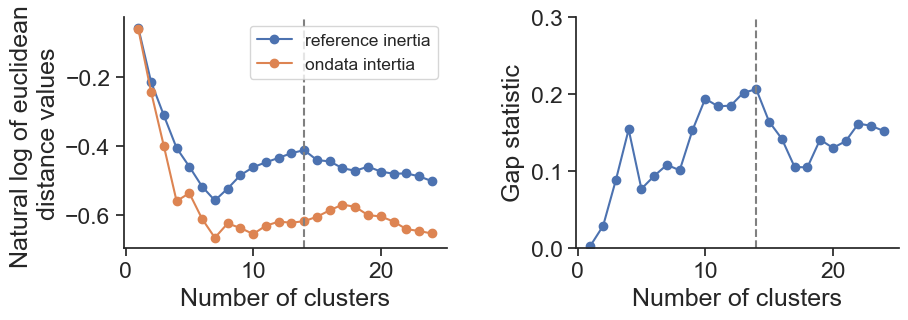

In [7]:
metric = 'euclidean'
shuffle_type = 'all'
k_max = 25

gap_filename = os.path.join(data_dir, f'gap_scores_{metric}_{glm_version}_nb20_unshuffled_to_{shuffle_type}.pkl')
with open(gap_filename, 'rb') as f:
    gap_dict = pickle.load(f)

plotting.plot_gap_statistic(gap_dict, cre_lines=['all'], n_clusters_cre=n_clusters, tag='with_cre_shuffle', save_dir=save_dir, folder='selecting_k_clusters')


loading eigengap values scores from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_clustering_results/eigengap_24_events_all_L2_optimize_by_session_kmax25_all.pkl
done


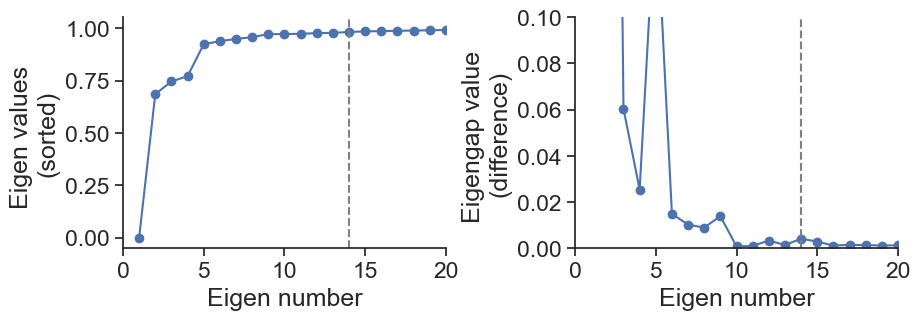

In [8]:

# Eigengap values
eigengap = processing.load_eigengap(glm_version, feature_matrix, cre_line='all', save_dir=data_dir, k_max=25)

plotting.plot_eigengap_values(eigengap, cre_lines=['all'], n_clusters_cre={'all': n_clusters}, save_dir=save_dir, folder='selecting_k_clusters')


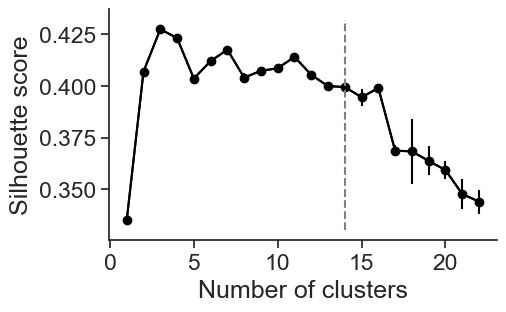

In [9]:

# Silhouette scores
n_clusters_range = np.arange(3, 25)
silhouette_filename = os.path.join(data_dir, f'silhouette_score_{n_clusters_range[0]}_{n_clusters_range[-1]}_clusters_metric_{metric}_nboots_20.pkl')

if os.path.exists(silhouette_filename):
    with open(silhouette_filename, 'rb') as f:
        silhouette_scores, silhouette_std = pickle.load(f)

    plotting.plot_silhouette_scores(
        silhouette_scores=silhouette_scores, silhouette_std=silhouette_std,
        n_clusters=n_clusters, save_dir=save_dir, folder='selecting_k_clusters')

#### Distribution of mice across clusters

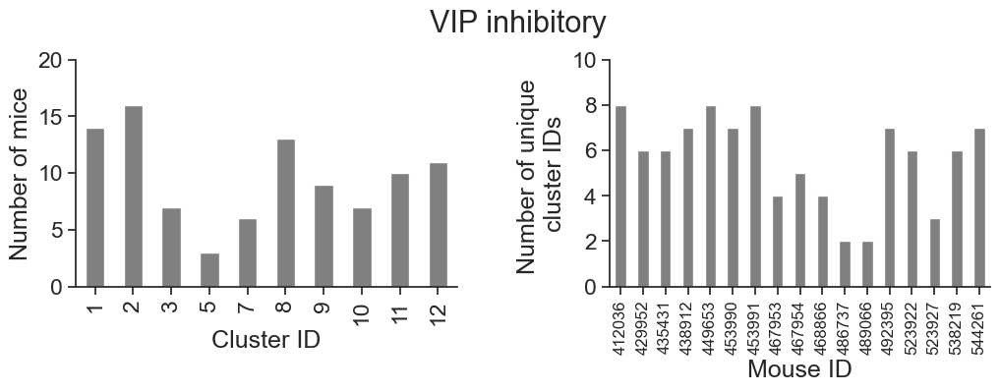

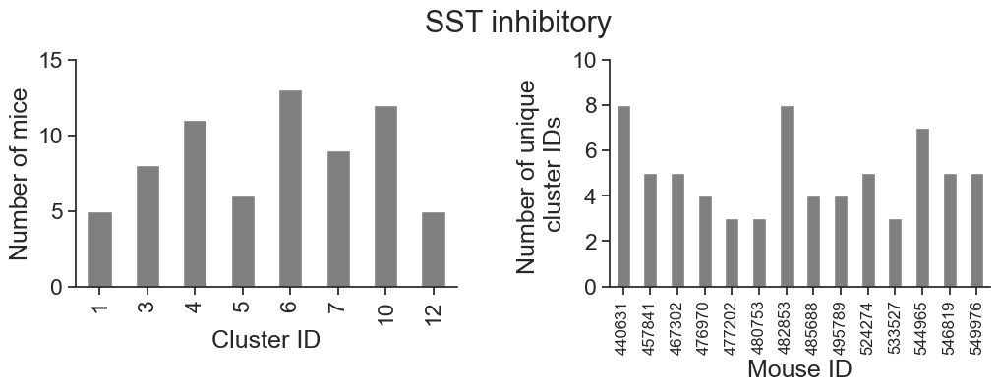

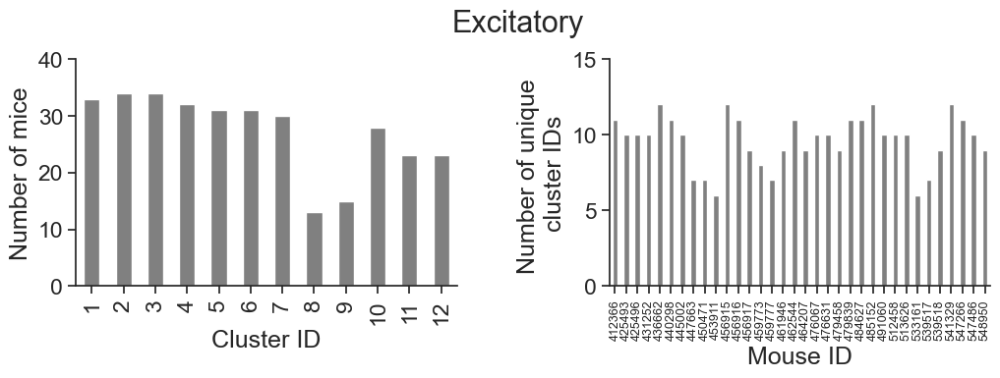

In [10]:
plotting.plot_cluster_breakdown_by_mouse(cluster_meta, save_dir=save_dir, folder='clustering_controls')

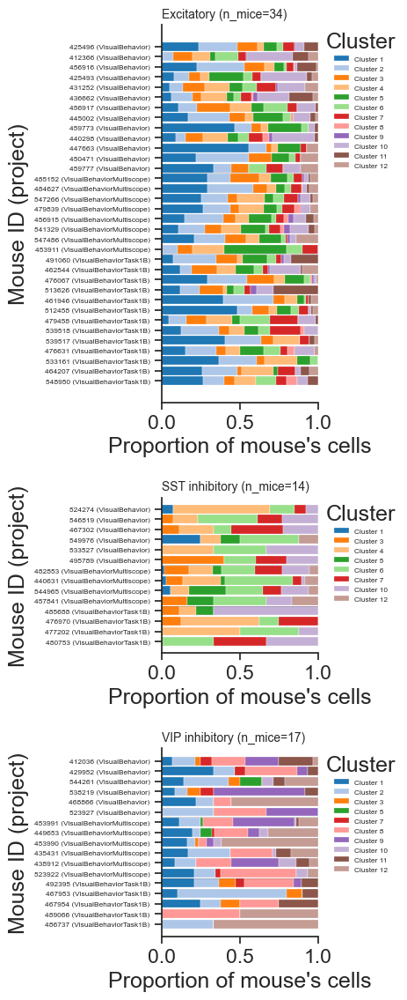

In [11]:

plotting.plot_cluster_composition_per_mouse_all_cell_types(cluster_meta, cre_lines, save_dir=save_dir)


#### UMAP


using provided umap_df


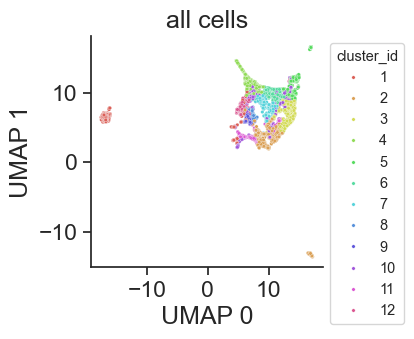

In [12]:
umap_filename = os.path.join(data_dir, 'umap_results_df.h5')
umap_df = pd.read_hdf(umap_filename, key='df')

# show all clusters in same plot
plotting.plot_umap_for_clusters(cluster_meta, feature_matrix, umap_df, label_col='cluster_id', cre_lines = ['all'],
                                save_dir=save_dir, folder='cluster_properties')

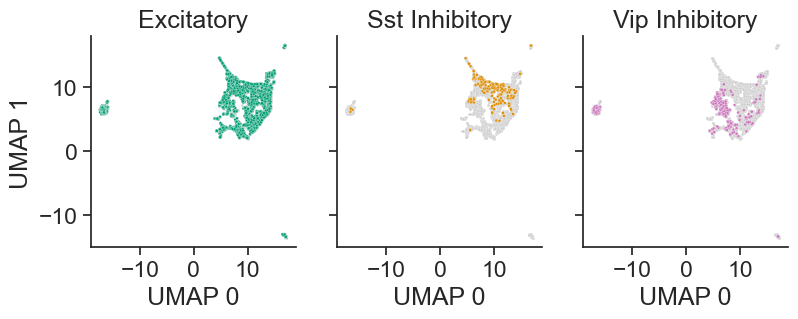

In [13]:

# UMAP for features separately
feature_colors = plotting.get_feature_colors_with_gray()
cell_type_colors = utils.get_cell_type_colors()
umap_filename = os.path.join(data_dir, 'umap_results_df.h5')
umap_df = pd.read_hdf(umap_filename, key='df')

plotting.plot_umap_for_features_separately(
    cluster_meta, feature_matrix, umap_df, label_col='cell_type',
    cmap=cell_type_colors, save_dir=save_dir, folder='clustering_results')


#### Within cluster correlation

In [14]:
# Compute within-cluster correlation (Pearson and Spearman) for each cell
cluster_meta = processing.add_within_cluster_corr_to_cluster_meta(
    feature_matrix, cluster_meta, use_spearmanr=False)
cluster_meta = cluster_meta.rename(columns={"within_cluster_correlation": "within_cluster_correlation_p"})
cluster_meta = processing.add_within_cluster_corr_to_cluster_meta(
    feature_matrix, cluster_meta, use_spearmanr=True)
cluster_meta = cluster_meta.rename(columns={"within_cluster_correlation": "within_cluster_correlation_s"})
# Keep a generic version for plotting
cluster_meta["within_cluster_correlation"] = cluster_meta["within_cluster_correlation_p"]

adding within cluster correlation to cluster_meta


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarnin

adding within cluster correlation to cluster_meta


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:788: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.arange(1, n_clusters+1))
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:788: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.arange(1, n_clusters+1))


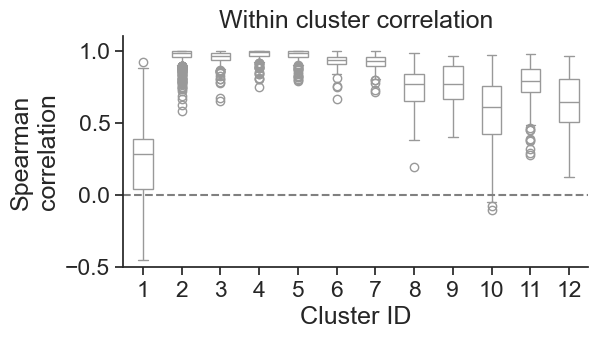

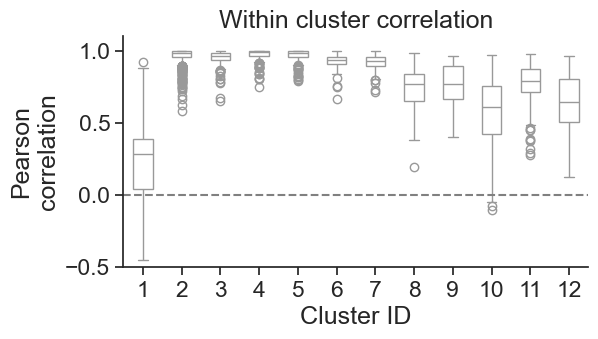

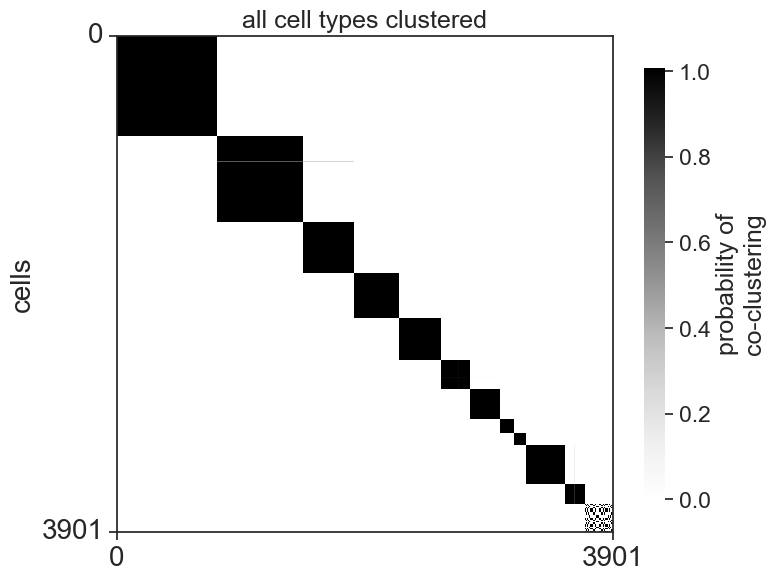

In [15]:
plotting.plot_within_cluster_correlations(
    cluster_meta, sort_order=None, spearman=True,
    suffix='_' + str(n_clusters) + '_clusters',
    save_dir=save_dir, folder='clustering_controls')

plotting.plot_within_cluster_correlations(
    cluster_meta, sort_order=None, spearman=False,
    suffix='_' + str(n_clusters) + '_clusters',
    save_dir=save_dir, folder='clustering_controls')

# Co-clustering matrix
coclustering_filename = os.path.join(
    data_dir, f'coclustering_matrix_n_{n_clusters}_clusters.h5')
if os.path.exists(coclustering_filename):
    coclustering_df = pd.read_hdf(coclustering_filename, key='df')
    coclustering_dict = {'all': coclustering_df}
    cluster_meta_tmp = cluster_meta.copy()
    cluster_meta_tmp['cre_line'] = 'all'

    plotting.plot_coclustering_matrix_sorted_by_cluster_size(
        coclustering_dict, cluster_meta_tmp, cre_line='all',
        save_dir=save_dir, folder='clustering_controls',
        suffix='_' + str(n_clusters) + '_clusters')


### Cluster properties

#### Coding scores & average responses

Generating Panel B: Cluster means...


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1570: FutureWarning: merging between different levels is deprecated and will be removed in a future version. (2 levels on the left, 1 on the right)
  cluster_means = feature_matrix.merge(cluster_meta[['cluster_id']], on='cell_specimen_id').groupby('cluster_id').mean()


<Axes: ylabel='Cluster ID'>

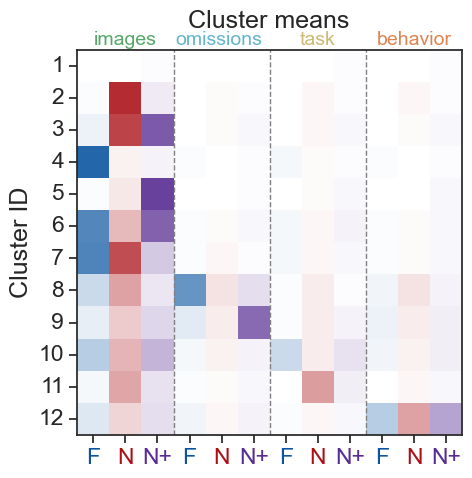

In [16]:
print("Generating Panel B: Cluster means...")
plotting.plot_cluster_means_remapped(
    feature_matrix,
    cluster_meta,
    save_dir=save_dir,
    folder='cluster_properties')


12


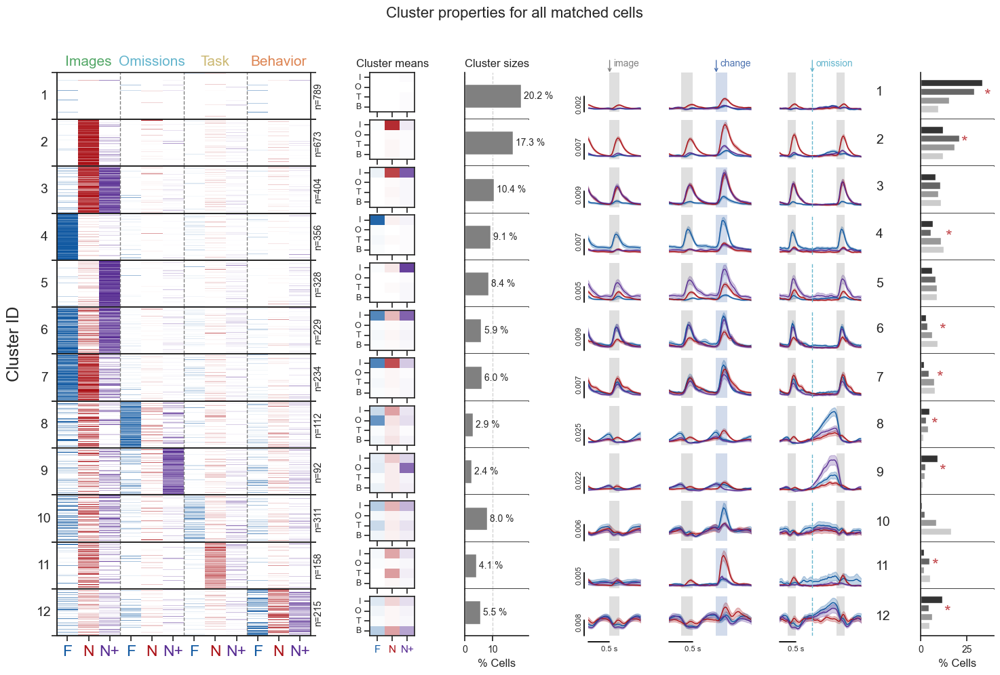

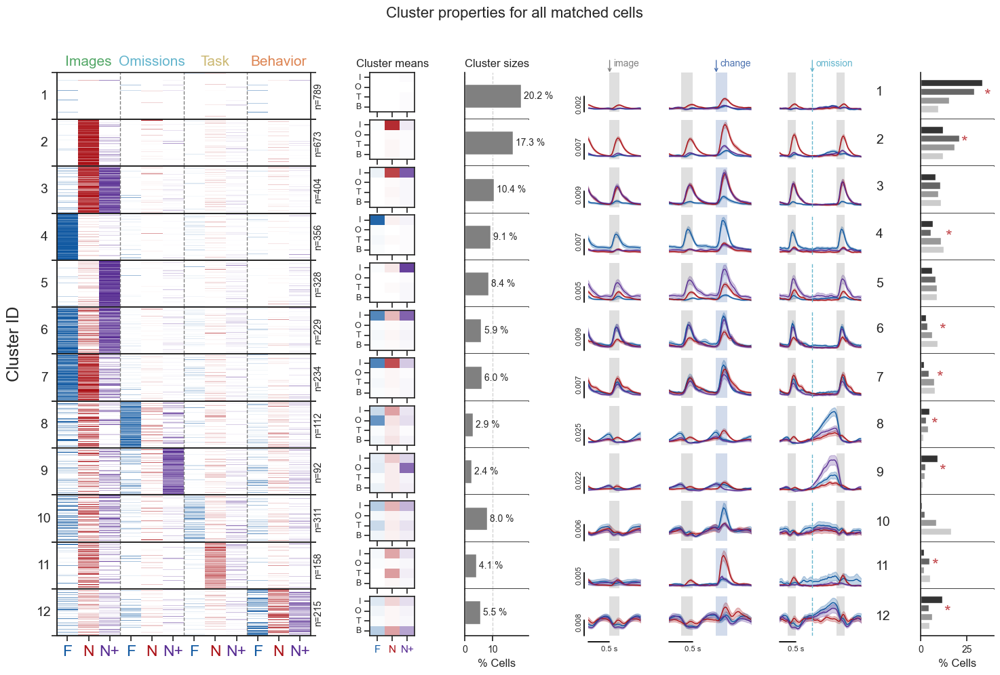

In [17]:
# All cre lines combined
tmp = cluster_meta.copy()
tmp['cre_line'] = 'all'

plotting.plot_cluster_properties_combined(
    tmp,
    feature_matrix,
    'all',
    image_mdf,
    change_mdf,
    omission_mdf,
    save_dir=save_dir, apply_peak_threshold=True)


12
6
7


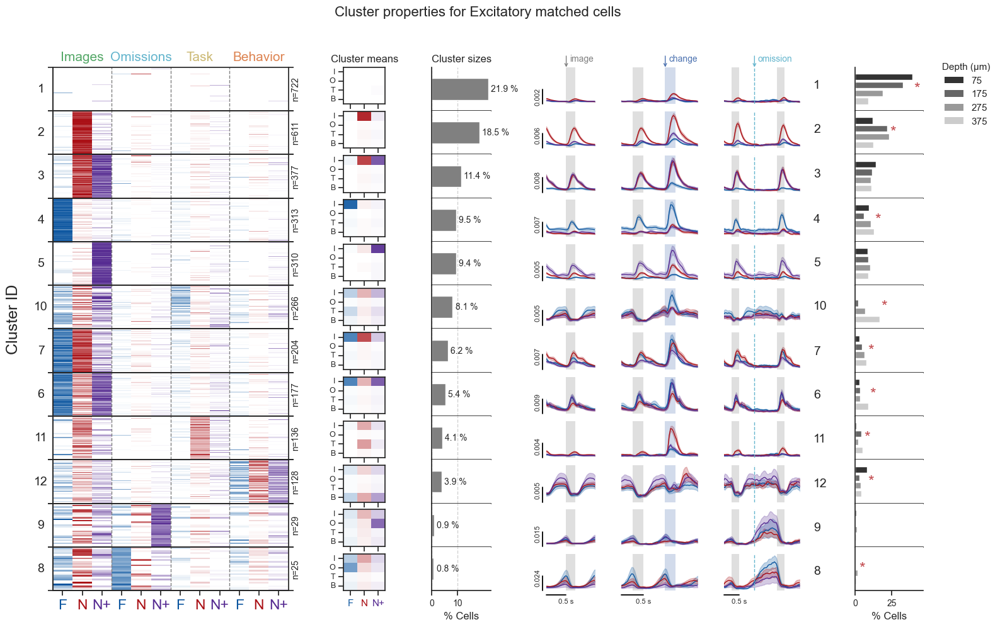

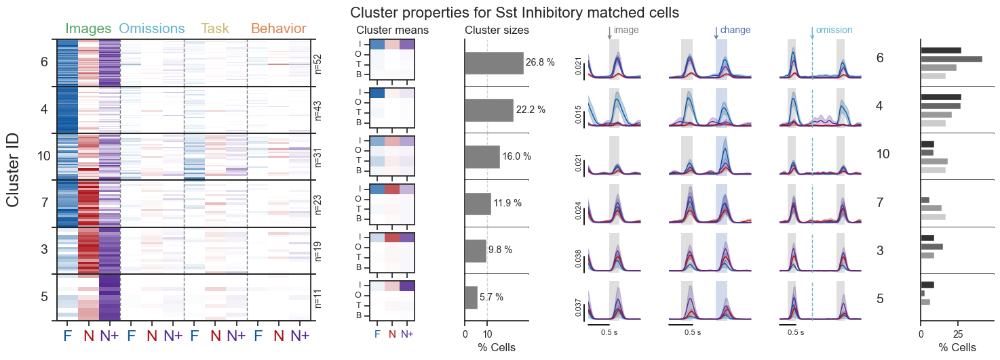

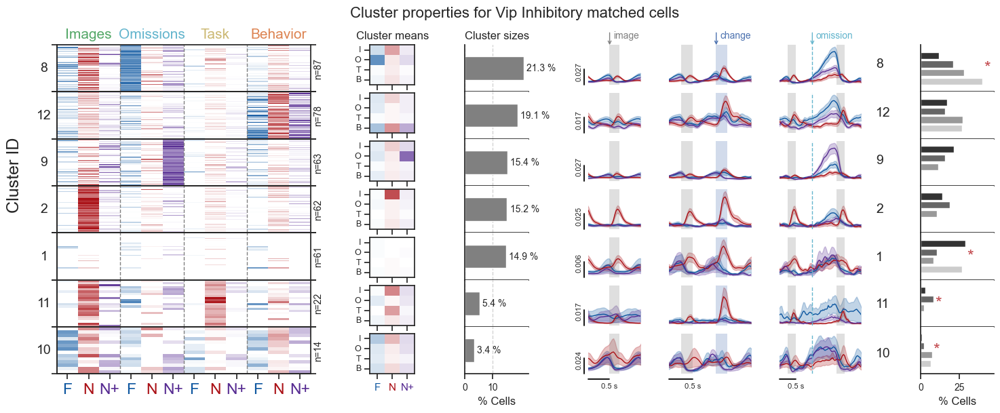

In [18]:

# By individual cre line
for cre_line in cre_lines:
    plotting.plot_cluster_properties_combined(
        cluster_meta,
        feature_matrix,
        cre_line,
        image_mdf,
        change_mdf,
        omission_mdf,
        save_dir=save_dir,
        sort_by='cluster_size', apply_peak_threshold=True)


#### Depth distributions for clusters

array([<Axes: title={'center': 'Exc'}, ylabel='Cluster ID'>,
       <Axes: title={'center': 'Sst'}, xlabel='Fraction cells in each area'>,
       <Axes: title={'center': 'Vip'}>], dtype=object)

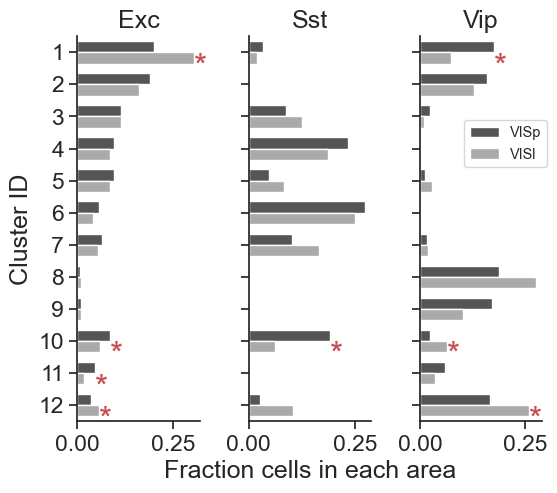

In [19]:
location = 'targeted_structure'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells in each area'

plotting.plot_cluster_depth_distribution_by_cre_lines(cluster_meta, location, metric, horiz=False,
                                                      ylabel=ylabel, save_dir=save_dir, folder='cluster_properties')

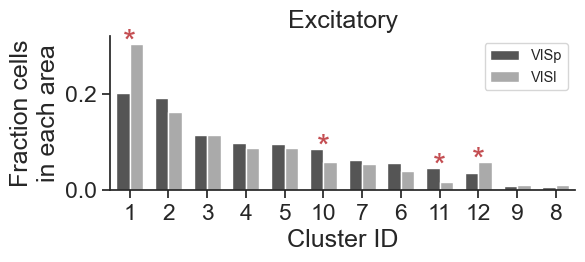

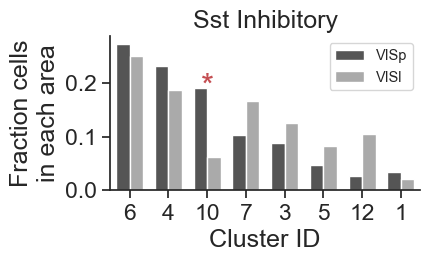

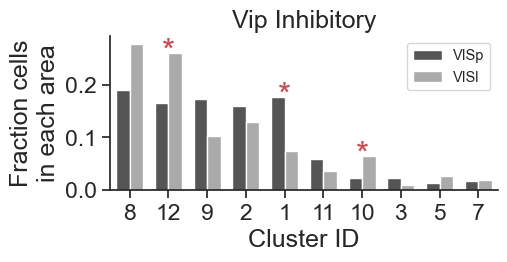

In [20]:
location = 'targeted_structure'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells\nin each area'

plotting.plot_cluster_depth_distribution_by_cre_line_separately(cluster_meta, location, cluster_order=None,
                                                            metric=metric, ylabel=ylabel, legend_title='', save_dir=save_dir, folder='cluster_properties')

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:5994: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax[i] = sns.barplot(data=cre_data, y='cluster_id', order=xorder, x=metric, orient='h',
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:5994: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax[i] = sns.barplot(data=cre_data, y='cluster_id', order=xorder, x=metric, orient='h',
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:5994: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax[i] = sns.barplot(data=cre_data, y='cluster_id', order=xorder, x=metric, orient='h',


array([<Axes: title={'center': 'Exc'}, ylabel='Cluster ID'>,
       <Axes: title={'center': 'Sst'}, xlabel='Fraction cells in each depth'>,
       <Axes: title={'center': 'Vip'}>], dtype=object)

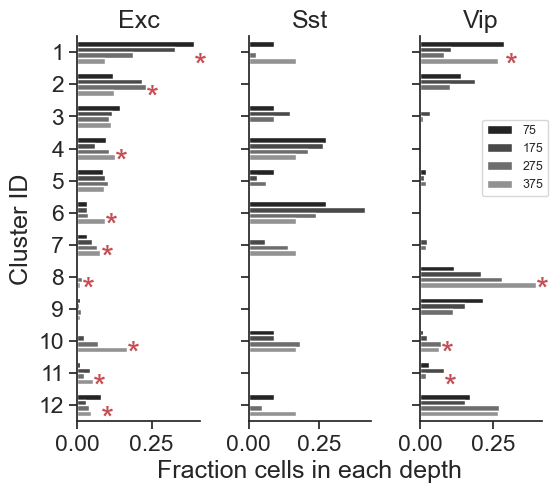

In [21]:
location = 'binned_depth'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells in each depth'

plotting.plot_cluster_depth_distribution_by_cre_lines(cluster_meta, location, metric, horiz=False,
                                                      ylabel=ylabel, save_dir=save_dir, folder='cluster_properties')

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:6089: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.barplot(data=cre_data, x='cluster_id', order=order, y=metric,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:6089: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.barplot(data=cre_data, x='cluster_id', order=order, y=metric,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:6089: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.barplot(data=cre_data, x='cluster_id', order=order, y=metric,


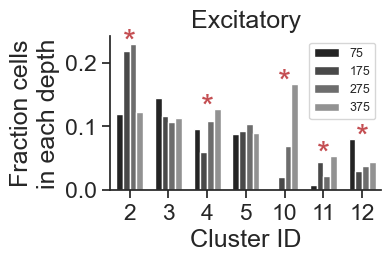

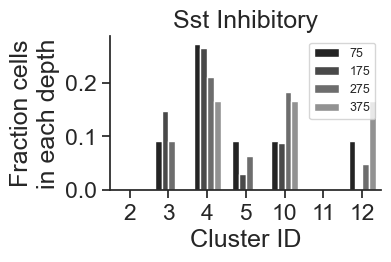

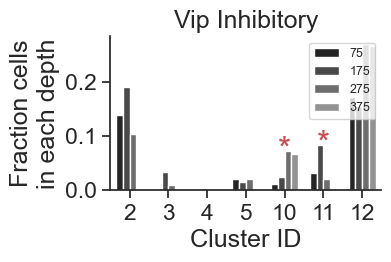

In [22]:
location = 'binned_depth'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells\nin each depth'


plotting.plot_cluster_depth_distribution_by_cre_line_separately(cluster_meta, location, cluster_order=[2, 3, 4, 5, 10, 11, 12],
                                                            metric=metric, ylabel=ylabel, legend_title='', save_dir=None, folder='cluster_properties')

In [23]:
n_cells_table = processing.get_cluster_proportion_stats_for_locations(cluster_meta, location=location)
n_cells_table[n_cells_table['n_cells_cluster'] > 10]

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  output = repr(obj)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/IPython/core/formatters.py:344: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  return method()


n_cells_location  \
cre_line          cluster_id binned_depth                     
Slc17a7-IRES2-Cre 1          75                          49   
                             175                        430   
                             275                        140   
                             375                        103   
                  2          75                          15   
...                                                     ...   
Vip-IRES-Cre      11         275                          2   
                  12         75                          16   
                             175                         32   
                             275                         26   
                             375                          4   

                                           n_cells_location_total  \
cre_line          cluster_id binned_depth                           
Slc17a7-IRES2-Cre 1          75                               125   
                             175                             1310   
                             275                              748   
                             375                             1115   
                  2          75                               125   
...                                                           ...   
Vip-IRES-Cre      11         275                               96   
                  12         75                                93   
                             175                              205   
                             275                               96   
                             375                               15   

                                           fraction_cells_location  \
cre_line          cluster_id binned_depth                            
Slc17a7-IRES2-Cre 1          75                           0.392000   
                             175                          0.328244   
                             275                          0.187166   
                             375                          0.092377   
                  2          75                           0.120000   
...                                                            ...   
Vip-IRES-Cre      11         275                          0.020833   
                  12         75                           0.172043   
                             175                          0.156098   
                             275                          0.270833   
                             375                          0.266667   

                                           percent_cells_location  \
cre_line          cluster_id binned_depth                           
Slc17a7-IRES2-Cre 1          75                         39.200000   
                             175                        32.824427   
                             275                        18.716578   
                             375                         9.237668   
                  2          75                         12.000000   
...                                                           ...   
Vip-IRES-Cre      11         275                         2.083333   
                  12         75                         17.204301   
                             175                        15.609756   
                             275                        27.083333   
                             375                        26.666667   

                                           n_cells_cluster  n_cells_cre  \
cre_line          cluster_id binned_depth                                 
Slc17a7-IRES2-Cre 1          75                        722         3298   
                             175                       722         3298   
                             275                       722         3298   
                             375                       722         3298   
                  2          75                        611        

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:6106: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.barplot(data=cre_data, y='cluster_id', order=order, x=metric, orient='h',
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:6106: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.barplot(data=cre_data, y='cluster_id', order=order, x=metric, orient='h',
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:6106: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  ax = sns.barplot(data=cre_data, y='cluster_id', order=order, x=metric, orient='h',


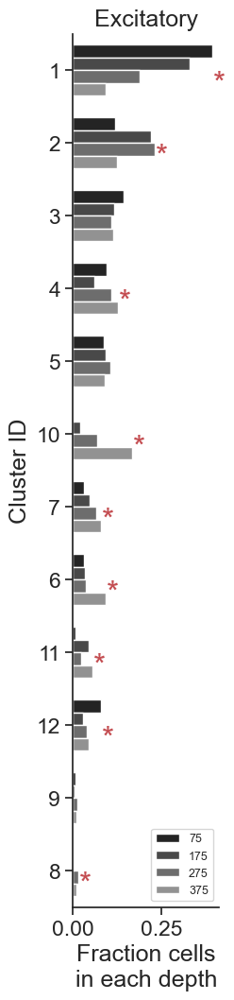

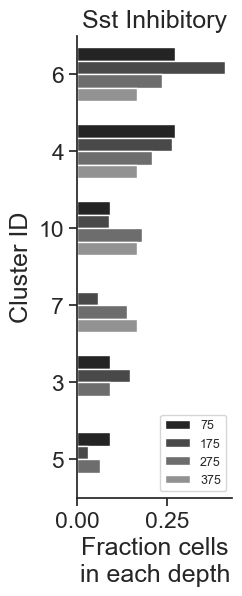

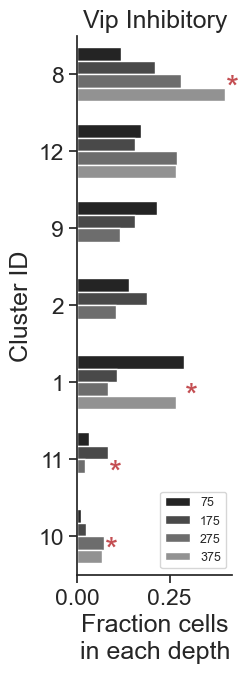

In [24]:
location = 'binned_depth'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells\nin each depth'


plotting.plot_cluster_depth_distribution_by_cre_line_separately(cluster_meta, location, cluster_order=None, horiz=False, size_threshold=10,
                                                            metric=metric, ylabel=ylabel, legend_title='', save_dir=save_dir, folder='cluster_properties')

In [25]:
location = 'binned_depth'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells in each depth'

n_cells_table = processing.get_cluster_proportion_stats_for_locations(cluster_meta, location=location)
n_cells_table = n_cells_table.reset_index()

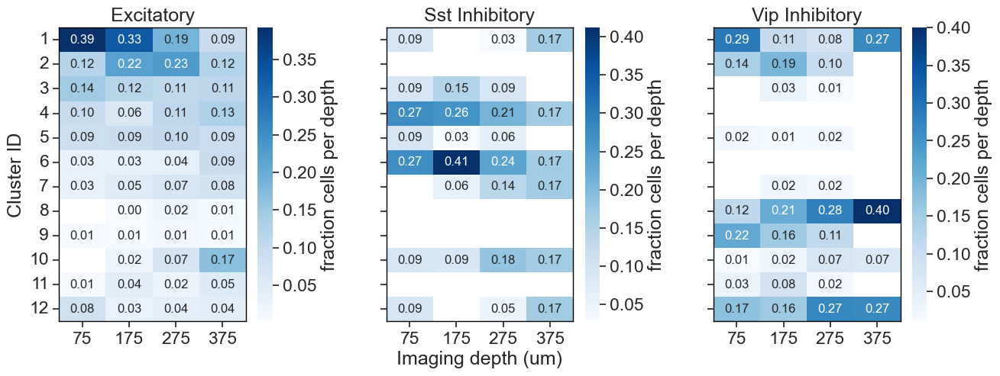

In [26]:
fig, ax = plt.subplots(1,3, figsize=(15,5), sharey=True)
for i, cre_line in enumerate(cre_lines): 
    cell_type = utils.convert_cre_line_to_cell_type(cre_line)
    data = n_cells_table[n_cells_table.cre_line==cre_line]
    pivot = data.pivot_table(index='cluster_id', columns='binned_depth', values='fraction_cells_location')
    # fill in blank values
    for cluster_id in np.arange(1, 13,1): 
        if cluster_id not in pivot.index.values: 
            pivot.loc[cluster_id] = np.nan
    # order
    pivot = pivot.loc[np.arange(1, 13,1)]
    ax[i] = sns.heatmap(pivot, cmap='Blues', ax=ax[i], 
                        annot=True, fmt=".2f", annot_kws={"fontsize": 12},
                        cbar_kws={'label':'fraction cells per depth'})
    ax[i].set_yticklabels(pivot.index.values, rotation=0)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title(cell_type)
ax[0].set_ylabel('Cluster ID')
ax[1].set_xlabel('Imaging depth (um)')
for i in range(3):
    for _, spine in ax[i].spines.items():
        spine.set_visible(True)
        spine.set_color('black')  # Set the color of the box
        spine.set_linewidth(1) 
fig.subplots_adjust(wspace=0.4)

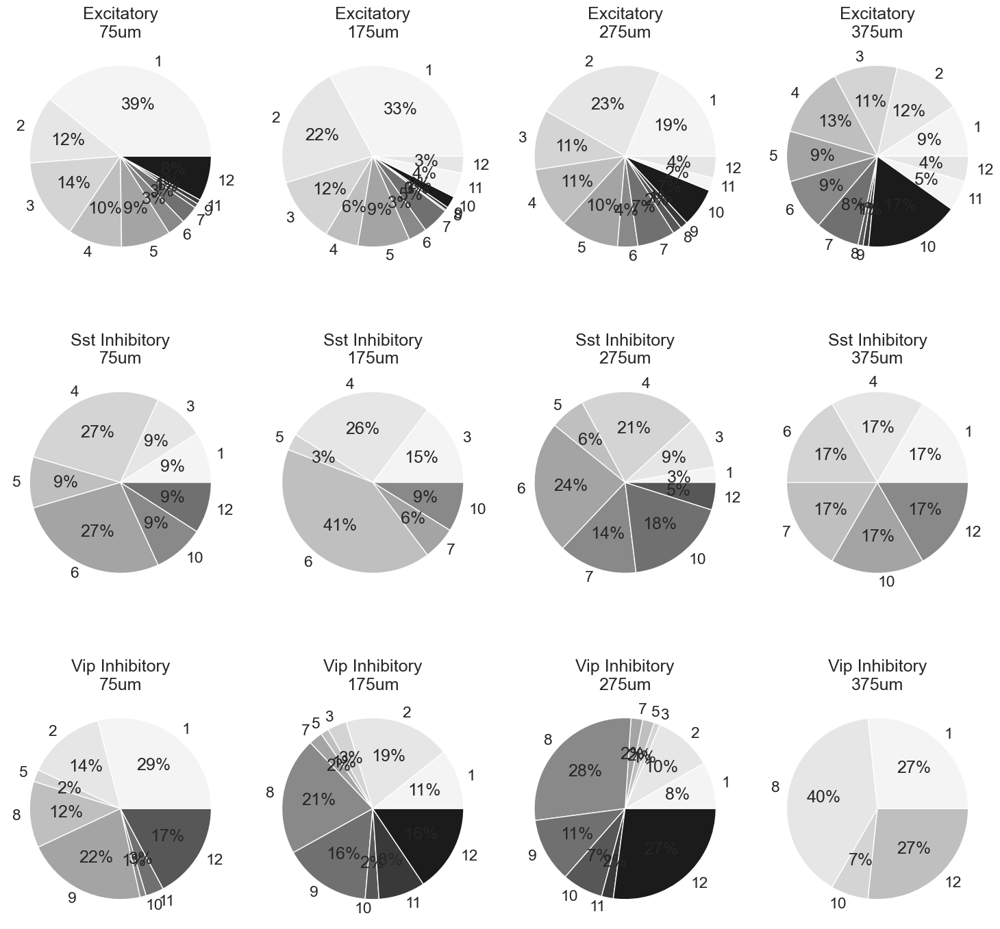

In [27]:
plotting.plot_proportion_cells_per_depth_pie_chart(cluster_meta, save_dir=None, folder=None)

In [28]:
def get_pivoted_data_for_cell_counts(n_cells_table, cre_line, cluster_ids=np.arange(1,13,1),
                                     column='binned_depth', value='fraction_cells_location'):
    data = n_cells_table[n_cells_table.cre_line==cre_line]
    pivot = data.pivot_table(index='cluster_id', columns=column, values=value)
    # fill in blank values
    for cluster_id in cluster_ids: 
        if cluster_id not in pivot.index.values: 
            pivot.loc[cluster_id] = np.nan
    # order numerically
    pivot = pivot.loc[cluster_ids]
    return pivot

get_pivoted_data_for_cell_counts(n_cells_table, cre_line, value='fraction_cells_location')

binned_depth,75,175,275,375
cluster_id,,,,
1,0.290323,0.107317,0.083333,0.266667
2,0.139785,0.190244,0.104167,NaN
3,NaN,0.034146,0.010417,NaN
4,NaN,NaN,NaN,NaN
5,0.021505,0.014634,0.020833,NaN
6,NaN,NaN,NaN,NaN
7,NaN,0.024390,0.020833,NaN
8,0.118280,0.209756,0.281250,0.400000
9,0.215054,0.156098,0.114583,NaN


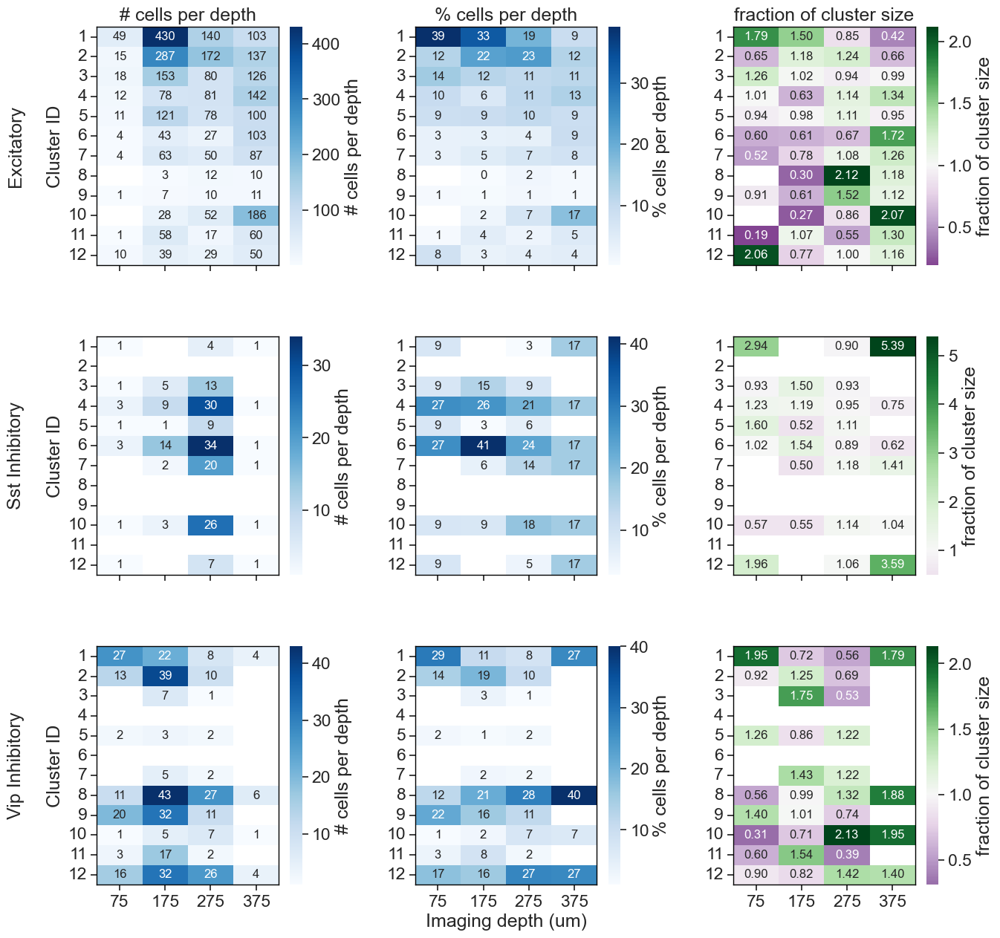

In [29]:

cluster_ids = np.sort(n_cells_table.cluster_id.unique())

fig, ax = plt.subplots(3, 3, figsize=(15, 15), sharey=False, sharex=True)
ax = ax.ravel()
i=0
for c, cre_line in enumerate(cre_lines): 
    cell_type = utils.convert_cre_line_to_cell_type(cre_line)
    pivot = get_pivoted_data_for_cell_counts(n_cells_table, cre_line, value='n_cells_location', cluster_ids=cluster_ids)
    ax[i] = sns.heatmap(pivot, cmap='Blues', ax=ax[i], annot=True, fmt=".0f", annot_kws={"fontsize": 12},
                        cbar_kws={'label':'# cells per depth'})
    ax[i].set_ylabel(cell_type+'\n\nCluster ID')
    if c==0: 
        ax[i].set_title('# cells per depth')
    i+=1
    pivot = get_pivoted_data_for_cell_counts(n_cells_table, cre_line, value='percent_cells_location', cluster_ids=cluster_ids)
    ax[i] = sns.heatmap(pivot, cmap='Blues', ax=ax[i], annot=True, fmt=".0f", annot_kws={"fontsize": 12},
                        cbar_kws={'label':'% cells per depth'})
    ax[i].set_ylabel('')
    if c==0: 
        ax[i].set_title('% cells per depth')
    i+=1
    pivot = get_pivoted_data_for_cell_counts(n_cells_table, cre_line, value='fraction_of_cluster_size', cluster_ids=cluster_ids)
    ax[i] = sns.heatmap(pivot, cmap='PRGn', center=1, ax=ax[i], annot=True, fmt=".2f", annot_kws={"fontsize": 12},
                        cbar_kws={'label':'fraction of cluster size'})
    ax[i].set_ylabel('')
    if c==0: 
        ax[i].set_title('fraction of cluster size')
    i+=1

for i in range(9):
    ax[i].set_xlabel('') 
    ax[i].set_yticklabels(cluster_ids, rotation=0)
    for _, spine in ax[i].spines.items():
        spine.set_visible(True)
        spine.set_color('black')  # Set the color of the box
        spine.set_linewidth(1)   
ax[7].set_xlabel('Imaging depth (um)')
fig.subplots_adjust(hspace=0.3, wspace=0.4)

#### Kernel weights for clusters

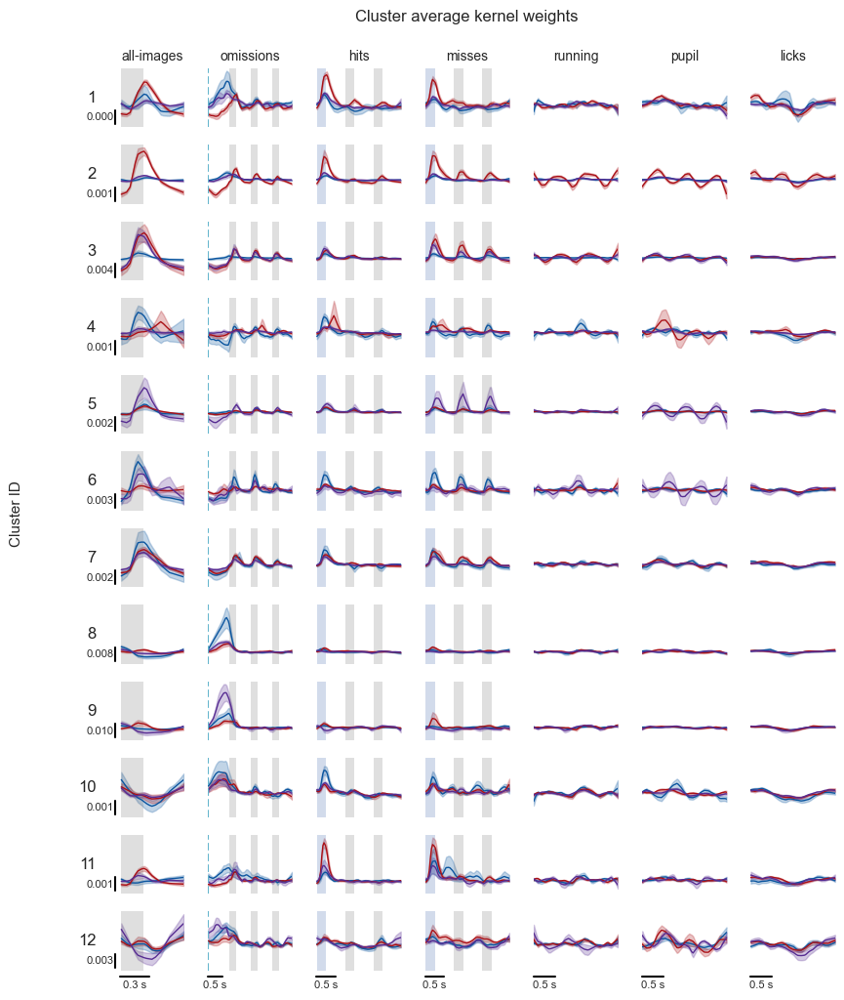

In [30]:
kernels_for_overlay_plot = ['all-images', 'omissions', 'hits', 'misses', 'running', 'pupil', 'licks']

fig, axes = plotting.plot_cluster_kernel_overlays_by_experience(
    weights_df,
    run_params,
    kernels_to_plot=None,
    linewidth=1,
    share_y_across="row",
    cell_type=None,
    show_all_clusters=False,
    min_cluster_fraction=0,
)
plt.show()

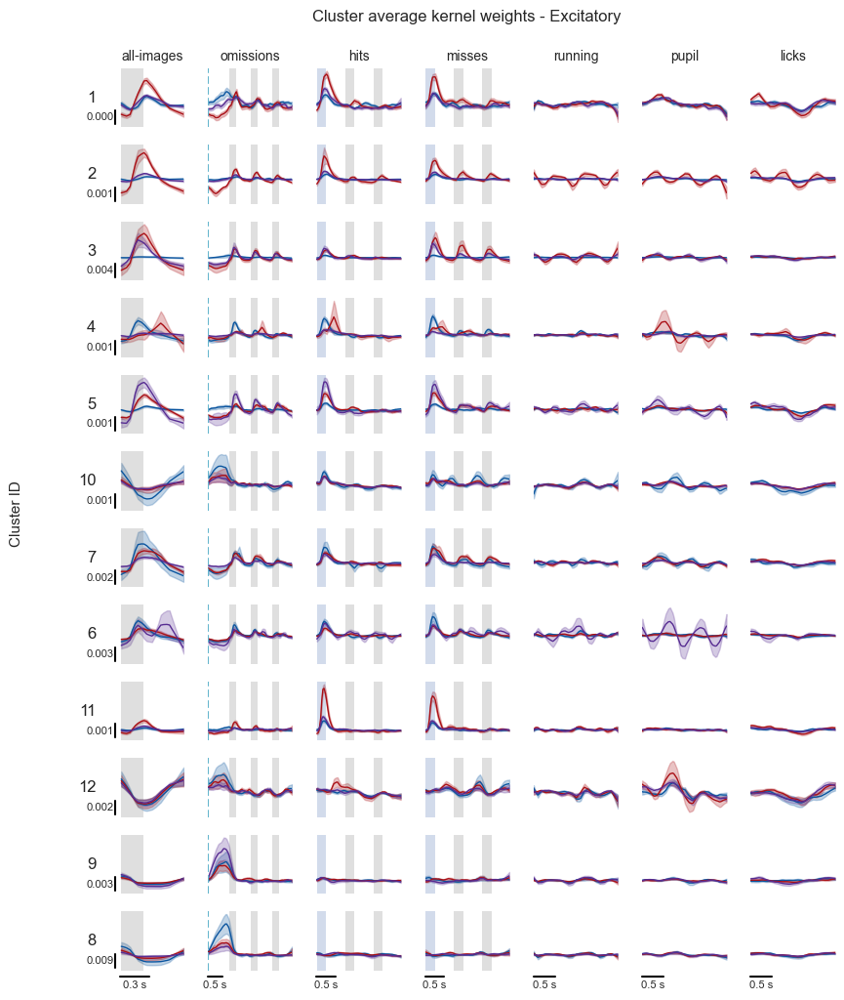

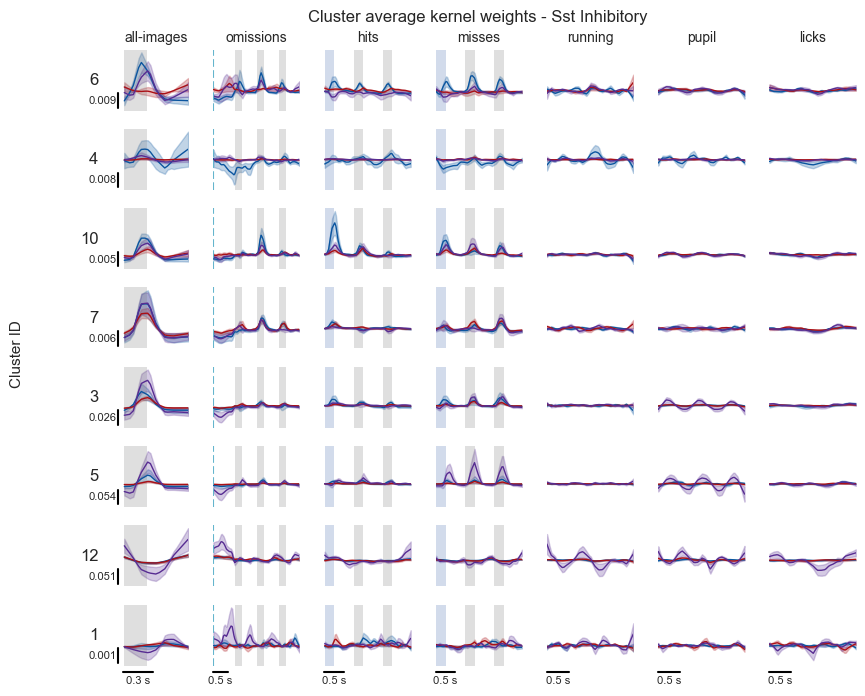

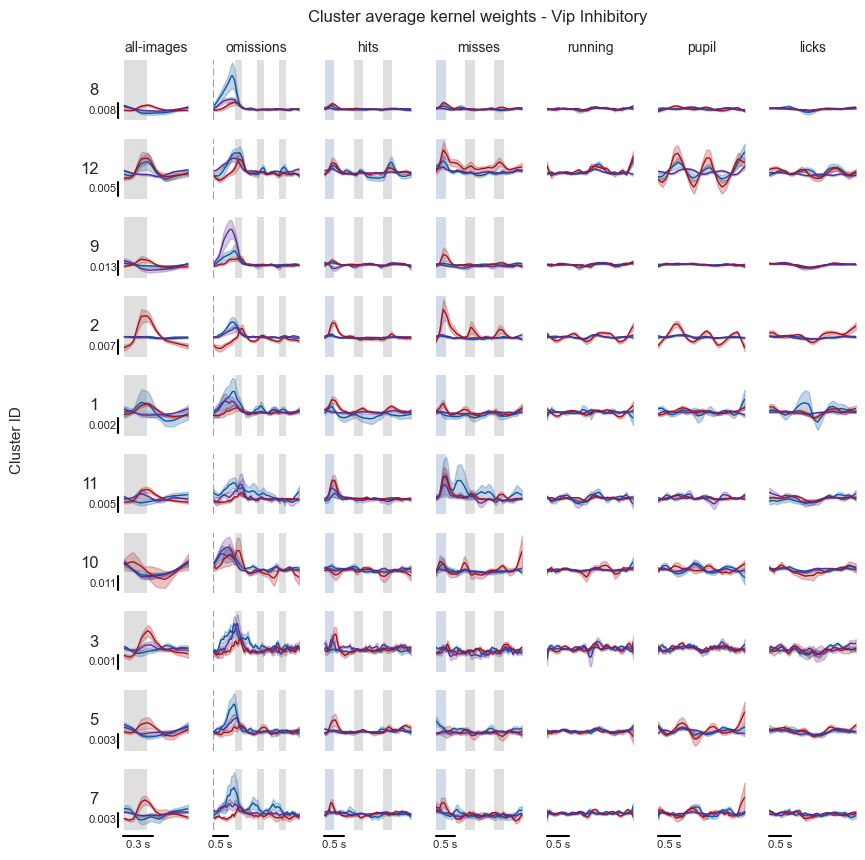

In [31]:
kernels_for_overlay_plot = ['all-images', 'omissions', 'hits', 'misses', 'running', 'pupil', 'licks']

for cell_type in cell_types:
    fig, axes = plotting.plot_cluster_kernel_overlays_by_experience(
        weights_df,
        run_params,
        kernels_to_plot=None,
        linewidth=1,
        share_y_across="row",
        cell_type=cell_type,
        show_all_clusters=False,
        min_cluster_fraction=0.04,
    )
    plt.show()

#### Response heatmaps for clusters

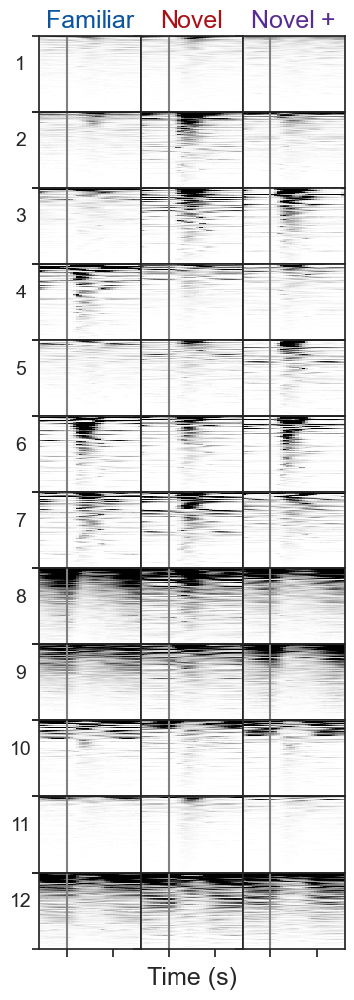

In [32]:
# Response heatmaps for all cells 
plotting.plot_cell_response_heatmaps_for_clusters(image_mdf, data_type='events', event_type='images', 
                                                vmax=0.0005, xlim_seconds=[-0.3, 0.8], ax=None);

#### Activity Metrics for Clusters

Distribution of model-free response metrics for each cluster, separated by experience level and cell type.
Metrics include: image selectivity (lifetime sparseness), response reliability, change modulation,
choice modulation (hit vs miss), omission modulation, and running modulation.

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)


array([<Axes: title={'center': 'Excitatory'}, xlabel='Cluster ID', ylabel='Image selectivity'>,
       <Axes: title={'center': 'Sst Inhibitory'}, xlabel='Cluster ID'>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Cluster ID'>],
      dtype=object)

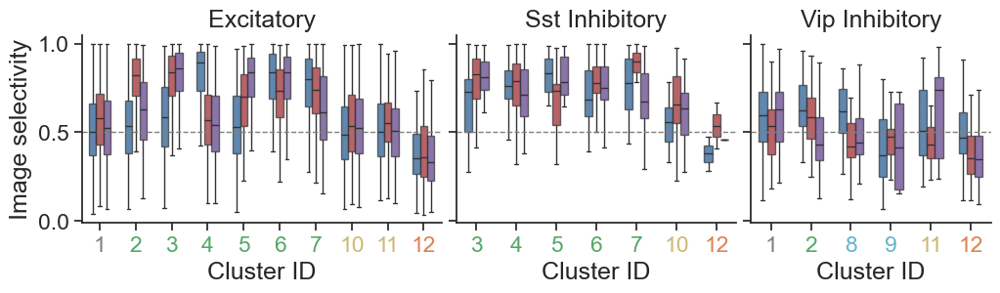

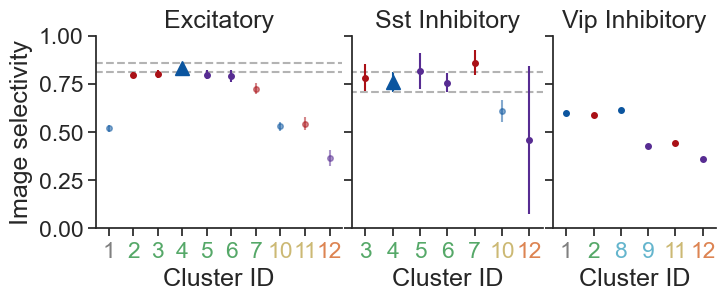

In [33]:
metric = 'lifetime_sparseness_images'
ylabel = 'Image selectivity'
title = 'Image selectivity'
group_to_compare = 4

plotting.plot_response_metrics_boxplot_by_cre(response_metrics, metric, cluster_meta, ylabel=ylabel, 
                                              horiz=True, match_clusters=False, line_val=0.5, save_dir=save_dir)


plotting.plot_tukey_diff_in_means_for_metric(response_metrics, metric, cluster_meta=cluster_meta, 
                                                match_clusters=False, min_cluster_fraction=0.04,
                                                horiz=True, lims=(0, 1),
                                                title=title, xlabel=ylabel, group_to_compare=group_to_compare,
                                                pref_exp_level=True, split_by_cre=True, save_dir=save_dir)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)


array([<Axes: title={'center': 'Excitatory'}, xlabel='Cluster ID', ylabel='Response reliability'>,
       <Axes: title={'center': 'Sst Inhibitory'}, xlabel='Cluster ID'>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Cluster ID'>],
      dtype=object)

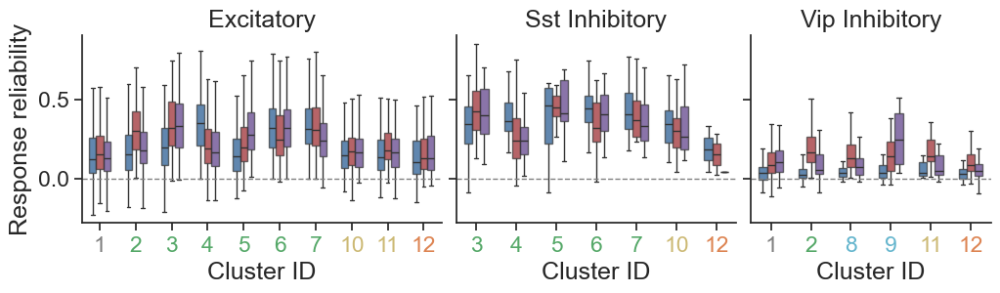

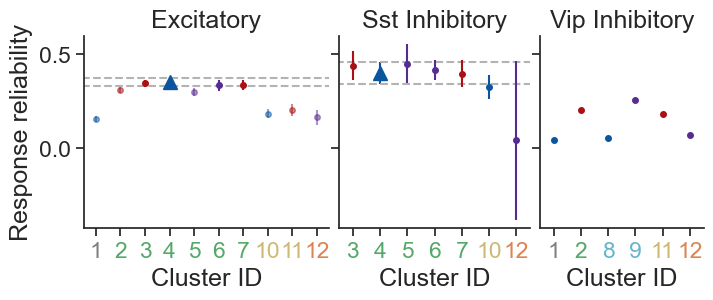

In [34]:
metric = 'reliability_pref_image'
ylabel = 'Response reliability'

plotting.plot_response_metrics_boxplot_by_cre(response_metrics, metric, cluster_meta, ylabel=ylabel, horiz=True, match_clusters=False, line_val=0, save_dir=save_dir)


plotting.plot_tukey_diff_in_means_for_metric(response_metrics, metric, cluster_meta=cluster_meta, 
                                                match_clusters=False, min_cluster_fraction=0.04,
                                                horiz=True, lims=None,
                                                title=title, xlabel=ylabel, group_to_compare=group_to_compare,
                                                pref_exp_level=True, split_by_cre=True, save_dir=save_dir)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)


array([<Axes: title={'center': 'Excitatory'}, xlabel='Cluster ID', ylabel='Change modulation'>,
       <Axes: title={'center': 'Sst Inhibitory'}, xlabel='Cluster ID'>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Cluster ID'>],
      dtype=object)

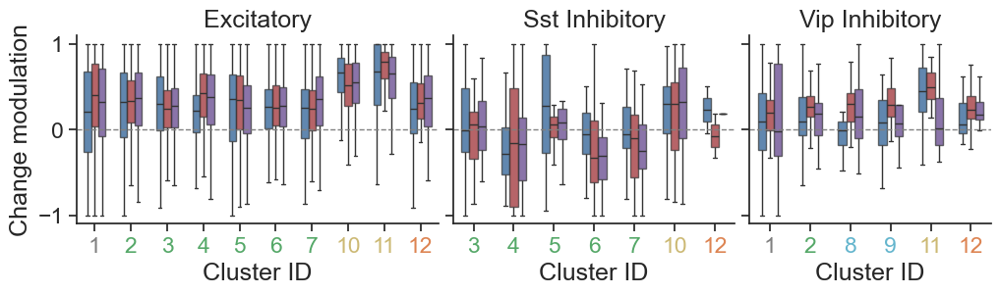

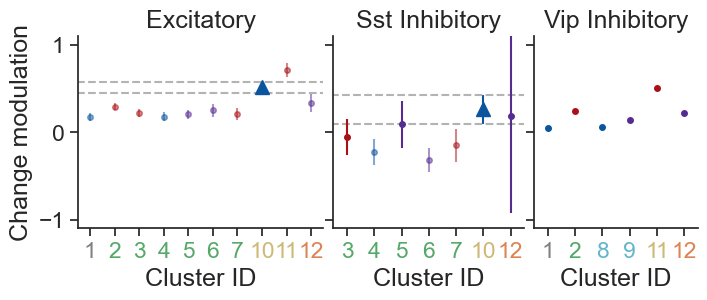

In [35]:
metric = 'change_modulation_index'
ylabel = 'Change modulation'
group_to_compare = 10

plotting.plot_response_metrics_boxplot_by_cre(response_metrics, metric, cluster_meta, ylabel=ylabel, horiz=True, match_clusters=False, line_val=0, save_dir=save_dir)

plotting.plot_tukey_diff_in_means_for_metric(response_metrics, metric, cluster_meta=cluster_meta, 
                                                match_clusters=False, min_cluster_fraction=0.04,
                                                horiz=True, lims=(-1.1, 1.1),
                                                title=title, xlabel=ylabel, group_to_compare=group_to_compare,
                                                pref_exp_level=True, split_by_cre=True, save_dir=save_dir)


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)


array([<Axes: title={'center': 'Excitatory'}, xlabel='Cluster ID', ylabel='Choice modulation'>,
       <Axes: title={'center': 'Sst Inhibitory'}, xlabel='Cluster ID'>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Cluster ID'>],
      dtype=object)

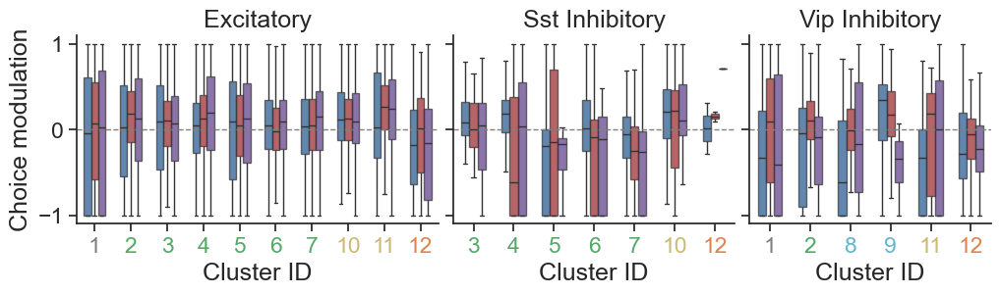

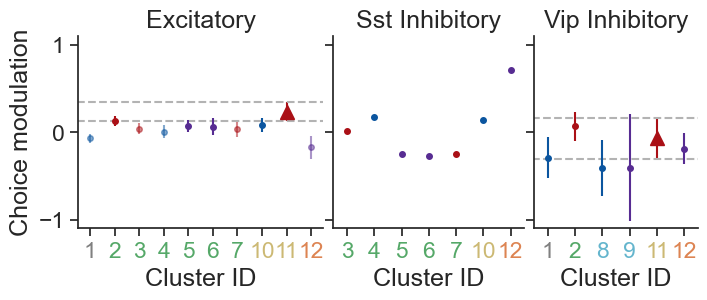

In [36]:
metric = 'hit_miss_index'
ylabel = 'Choice modulation'
group_to_compare = 11

plotting.plot_response_metrics_boxplot_by_cre(response_metrics, metric, cluster_meta, ylabel=ylabel, horiz=True, match_clusters=False, line_val=0, save_dir=save_dir)

plotting.plot_tukey_diff_in_means_for_metric(response_metrics, metric, cluster_meta=cluster_meta, 
                                                match_clusters=False, min_cluster_fraction=0.04,
                                                horiz=True, lims=(-1.1, 1.1),
                                                title=title, xlabel=ylabel, group_to_compare=group_to_compare,
                                                pref_exp_level=True, split_by_cre=True, save_dir=save_dir)


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)


array([<Axes: title={'center': 'Excitatory'}, xlabel='Cluster ID', ylabel='Omission modulation'>,
       <Axes: title={'center': 'Sst Inhibitory'}, xlabel='Cluster ID'>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Cluster ID'>],
      dtype=object)

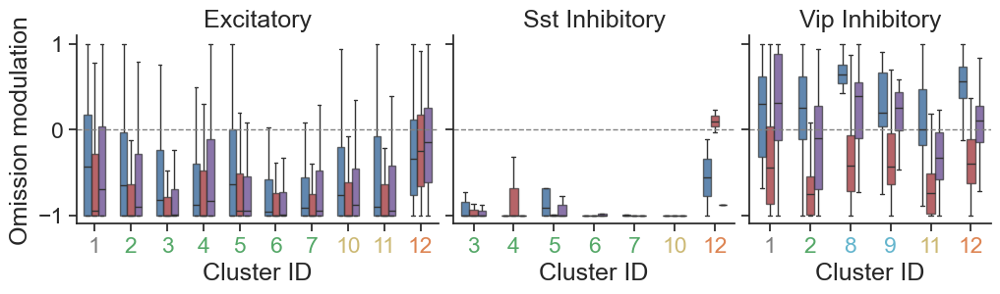

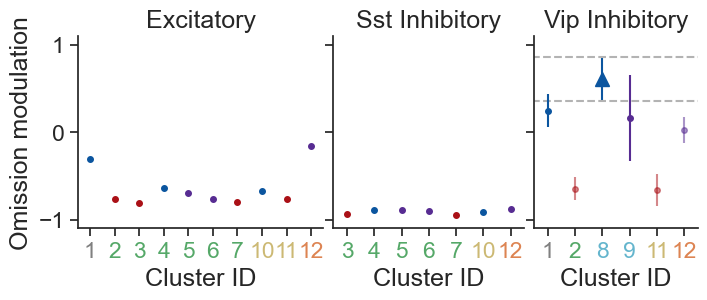

In [37]:
metric = 'omission_modulation_index'
ylabel = 'Omission modulation'
group_to_compare = 8

plotting.plot_response_metrics_boxplot_by_cre(response_metrics, metric, cluster_meta, ylabel=ylabel, horiz=True, match_clusters=False, line_val=0, save_dir=save_dir)

plotting.plot_tukey_diff_in_means_for_metric(response_metrics, metric, cluster_meta=cluster_meta, 
                                                match_clusters=False, min_cluster_fraction=0.04,
                                                horiz=True, lims=(-1.1, 1.1),
                                                title=title, xlabel=ylabel, group_to_compare=group_to_compare,
                                                pref_exp_level=True, split_by_cre=True, save_dir=save_dir)



/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)


array([<Axes: title={'center': 'Excitatory'}, xlabel='Cluster ID', ylabel='Running modulation'>,
       <Axes: title={'center': 'Sst Inhibitory'}, xlabel='Cluster ID'>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Cluster ID'>],
      dtype=object)

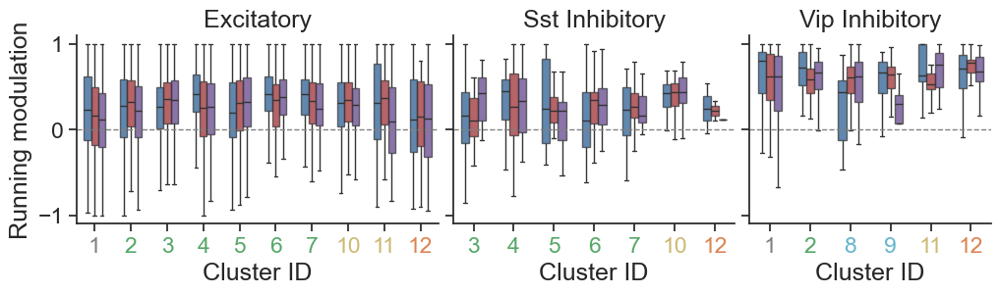

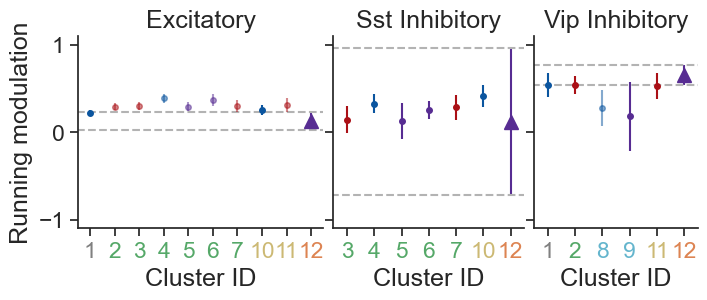

In [38]:
metric = 'running_modulation_all_images'
ylabel = 'Running modulation'
group_to_compare = 12

plotting.plot_response_metrics_boxplot_by_cre(response_metrics, metric, cluster_meta, ylabel=ylabel, horiz=True, match_clusters=False, line_val=0, save_dir=save_dir)

plotting.plot_tukey_diff_in_means_for_metric(response_metrics, metric, cluster_meta=cluster_meta, 
                                                match_clusters=False, min_cluster_fraction=0.04,
                                                horiz=True, lims=(-1.1, 1.1),
                                                title=title, xlabel=ylabel, group_to_compare=group_to_compare,
                                                pref_exp_level=True, split_by_cre=True, save_dir=save_dir)



#### Experience modulation across clusters

Generating Panel F: Experience modulation...
loading coding score metrics table


<Axes: title={'center': 'Novelty modulation'}, xlabel='Cluster ID', ylabel='<- Familiar --- Novel ->'>

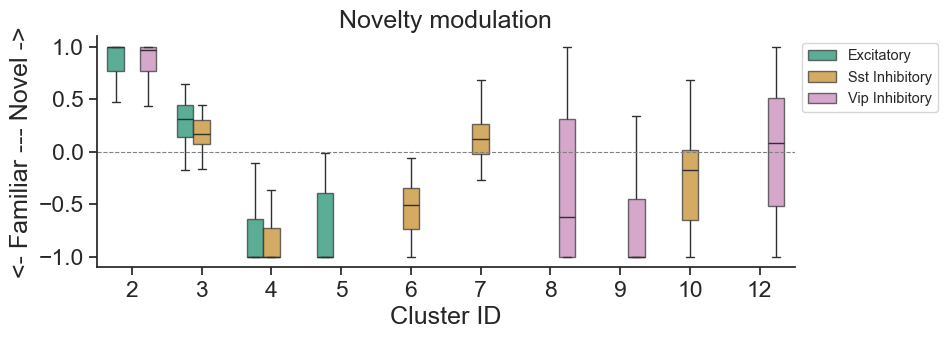

In [39]:
print("Generating Panel F: Experience modulation...")

# Generate coding score metrics
coding_score_metrics = processing.generate_coding_score_metrics_table(
    cluster_meta,
    results_pivoted,
    save_dir=loading.get_cell_metrics_dir(),)

# Filter to clusters with sufficient cell counts per cre line
# Compute cluster proportions per cre line
_counts = cluster_meta.groupby(['cre_line', 'cluster_id']).size().reset_index(name='n_cells')
_totals = cluster_meta.groupby('cre_line').size().reset_index(name='n_cells_total')
n_cells_per_cluster = _counts.merge(_totals, on='cre_line')
n_cells_per_cluster['fraction_per_cluster'] = n_cells_per_cluster['n_cells'] / n_cells_per_cluster['n_cells_total']
small_clusters = n_cells_per_cluster[
    n_cells_per_cluster.fraction_per_cluster < 0.09
].set_index(['cre_line', 'cluster_id']).index.values
small_clusters = np.unique(small_clusters)

coding_score_metrics_filtered = coding_score_metrics.copy()
for small_cluster in small_clusters:
    csids = coding_score_metrics[
        (coding_score_metrics.cre_line == small_cluster[0]) &
        (coding_score_metrics.cluster_id == small_cluster[1])
    ].index.values
    coding_score_metrics_filtered = coding_score_metrics_filtered.drop(index=csids)

# Remove non-coding cluster
csids = coding_score_metrics_filtered[coding_score_metrics_filtered.cluster_id == 1].index.values
coding_score_metrics_filtered = coding_score_metrics_filtered.drop(index=csids)

# Plot experience modulation
plotting.plot_experience_modulation(
    coding_score_metrics_filtered,
    metric='experience_modulation',
    save_dir=save_dir,
    folder='cluster_properties')


loading coding score metrics table


<Axes: title={'center': 'Novelty modulation'}, xlabel='Cluster ID', ylabel='<- Familiar --- Novel ->'>

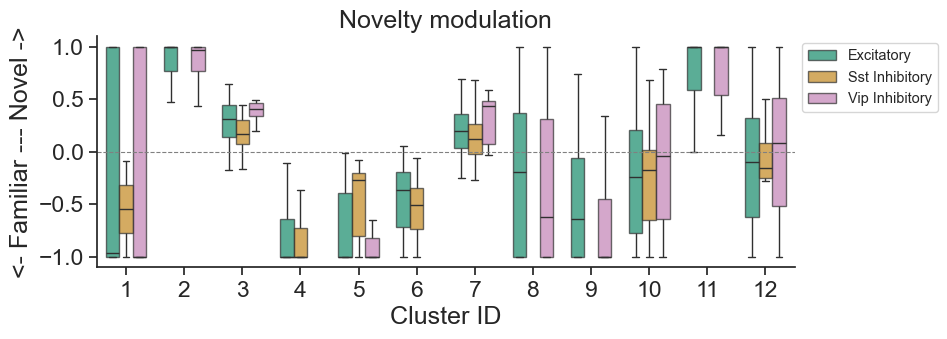

In [40]:
# load pre-saved coding score metrics 
coding_score_metrics = processing.generate_coding_score_metrics_table(cluster_meta, results_pivoted, 
                                                                      save_dir=clustering_results)

# metric comparing N to avg of F and N+
plotting.plot_experience_modulation(coding_score_metrics, metric='experience_modulation', save_dir=None, 
                                    folder='metric_distributions', suffix='_all_clusters')

In [41]:
# --- free memory: results_pivoted is no longer needed (its data was merged into
#     response_metrics / metrics above); drop it so it isn't held through the composites ---
import gc
globals().pop('results_pivoted', None)
gc.collect()

8488

filter coding scores to limit to clusters with >3.5% of cells per cre and plot experience modulation

In [42]:
# which clusters are removed if you eliminate those with <3.5% of all cells in that cre line?
n_cells_table = processing.get_cluster_proportion_stats_for_locations(cluster_meta, location=location)
n_cells_table[n_cells_table.fraction_cells_cluster<0.035].reset_index().set_index(['cre_line', 'cluster_id'])

binned_depth  n_cells_location  \
cre_line          cluster_id                                   
Slc17a7-IRES2-Cre 8                    175                 3   
                  8                    275                12   
                  8                    375                10   
                  9                     75                 1   
                  9                    175                 7   
                  9                    275                10   
                  9                    375                11   
Sst-IRES-Cre      1                     75                 1   
                  1                    275                 4   
                  1                    375                 1   
Vip-IRES-Cre      3                    175                 7   
                  3                    275                 1   
                  5                     75                 2   
                  5                    175                 3   
                  5                    275                 2   
                  7                    175                 5   
                  7                    275                 2   
                  10                    75                 1   
                  10                   175                 5   
                  10                   275                 7   
                  10                   375                 1   

                              n_cells_location_total  fraction_cells_location  \
cre_line          cluster_id                                                    
Slc17a7-IRES2-Cre 8                             1310                 0.002290   
                  8                              748                 0.016043   
                  8                             1115                 0.008969   
                  9                              125                 0.008000   
                  9                             1310                 0.005344   
                  9                              748                 0.013369   
                  9                             1115                 0.009865   
Sst-IRES-Cre      1                               11                 0.090909   
                  1                              143                 0.027972   
                  1                                6                 0.166667   
Vip-IRES-Cre      3                              205                 0.034146   
                  3                               96                 0.010417   
                  5                               93                 0.021505   
                  5                              205                 0.014634   
                  5                               96                 0.020833   
                  7                              205                 0.024390   
                  7                               96                 0.020833   
                  10                              93                 0.010753   
                  10                             205                 0.024390   
                  10                              96                 0.072917   
                  10                              15                 0.066667   

                              percent_cells_location  n_cells_cluster  \
cre_line          cluster_id                                            
Slc17a7-IRES2-Cre 8                         0.229008               25   
                  8                         1.604278               25   
                  8                         0.896861               25   
                  9                         0.800000               29   
                  9                         0.534351               29   
                  9                         1.336898               29   
                  9                         0.986547               29   
Sst-IRES-Cre      1                 

3901 total cells
3805 after removing clusters with < 4% of cells in a given cre line


<Axes: title={'center': 'Novelty modulation'}, xlabel='Cluster ID', ylabel='<- Familiar --- Novel ->'>

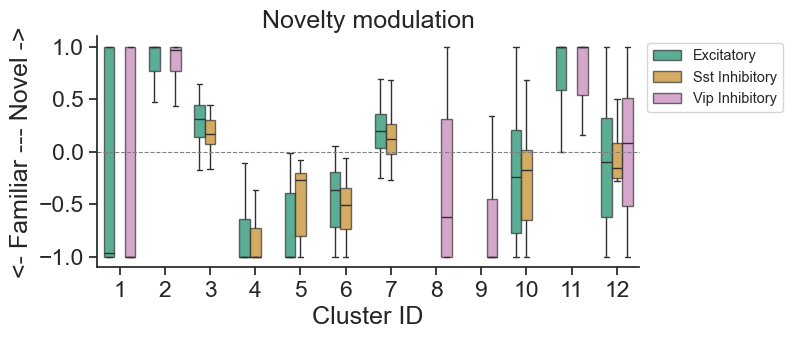

In [43]:
location = 'layer'
order = ['upper', 'lower']
n_cells_table = processing.get_cluster_proportion_stats_for_locations(cluster_meta, location=location)
small_clusters = n_cells_table[n_cells_table.fraction_cells_cluster<0.035].reset_index().set_index(['cre_line', 'cluster_id']).index.values
small_clusters = np.unique(small_clusters)


coding_score_metrics_filtered = coding_score_metrics.copy()
for small_cluster in small_clusters: 
    csids = coding_score_metrics[(coding_score_metrics.cre_line==small_cluster[0]) & (coding_score_metrics.cluster_id==small_cluster[1])].index.values
    coding_score_metrics_filtered = coding_score_metrics_filtered.drop(index=csids)

print(len(coding_score_metrics), 'total cells')
print(len(coding_score_metrics_filtered), 'after removing clusters with < 4% of cells in a given cre line')


# metric comparing N to avg of F and n+
plotting.plot_experience_modulation(coding_score_metrics_filtered, metric='experience_modulation', save_dir=None, 
                                    folder='metric_distributions', suffix='_filtered_clusters')

### Main cluster properties


#### Plot kernels for the top 5 clusters from each cell type

(<Figure size 700x390 with 15 Axes>,
 array([[<Axes: title={'center': 'all-images'}, ylabel='Exc'>,
         <Axes: title={'center': 'all-images'}>,
         <Axes: title={'center': 'all-images'}>,
         <Axes: title={'center': 'hits'}>,
         <Axes: title={'center': 'pupil'}>],
        [<Axes: title={'center': 'all-images'}, ylabel='Sst'>,
         <Axes: title={'center': 'all-images'}>,
         <Axes: title={'center': 'all-images'}>,
         <Axes: title={'center': 'hits'}>,
         <Axes: title={'center': 'pupil'}>],
        [<Axes: title={'center': 'all-images'}, ylabel='Vip'>,
         <Axes: title={'center': 'omissions'}>,
         <Axes: title={'center': 'omissions'}>,
         <Axes: title={'center': 'hits'}>,
         <Axes: title={'center': 'pupil'}>]], dtype=object))

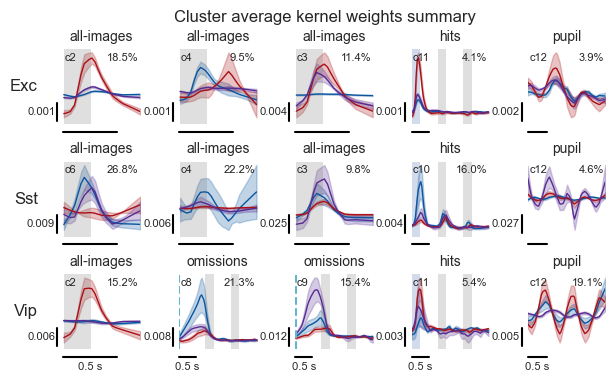

In [44]:
plotting.plot_cluster_kernel_overlays_summary(
    weights_df,
    run_params,
    cluster_kernel_pairs=None,
    linewidth=1,
    share_y_across=False,
    x_sb_seconds=0.5,
)

#### Plot average responses for main clusters

In [45]:
# plot_cluster_response_overlays_summary(
#     image_mdf,
#     change_mdf,
#     omission_mdf,
#     cluster_kernel_pairs=None,
#     linewidth=0.8,
#     share_y_across=False,
#     x_sb_seconds=0.5,
#     remove_outliers=True,
# )

#### Define helper functions

#### Cell types as rows 

(<Figure size 560x420 with 12 Axes>,
 array([[<Axes: title={'center': 'Cluster 2'}>,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 10'}>],
        [<Axes: title={'center': 'Cluster 6'}>,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 10'}>],
        [<Axes: title={'center': 'Cluster 2'}>,
         <Axes: title={'center': 'Cluster 9'}>,
         <Axes: title={'center': 'Cluster 8'}>,
         <Axes: title={'center': 'Cluster 11'}>]], dtype=object))

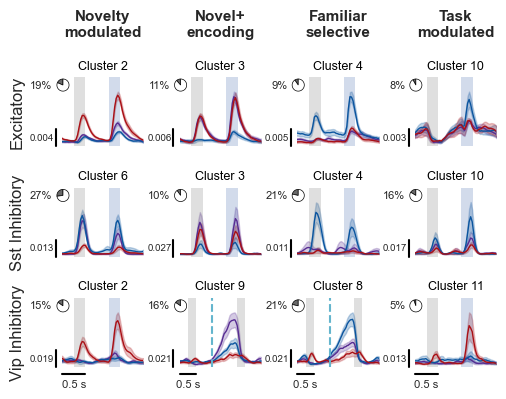

In [46]:
plotting.plot_mean_cluster_response_profiles(
    image_mdf,
    change_mdf,
    omission_mdf,
    linewidth=1,
    x_sb_seconds=0.5,
    apply_peak_threshold=True,
)


#### Cell types as columns

##### Cre as cols, clusters as rows

In [47]:
# Check default kernels and response types to use 
plotting._default_cluster_kernel_pairs()

{'Excitatory': ([2, 3, 4, 10],
  ['all-images', 'all-images', 'all-images', 'hits']),
 'Sst Inhibitory': ([6, 3, 4, 10],
  ['all-images', 'all-images', 'all-images', 'hits']),
 'Vip Inhibitory': ([2, 9, 8, 11],
  ['all-images', 'omissions', 'omissions', 'hits'])}

In [48]:
# Check cluster type labels
plotting._default_group_titles()

['Novelty\nmodulated',
 'Novel+\nencoding',
 'Familiar\nselective',
 'Task\nmodulated',
 'Behavior\nmodulated']

(<Figure size 450x480 with 12 Axes>,
 array([[<Axes: title={'center': 'Cluster 2'}>,
         <Axes: title={'center': 'Cluster 6'}>,
         <Axes: title={'center': 'Cluster 2'}>],
        [<Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 9'}>],
        [<Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 8'}>],
        [<Axes: title={'center': 'Cluster 10'}>,
         <Axes: title={'center': 'Cluster 10'}>,
         <Axes: title={'center': 'Cluster 11'}>]], dtype=object))

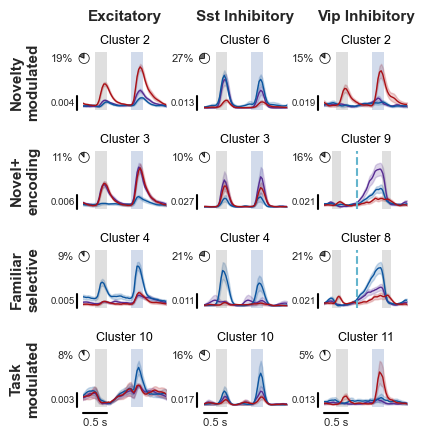

In [49]:
plotting.plot_mean_cluster_response_profiles_transposed(
    image_mdf, change_mdf, omission_mdf,
    linewidth=1,
    apply_peak_threshold=True,
)


#### Metric & depth panels

(<Figure size 270x480 with 12 Axes>,
 array([[<Axes: title={'center': 'Cluster 2'}, ylabel='Image selectivity'>,
         <Axes: title={'center': 'Cluster 6'}>,
         <Axes: title={'center': 'Cluster 2'}>],
        [<Axes: title={'center': 'Cluster 3'}, ylabel='Image selectivity'>,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 9'}>],
        [<Axes: title={'center': 'Cluster 4'}, ylabel='Image selectivity'>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 8'}>],
        [<Axes: title={'center': 'Cluster 10'}, ylabel='Image selectivity'>,
         <Axes: title={'center': 'Cluster 10'}>,
         <Axes: title={'center': 'Cluster 11'}>]], dtype=object))

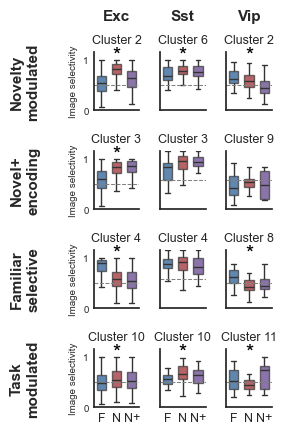

In [50]:
plotting.plot_cluster_metric_panels(response_metrics,
                           metric='lifetime_sparseness_images',
                           ylabel='Image selectivity')


(<Figure size 240x480 with 12 Axes>,
 array([[<Axes: title={'center': 'Cluster 2'}, ylabel='Fraction cells'>,
         <Axes: title={'center': 'Cluster 6'}>,
         <Axes: title={'center': 'Cluster 2'}>],
        [<Axes: title={'center': 'Cluster 3'}, ylabel='Fraction cells'>,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Cluster 9'}>],
        [<Axes: title={'center': 'Cluster 4'}, ylabel='Fraction cells'>,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Cluster 8'}>],
        [<Axes: title={'center': 'Cluster 10'}, ylabel='Fraction cells'>,
         <Axes: title={'center': 'Cluster 10'}>,
         <Axes: title={'center': 'Cluster 11'}>]], dtype=object))

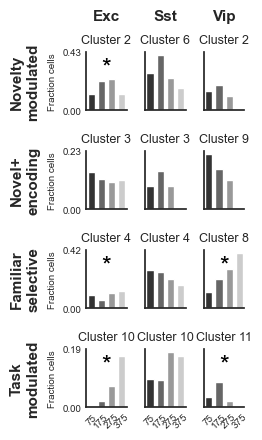

In [51]:

plotting.plot_cluster_depth_panels(cluster_meta)

In [52]:
location = 'binned_depth'
metric = 'fraction_cells_location'
ylabel = 'Fraction cells in each depth'

cluster_meta_tmp = cluster_meta[cluster_meta.cluster_id!=1]
n_cells_table = processing.get_cluster_proportion_stats_for_locations(cluster_meta_tmp, location=location)
n_cells_table = n_cells_table.reset_index()

In [53]:
cluster_kernel_pairs = {
            "Excitatory":     ([2, 4, 3, 11, 12], ["all-images", "all-images", "all-images", "hits", "pupil"]),
            "Sst Inhibitory": ([6, 4, 3, 10, 12], ["all-images", "all-images", "all-images", "hits", "pupil"]),
            "Vip Inhibitory": ([2, 8, 9, 11, 12], ["all-images", "omissions",  "omissions",  "hits", "pupil"]),
        }

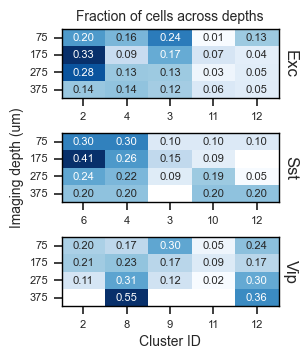

In [54]:
base_fontsize = 8

fig_w = 2.8
fig_h = 3 * 1.2
fig, ax = plt.subplots(3, 1, figsize=(fig_w, fig_h))
for i, cre_line in enumerate(cre_lines): 
    cell_type = utils.convert_cre_line_to_cell_type(cre_line)
    data = n_cells_table[n_cells_table.cre_line==cre_line]
    pivot = data.pivot_table(index='cluster_id', columns='binned_depth', values='fraction_cells_location')
    cluster_ids = cluster_kernel_pairs[cell_type][0]
    pivot = pivot.loc[cluster_ids].T
    ax[i] = sns.heatmap(pivot, cmap='Blues', ax=ax[i], cbar=False, # vmax=0.4,
                        annot=True, fmt=".2f", annot_kws={"fontsize": base_fontsize},
                        cbar_kws={'label':'Fraction of cells', 'shrink': 0.5})
    ax[i].set_yticks(np.arange(len(pivot.index.values))+0.5)
    ax[i].set_yticklabels(pivot.index.values, rotation=0, fontsize=base_fontsize)
    ax[i].set_xticks(np.arange(len(cluster_ids))+0.5)
    ax[i].set_xticklabels(pivot.columns.values, fontsize=base_fontsize)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title('')
    ax[i].text(1.02, 0.5, cell_type[:3], transform=ax[i].transAxes,
           rotation=270, ha='left', va='center', fontsize=base_fontsize+4)
ax[2].set_xlabel('Cluster ID', fontsize=base_fontsize+2)
ax[1].set_ylabel('Imaging depth (um)', fontsize=base_fontsize+2)
ax[0].set_title('Fraction of cells across depths', fontsize=base_fontsize+2)
for i in range(3):
    for _, spine in ax[i].spines.items():
        spine.set_visible(True)
        spine.set_color('black')  # Set the color of the box
        spine.set_linewidth(1) 
fig.subplots_adjust(hspace=0.5)

#### Avereage responses and metrics together

(<Figure size 1045x420 with 45 Axes>,
 array([[<Axes: title={'center': 'Cluster 2'}>,
         <Axes: title={'center': 'Image\nselectivity'}>,
         <Axes: title={'center': 'Fraction\ncells'}>, <Axes: >,
         <Axes: title={'center': 'Cluster 3'}>,
         <Axes: title={'center': 'Image\nselectivity'}>,
         <Axes: title={'center': 'Fraction\ncells'}>, <Axes: >,
         <Axes: title={'center': 'Cluster 4'}>,
         <Axes: title={'center': 'Image\nselectivity'}>,
         <Axes: title={'center': 'Fraction\ncells'}>, <Axes: >,
         <Axes: title={'center': 'Cluster 10'}>,
         <Axes: title={'center': 'Image\nselectivity'}>,
         <Axes: title={'center': 'Fraction\ncells'}>],
        [<Axes: title={'center': 'Cluster 6'}>, <Axes: >, <Axes: >,
         <Axes: >, <Axes: title={'center': 'Cluster 3'}>, <Axes: >,
         <Axes: >, <Axes: >, <Axes: title={'center': 'Cluster 4'}>,
         <Axes: >, <Axes: >, <Axes: >,
         <Axes: title={'center': 'Cluster 10'}>, <A

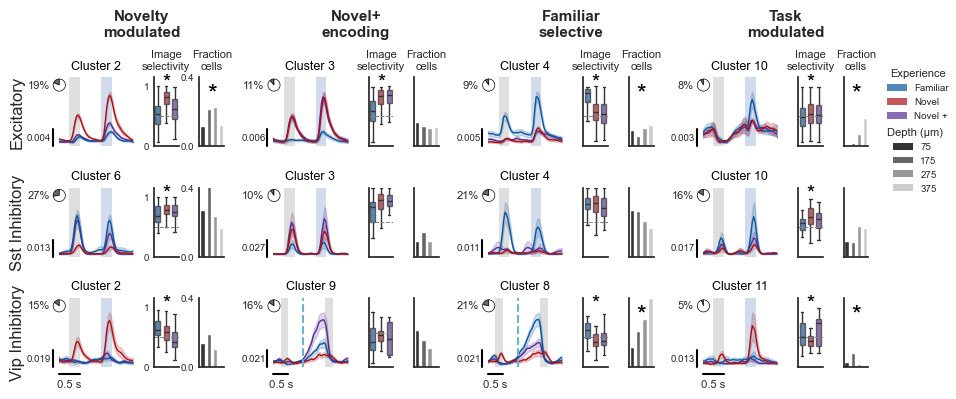

In [55]:
plotting.plot_main_cluster_properties(
    image_mdf,
    change_mdf,
    omission_mdf,
    response_metrics,
    cluster_meta,
    metric='lifetime_sparseness_images',
    ylabel='Image selectivity',
    linewidth=1,
    share_y_across=True,
    x_sb_seconds=0.5,
    apply_peak_threshold=True,
)


## Clustering validation

### Prediction strength

##### validate pre-determined clusters

1) split data into test and training set
2) train a classifier to predict the original cluster labels using the training set, then predict the cluster IDs in the test set using this classifier
3) find cells in test set belonging to each original cluster and ask what proportion of those cell pairs have the same predicted label in the test prediction (prediction based on training classifier trained to learn the original cluster IDs)
4) compute minimum proportion of matching pairs across the original set of clusters. 

In [56]:
X = feature_matrix.loc[cluster_meta.index.values]
original_cluster_labels = cluster_meta.cluster_id.values

prediction_scores_for_clusters = processing.get_prediction_score_for_clusters(X, original_cluster_labels)
prediction_scores_for_clusters.head()

,iteration,cluster_id,cluster_strength
0,0,1,1.000000
1,0,2,0.953140
2,0,3,0.848308
3,0,4,0.918116
4,0,5,0.915330


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_22840/2138675355.py:3: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  ax = sns.pointplot(data=prediction_scores_for_clusters, x='cluster_id', y='cluster_strength', join=False, zorder=1000, ax=ax)


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


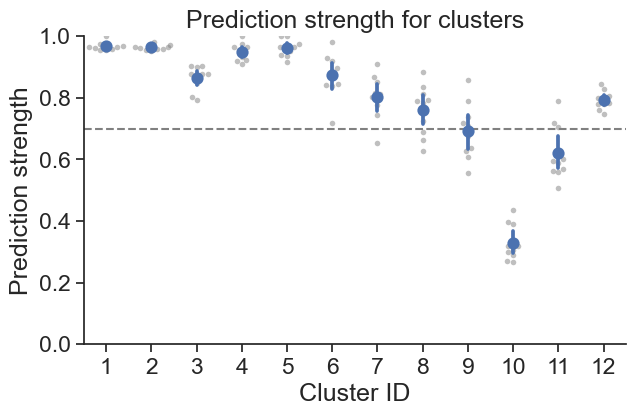

In [57]:
fig, ax = plt.subplots(figsize=(7,4))
ax = sns.swarmplot(data=prediction_scores_for_clusters, x='cluster_id', y='cluster_strength', color='gray', alpha=0.5, size=4, ax=ax)
ax = sns.pointplot(data=prediction_scores_for_clusters, x='cluster_id', y='cluster_strength', join=False, zorder=1000, ax=ax)

ax.set_title('Prediction strength for clusters')
ax.set_ylabel('Prediction strength')
ax.set_xlabel('Cluster ID')
ax.set_ylim(0, 1)
ax.axhline(y=0.7, xmin=0, xmax=1, linestyle='--', color='gray')

##### Compare to cluster size

In [58]:
tmp = cluster_meta.copy()
tmp['cre_line'] = 'all'
n_cells_per_cluster = processing.get_fraction_cells_per_cluster_per_group(tmp, col_to_group='cre_line')
n_cells_per_cluster['percent_cells'] = n_cells_per_cluster.fraction_per_cluster * 100
n_cells_per_cluster

,cre_line,cluster_id,n_cells_cluster,n_cells_group,fraction_per_cluster,percent_cells
0,all,1,789,3901,0.202256,20.225583
1,all,2,673,3901,0.172520,17.251987
2,all,3,404,3901,0.103563,10.356319
3,all,4,356,3901,0.091259,9.125865
4,all,5,328,3901,0.084081,8.408100
5,all,6,229,3901,0.058703,5.870290
6,all,7,234,3901,0.059985,5.998462
7,all,8,112,3901,0.028711,2.871059
8,all,9,92,3901,0.023584,2.358370
9,all,10,311,3901,0.079723,7.972315


In [59]:
mean_ps_df = prediction_scores_for_clusters.groupby(['cluster_id']).mean()
mean_ps_df = mean_ps_df.merge(n_cells_per_cluster[['cluster_id', 'percent_cells']], on=['cluster_id'])
mean_ps_df.head()

,cluster_id,iteration,cluster_strength,percent_cells
0,1,4.5,0.967819,20.225583
1,2,4.5,0.964259,17.251987
2,3,4.5,0.865954,10.356319
3,4,4.5,0.949537,9.125865
4,5,4.5,0.961338,8.408100


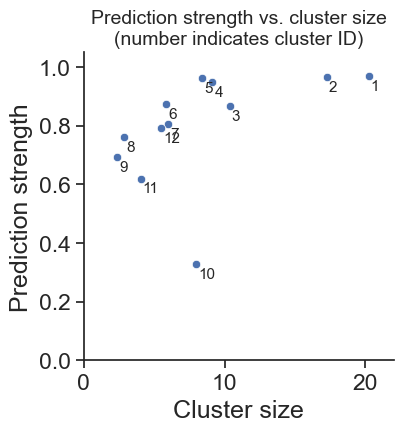

In [60]:
figsize = (4,4)
fig, ax = plt.subplots(figsize=figsize)
ax = sns.scatterplot(data=mean_ps_df, x='percent_cells', y='cluster_strength',  ax=ax)
ax.set_xlim(0, 22)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Prediction strength')
ax.set_xlabel('Cluster size')
ax.set_title('Prediction strength vs. cluster size\n(number indicates cluster ID)', fontsize=14)
for cluster_id in mean_ps_df.cluster_id.unique(): 
    row_data = mean_ps_df[mean_ps_df.cluster_id==cluster_id]
    ax.text(s=str(row_data.cluster_id.values[0]), fontsize=11, ha='left', va='top',
            x=row_data.percent_cells.values[0]+0.15, y=row_data.cluster_strength.values[0]-0.01)

##### Robustness of clusters for individual cre lines

In [61]:
counts = pd.DataFrame(cluster_meta.value_counts(['cell_type', 'cluster_id']), columns=['n_cells']).reset_index().sort_values(by=['cell_type', 'cluster_id'])
clusters_to_remove = counts[counts.n_cells<10]
clusters_to_remove

,cell_type,cluster_id,n_cells
29,Sst Inhibitory,1,6
25,Sst Inhibitory,12,9
26,Vip Inhibitory,3,8
28,Vip Inhibitory,5,7
27,Vip Inhibitory,7,7


In [62]:
cells_to_remove = []
for i, row_data in clusters_to_remove.iterrows():
    csids = cluster_meta[(cluster_meta.cell_type==row_data.cell_type) & (cluster_meta.cluster_id==row_data.cluster_id)].index.values
    cells_to_remove = np.hstack((cells_to_remove, csids))

/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_22840/1581135060.py:15: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  ax = sns.pointplot(data=df, x='cluster_id', y='cluster_strength', hue='cell_type',


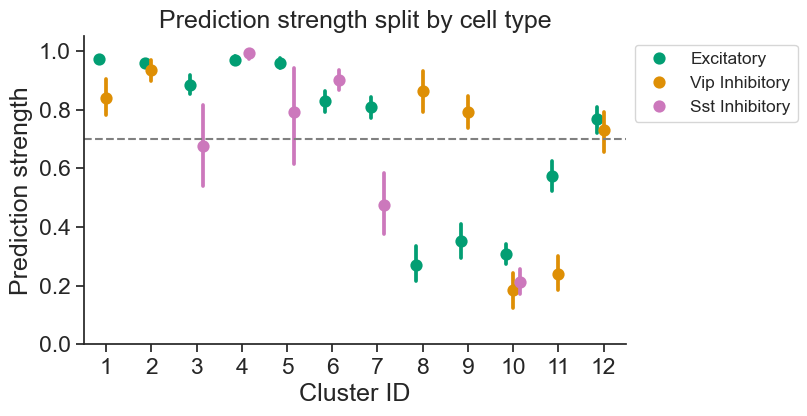

In [63]:
cluster_meta_tmp = cluster_meta.copy()
cluster_meta_tmp = cluster_meta_tmp.drop(index=cells_to_remove)

df = pd.DataFrame()
for cell_type in cell_types: 
    cre_cluster_meta = cluster_meta_tmp[cluster_meta_tmp.cell_type==cell_type]
    X = feature_matrix.loc[cre_cluster_meta.index.values]
    original_cluster_labels = cre_cluster_meta.cluster_id.values

    prediction_scores_for_clusters_cre = processing.get_prediction_score_for_clusters(X, original_cluster_labels)
    prediction_scores_for_clusters_cre['cell_type'] = cell_type
    df = pd.concat([df, prediction_scores_for_clusters_cre])

fig, ax = plt.subplots(figsize=(7,4))
ax = sns.pointplot(data=df, x='cluster_id', y='cluster_strength', hue='cell_type', 
                   palette=utils.get_cell_type_colors(), join=False, dodge=0.3, ax=ax)
ax.legend(bbox_to_anchor=(1,1), fontsize='x-small', title='')
ax.set_title('Prediction strength split by cell type')
ax.set_ylabel('Prediction strength')
ax.set_xlabel('Cluster ID')
ax.set_ylim(0, 1.05)
ax.axhline(y=0.7, xmin=0, xmax=1, linestyle='--', color='gray')

In [64]:
tmp = cluster_meta.copy()
n_cells_per_cluster = processing.get_fraction_cells_per_cluster_per_group(tmp, col_to_group='cell_type')
n_cells_per_cluster['percent_cells'] = n_cells_per_cluster.fraction_per_cluster * 100
n_cells_per_cluster.head()


,cell_type,cluster_id,n_cells_cluster,n_cells_group,fraction_per_cluster,percent_cells
0,Excitatory,1,722,3298,0.218921,21.892056
1,Excitatory,2,611,3298,0.185264,18.526380
2,Excitatory,3,377,3298,0.114312,11.431170
3,Excitatory,4,313,3298,0.094906,9.490600
4,Excitatory,5,310,3298,0.093996,9.399636


In [65]:
mean_ct_ps_df = df.groupby(['cell_type', 'cluster_id']).mean()
mean_ct_ps_df = mean_ct_ps_df.merge(n_cells_per_cluster[['cluster_id', 'percent_cells', 'cell_type']], on=['cell_type', 'cluster_id'])
mean_ct_ps_df.head()

,cell_type,cluster_id,iteration,cluster_strength,percent_cells
0,Excitatory,1,4.5,0.972700,21.892056
1,Excitatory,2,4.5,0.957771,18.526380
2,Excitatory,3,4.5,0.884956,11.431170
3,Excitatory,4,4.5,0.968109,9.490600
4,Excitatory,5,4.5,0.959822,9.399636


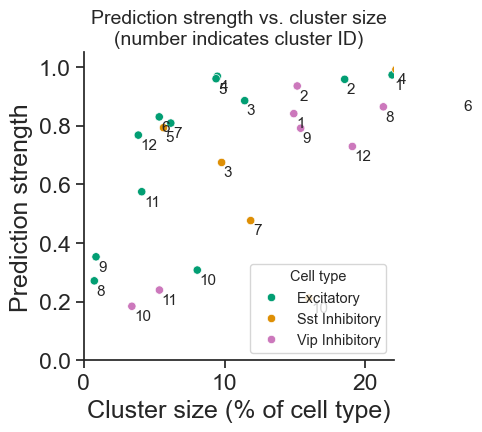

In [66]:
figsize = (4,4)
fig, ax = plt.subplots(figsize=figsize)
ax = sns.scatterplot(data=mean_ct_ps_df, x='percent_cells', y='cluster_strength', 
                     hue='cell_type', palette=utils.get_cell_type_colors(), ax=ax)
ax.set_xlim(0, 22)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Prediction strength')
ax.set_xlabel('Cluster size (% of cell type)')
ax.set_title('Prediction strength vs. cluster size\n(number indicates cluster ID)', fontsize=14)
for row in range(len(mean_ct_ps_df)): 
    cluster_id = mean_ct_ps_df.cluster_id.values[row]
    cell_type = mean_ct_ps_df.cell_type.values[row]
    row_data = mean_ct_ps_df[(mean_ct_ps_df.cluster_id==cluster_id) & (mean_ct_ps_df.cell_type==cell_type)]
    ax.text(s=str(row_data.cluster_id.values[0]), fontsize=11, ha='left', va='top',
            x=row_data.percent_cells.values[0]+0.15, y=row_data.cluster_strength.values[0]-0.01)
ax.legend(title='Cell type', fontsize='xx-small', title_fontsize='xx-small')

##### Show least predictable cluster on UMAP

In [67]:
clustering_results_dir = loading.get_clustering_results_dir()

umap_df = processing.get_umap_results(feature_matrix, cluster_meta, save_dir=clustering_results_dir, suffix='')

loading umap results from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_clustering_results/umap_results_df.h5


In [68]:
# limit cluster meta to cells that are not in cluster 1 (which is an outlier in the plot)
main_cluster_meta = cluster_meta[cluster_meta.cluster_id!=1]
# limit umap_df to non-cluster 1
umap_df['cell_specimen_id'] = cluster_meta.index.values
umap_df = umap_df.set_index('cell_specimen_id')
umap_df = umap_df.loc[main_cluster_meta.index.values]
umap_df['cell_type'] = main_cluster_meta['cell_type']
# identify other non-outlier points and limit both tables to those
csids = umap_df[umap_df.x<16].index.values
main_cluster_meta = main_cluster_meta.loc[csids]
umap_df = umap_df.loc[csids]
print(len(umap_df), len(main_cluster_meta))
umap_df.head()

2941 2941


,x,y,cluster_id,cell_type
cell_specimen_id,,,,
1086489847,4.780380,7.625232,12,Vip Inhibitory
1086489860,9.371953,2.737884,2,Vip Inhibitory
1086489891,4.785028,7.619345,12,Vip Inhibitory
1086489976,6.144250,11.332527,4,Sst Inhibitory
1086490002,9.028252,10.901272,4,Sst Inhibitory


Text(0.5, 1.0, 'Cluster 10')

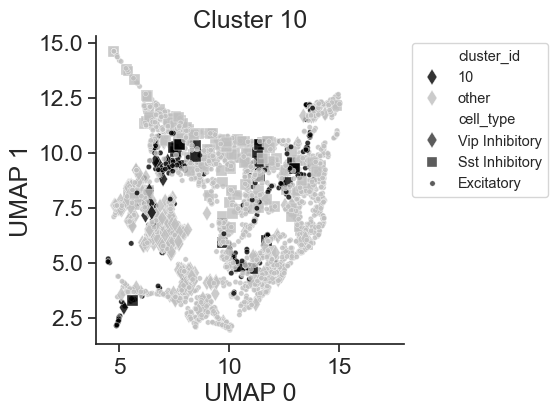

In [69]:
cluster_ids = np.sort(umap_df.cluster_id.unique())
gray_cluster_ids = [cluster_id for cluster_id in cluster_ids if cluster_id!=10]

umap_df['cluster_id'] = ['other' if cluster_id in gray_cluster_ids else cluster_id for cluster_id in umap_df.cluster_id.values]

hue_order = [10,  'other']
palette = ['#000000', '#BFBFBF']

figsize = (5, 4)
fig, ax = plt.subplots(figsize=figsize)

markers_dict = {'Excitatory': '.', # '^'
                'Sst Inhibitory': 's', # 'o', 's'
                'Vip Inhibitory': 'd'}

ax = sns.scatterplot(data=umap_df, x='x', y='y', s=60, ax=ax, 
                     hue='cluster_id', hue_order=hue_order, style='cell_type', 
                     palette=palette, markers=markers_dict, linewidth=0.3, alpha=0.8, edgecolor='w')
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.axis('square')
ax.legend(fontsize='xx-small', title_fontsize='xx-small',  bbox_to_anchor=(1,1))
ax.set_title('Cluster 10')

#### Validate selection of k

In [70]:
X = feature_matrix.copy()
# X = feature_matrix.loc[cluster_meta.index.values].copy()

# get the prediction score for each cluster across repeated clusterings with different values of k
ps_scores_df = processing.get_prediction_strengths_for_values_of_k(X, n_iterations=10, max_n_clusters=20, model='SpectralClustering', affinity='rbf', save_dir=data_dir)
ps_scores_df.head()

# get average of mean ps across iterations
mean_scores_df = processing.get_mean_and_sem_across_iterations(ps_scores_df, col='mean')

range_of_k = np.sort(mean_scores_df.n_clusters.unique())
pred_strengths = mean_scores_df.sort_values(by=['n_clusters'])['mean_ps'].values
yerr = mean_scores_df.sort_values(by=['n_clusters'])['sem_ps'].values


Loading existing results from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_clustering_results/prediction_strengths_across_k.h5


In [71]:
ps_scores_df.head()

,cluster_number,prediction_strength,cluster_id,n_clusters,iteration
0,0,0.930734,0,2,0
1,1,0.905867,1,2,0
0,0,0.943970,1,2,1
1,1,0.935736,0,2,1
0,0,0.899728,0,2,2


14


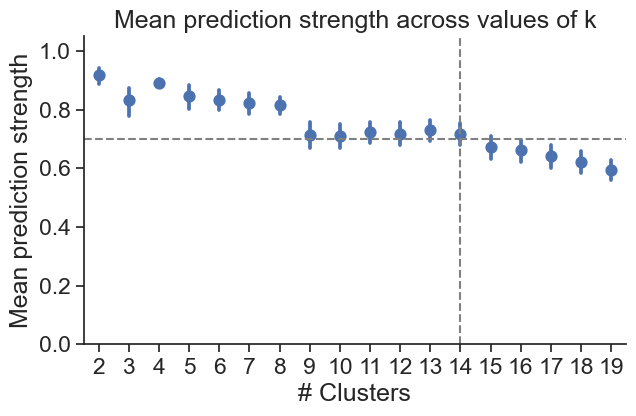

In [72]:

# Plot the results
fig, ax = plt.subplots(figsize=(7,4))
ax = sns.pointplot(data=ps_scores_df, y='prediction_strength', x='n_clusters', ax=ax, linestyle='none')
# ax = sns.swarmplot(data=ps_scores_df, y='prediction_strength', x='n_clusters', color='gray', alpha=0.5, size=4, ax=ax)
ax.set_ylim(0,1.05)
ax.set_xlabel('# Clusters')
ax.set_ylabel('Mean prediction strength')
ax.set_title('Mean prediction strength across values of k')
ax.axhline(y=0.7, xmin=0, xmax=1, linestyle='--', color='gray')
# get the largest cluster that meets the threshold criterion
selected_k = mean_scores_df[mean_scores_df['mean_ps']>=0.7].sort_values(by=['n_clusters'])['n_clusters'].values[-1]
print(selected_k)
# selected_k = range_of_k[np.where(np.asarray(pred_strengths)+np.asarray(sems)>0.8)[0][-1]]
ax.axvline(x=selected_k-np.min(mean_scores_df['n_clusters']), ymin=0, ymax=1, linestyle='--', color='gray');


### Shuffle Control Analysis


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1823: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  feature_matrix_cre.append(feature_matrix.loc[cids], ignore_index=True)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1823: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  feature_matrix_cre.append(feature_matrix.loc[cids], ignore_index=True)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1823: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  feature_matrix_cre.append(feature_matrix.loc[cids], ignore_index=True)
/Users/

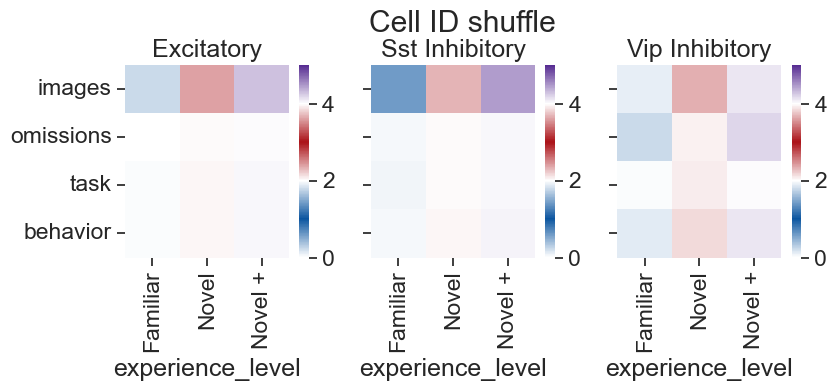

In [73]:
shuffle_control_dir = os.path.join(data_dir, 'shuffle_control')

# Load shuffled feature matrices
filepath = os.path.join(shuffle_control_dir, 'shuffled_feature_matrices.pkl')
if os.path.exists(filepath):
    with open(filepath, 'rb') as f:
        shuffled_feature_matrices = pickle.load(f)

    # Plot mean shuffled feature matrix
    plotting.plot_mean_shuffled_feature_matrix(
        shuffled_feature_matrices, original_cluster_meta,
        session_colors=True, experience_index=None,
        save_dir=save_dir, folder='shuffle_control')

# Load shuffled cluster labels and compute mean dropout scores
n_boots = np.arange(500)
filepath = os.path.join(shuffle_control_dir, 'shuffled_labels.pkl')
with open(filepath, 'rb') as f:
    shuffled_labels = pickle.load(f)

# Compute mean dropout scores for original data
original_mean_dropout_scores = processing.get_mean_dropout_scores_per_cluster(
    original_feature_matrix, cluster_meta=original_cluster_meta.reset_index(),
    sort_by_cluster_size=False)

original_mean_dropout_scores_unstacked = processing.get_mean_dropout_scores_per_cluster(
    original_feature_matrix, stacked=False,
    cluster_meta=original_cluster_meta.reset_index(),
    sort_by_cluster_size=False)

# Load mean dropout scores for shuffled data
filepath_shuffled_scores = os.path.join(shuffle_control_dir, 'mean_dropout_scores_shuffled.pkl')
with open(filepath_shuffled_scores, 'rb') as f:
    mean_dropout_scores_shuffled = pickle.load(f)

# Load SSE matrix and mapping
SSE_matrix_filename = os.path.join(shuffle_control_dir, 'SSE_matrix_shuffled_nboot.pkl')
with open(SSE_matrix_filename, 'rb') as f:
    SSE_matrix_dict = pickle.load(f)

threshold = 0.15
SSE_mapping = processing.get_cluster_mapping(SSE_matrix_dict, threshold=threshold)

# Sort SSE values
SSE_matrix_sorted = processing.sort_SSE_values(SSE_matrix_dict, SSE_mapping)

# Get cluster means
original_cluster_means = plotting.get_cluster_means(original_feature_matrix, original_cluster_meta)

# Get shuffled cluster means
nb_mean_dropout_scores_shuffled_unstacked = {}
for n, n_boot in enumerate(n_boots):
    if n in shuffled_labels:
        cluster_meta_boot = shuffled_labels[n]
        feature_matrix_boot = shuffled_feature_matrices[n]
        mean_dropout_scores_unstacked = processing.get_mean_dropout_scores_per_cluster(
            feature_matrix_boot, cluster_meta=cluster_meta_boot,
            stacked=False, max_n_clusters=12)
        nb_mean_dropout_scores_shuffled_unstacked[n] = mean_dropout_scores_unstacked

shuffled_clusters_dict = processing.get_matched_clusters_means_dict(
    SSE_mapping, nb_mean_dropout_scores_shuffled_unstacked,
    metric='mean', shuffle_type=None, cre_line=None)

shuffled_cluster_means = processing.get_shuffled_cluster_means(shuffled_clusters_dict, 12)


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/processing.py:3922: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  shuffle_probability_df = shuffle_probability_df.append(cluster_meta, ignore_index=True)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/processing.py:3922: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  shuffle_probability_df = shuffle_probability_df.append(cluster_meta, ignore_index=True)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/processing.py:3922: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  shuffle_probability_df = shuffle_proba

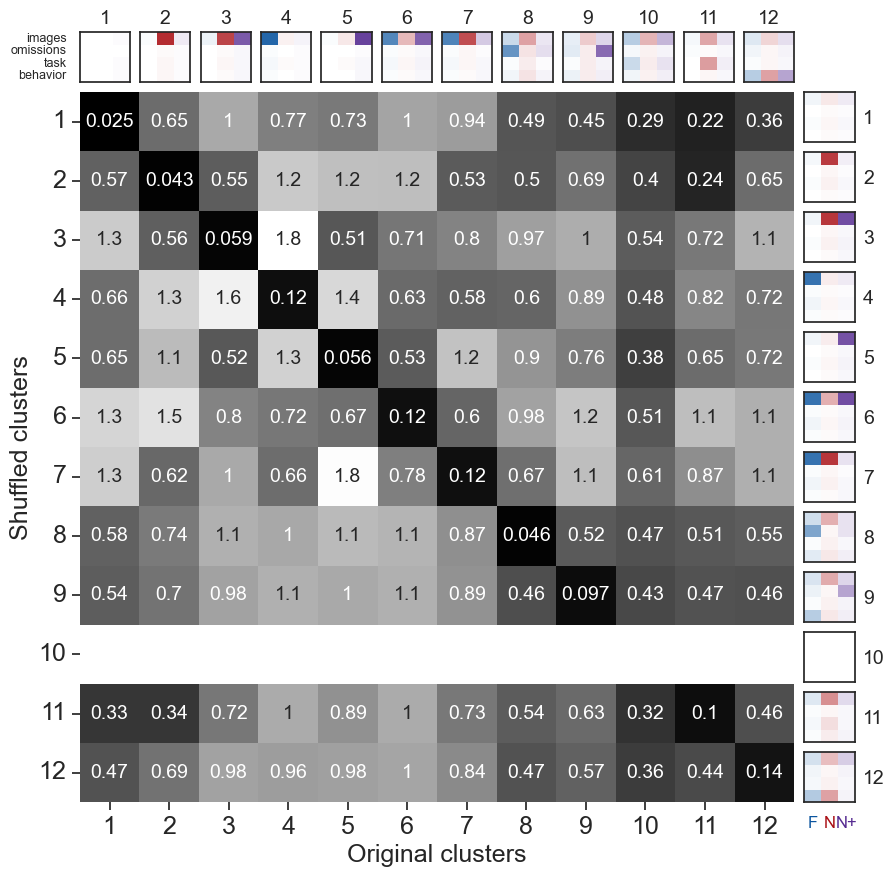

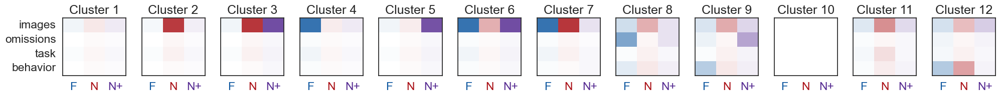

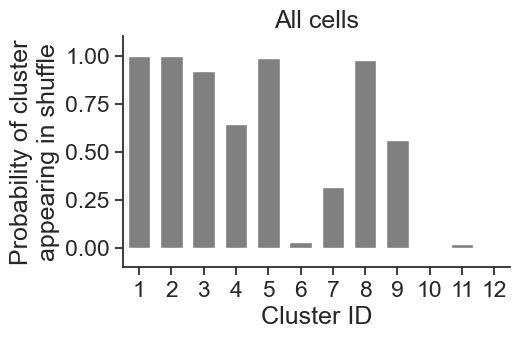

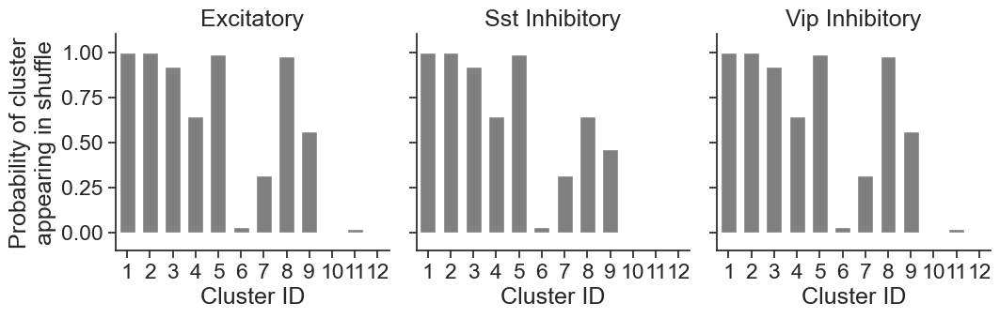

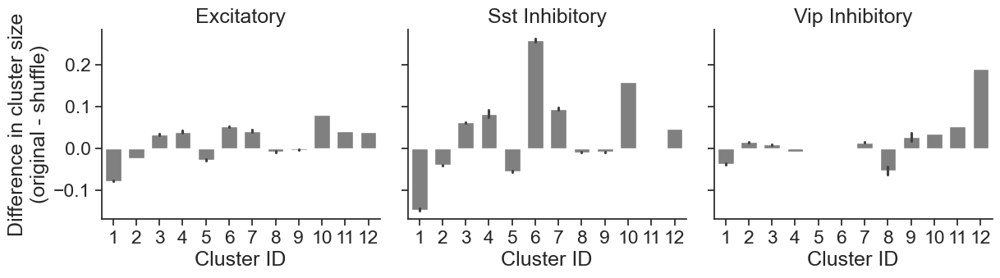

In [74]:

# Plot cluster heatmaps with SSE matrix
plotting.plot_cluster_heatmaps_with_SSE_matrix(
    original_cluster_means, shuffled_cluster_means, SSE_matrix_sorted,
    session_colors=True, experience_index=None,
    save_dir=save_dir, folder='shuffle_control')

# Plot matched clusters heatmap
plotting.plot_matched_clusters_heatmap_remapped(
    shuffled_clusters_dict, abbreviate_features=False,
    abbreviate_experience=True, small_fontsize=False,
    session_colors=True, save_dir=save_dir, folder='shuffle_control')

# Split shuffled dataframes by cre line
shuffled_labels_cre = {}
for cre_line in cre_lines:
    nb_labels_shuffled = {}
    for n_boot in n_boots:
        nb_labels_shuffled[n_boot] = shuffled_labels[n_boot][
            shuffled_labels[n_boot].cre_line == cre_line
        ]
    shuffled_labels_cre[cre_line] = nb_labels_shuffled

# Compute cluster probabilities and plot
cluster_probabilities = processing.compute_probabilities(SSE_mapping, shuffled_labels)
probability_df = processing.get_cluster_probability_df(
    cluster_probabilities,
    cre_lines=None,
    columns=['cluster_id', 'probability'])
plotting.plot_cluster_probability_for_shuffle(
    probability_df,
    save_dir=save_dir,
    folder='shuffle_control')

# Compute cluster probabilities per cre line and plot
cluster_probabilities_cre = {}
for cre_line in cre_lines:
    cluster_probabilities_cre[cre_line] = processing.compute_probabilities(
        SSE_mapping,
        shuffled_labels_cre[cre_line])

probability_df_cre = processing.get_cluster_probability_df(
    cluster_probabilities_cre,
    cre_lines=cre_lines,
    columns=['cre_line', 'cluster_id', 'probability'])
plotting.plot_cluster_probability_for_shuffle(
    probability_df_cre,
    save_dir=save_dir,
    folder='shuffle_control',
    cre_lines=cre_lines)

# Compute and plot cluster size differences
normalize = True
shuffled_cluster_sizes_cre = {}
for cre_line in cre_lines:
    shuffled_cluster_sizes_cre[cre_line] = processing.get_cluster_size_variance(
        SSE_mapping,
        shuffled_labels_cre[cre_line],
        normalize=normalize)

original_cluster_sizes_cre = {}
for cre_line in cre_lines:
    cluster_meta_cre = original_cluster_meta[original_cluster_meta.cre_line == cre_line]
    original_cluster_sizes_cre[cre_line] = cluster_meta_cre.value_counts(
        'cluster_id',
        normalize=normalize
    ).reindex(range(1, n_clusters + 1))
    original_cluster_sizes_cre[cre_line] = original_cluster_sizes_cre[cre_line].replace(
        np.nan, 0)

cluster_size_diff_cre = processing.get_cluster_size_differece_df(
    original_cluster_sizes_cre,
    shuffled_cluster_sizes_cre,
    cre_line=cre_lines)

plotting.plot_cluster_size_difference_for_shuffle(
    cluster_size_diff_cre,
    y='abs_cluster_size_diff',
    save_dir=save_dir,
    folder='shuffle_control')


### Familiar-Only Clustering Control


In [75]:
# Load cells matched across 3 familiar sessions
cells_table_familiar = processing.get_cells_matched_in_3_familiar_active_sessions()
cells_table_familiar["identifier"] = [
    str(cells_table_familiar.iloc[row].ophys_experiment_id) + "_" +
    str(cells_table_familiar.iloc[row].cell_specimen_id)
    for row in range(len(cells_table_familiar))
]
cells_table_familiar = utilities.add_binned_depth_column(cells_table_familiar)
cells_table_familiar = cells_table_familiar.set_index("identifier")

# Load GLM results from local cache
glm_results_dir = loading.get_glm_results_dir()
run_params_path = os.path.join(glm_results_dir, glm_version + "_run_params.pkl")
with open(run_params_path, "rb") as f:
    run_params_fam = pickle.load(f)

results_pivoted_fam = pd.read_hdf(
    os.path.join(glm_results_dir, "across_session_normalized_platform_results_pivoted.h5"), key="df")

# Limit to familiar sessions only
results_pivoted_fam = results_pivoted_fam.drop(columns="experience_level")
results_pivoted_fam = results_pivoted_fam.merge(
    cells_table_familiar[["experience_level"]], on="identifier")

# Limit to features for clustering
features_list = ["all-images", "omissions", "task", "behavioral", "ophys_experiment_id"]
results_pivoted_fam = processing.limit_results_pivoted_to_features_for_clustering(
    results_pivoted_fam, features_list)

# Make coding scores positive
results_pivoted_fam = processing.flip_sign_of_dropouts(
    results_pivoted_fam, processing.get_features_for_clustering(),
    use_signed_weights=False)
results_pivoted_fam = results_pivoted_fam.drop(columns=["ophys_experiment_id"])

# Get feature matrix for familiar sessions
save_dir_familiar = os.path.join(data_dir, "familiar_only_clustering_without_problem_session")
# os.makedirs(save_dir_familiar, exist_ok=True)

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1244 experiments
452 familiar active experiments
['Familiar']
['OPHYS_1_images_A' 'OPHYS_3_images_A' 'OPHYS_1_images_B'
 'OPHYS_3_images_B']
445 experiments in filtered cells table
17957 familiar active cell_specimen_ids
17957 familiar active cell_specimen_ids
5 familiar active session numbers
checking session counts: [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3]
1432 cell_specimen_ids in at least 3 sessions
['Familiar']
['OPHYS_3_images_A' 'OPHYS_1_images_A' 'OPHYS_1_images_B'
 'OPHYS_3_images_B']
1432 familiar active cell_specimen_ids in the first 3 sessions
3 familiar active session numbers
1432 familiar active cell_specimen_ids
1432 familiar active cell_specimen_ids
3 familiar active session numbers
experience_levels:  ['Familiar 1' 'Familiar 2' 'Familiar 3']


In [76]:

feature_matrix_familiar = pd.read_hdf(os.path.join(save_dir_familiar, glm_version+"_feature_matrix.h5"), key="df")
# feature_matrix_familiar = processing.get_feature_matrix_for_clustering(
#     results_pivoted_fam, glm_version, save_dir=save_dir_familiar)
feature_matrix_familiar = feature_matrix_familiar.rename(columns={
    "all-images": "images", "behavioral": "behavior"
})

# Load familiar clustering results
n_clusters_familiar = 10
cluster_meta_familiar_path = os.path.join(
    save_dir_familiar, f"cluster_meta_n_{n_clusters_familiar}_clusters.h5")
cluster_meta_familiar = pd.read_hdf(cluster_meta_familiar_path, key="df")
cluster_meta_familiar = cluster_meta_familiar.merge(
    cells_table_familiar[["ophys_experiment_id", "binned_depth"]].drop_duplicates("ophys_experiment_id"), on="ophys_experiment_id")
cluster_meta_familiar = cluster_meta_familiar.set_index('cell_specimen_id')


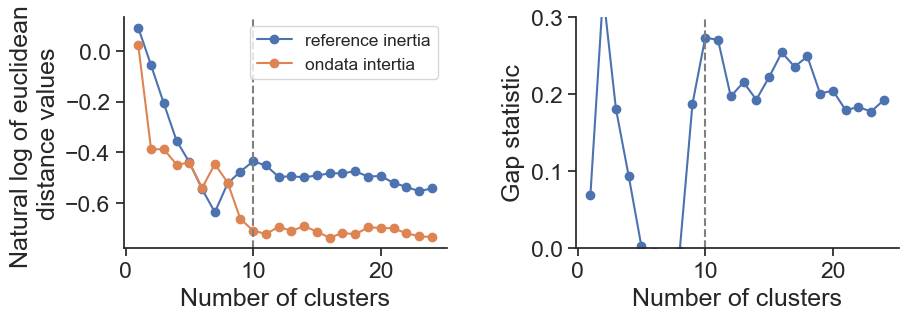

In [77]:
gap_filepath_familiar = os.path.join(save_dir_familiar, "gap_scores_euclidean_24_events_all_L2_optimize_by_session_nb20_unshuffled_to_all.pkl")
gap_statistic_familiar = pd.read_pickle(gap_filepath_familiar)

plotting.plot_gap_statistic(gap_statistic_familiar, cre_lines=['all'], n_clusters_cre=n_clusters_familiar, 
                            save_dir=None, folder='familiar_only_clustering')


In [78]:
# plotting.plot_coding_score_heatmap_matched(cluster_meta_familiar, feature_matrix_familiar, sort_by='cluster_id',
#                                         session_colors=False, experience_index=0, title='',
#                                         save_dir=save_dir, folder='familiar_only_clustering', suffix='', ax=None);

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1581: FutureWarning: merging between different levels is deprecated and will be removed in a future version. (2 levels on the left, 1 on the right)
  cre_line_means = feature_matrix.merge(cluster_meta[['cre_line']], on='cell_specimen_id').groupby('cre_line').mean()
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1570: FutureWarning: merging between different levels is deprecated and will be removed in a future version. (2 levels on the left, 1 on the right)
  cluster_means = feature_matrix.merge(cluster_meta[['cluster_id']], on='cell_specimen_id').groupby('cluster_id').mean()


10 10
3 10
3 10


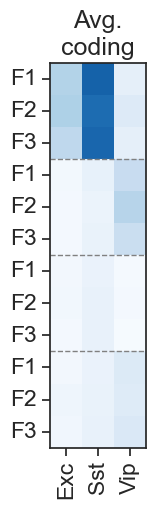

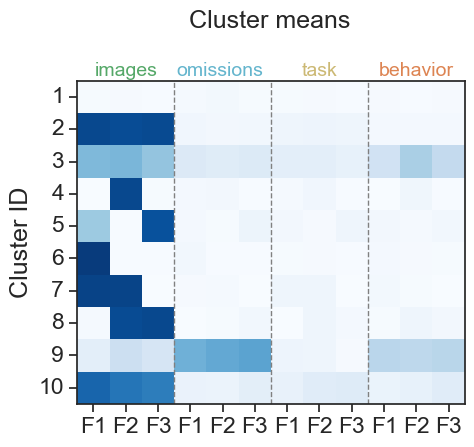

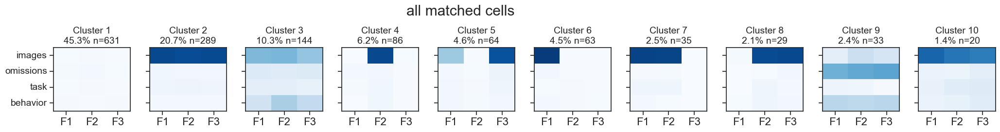

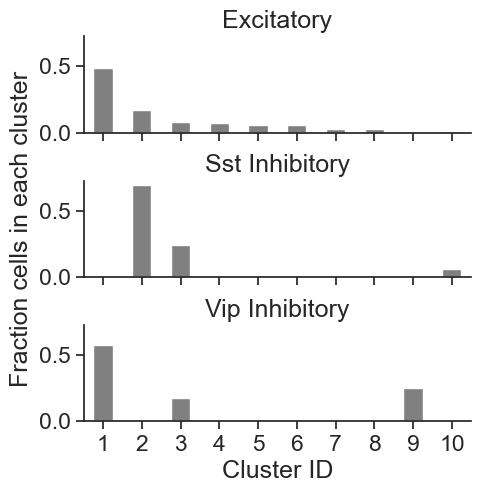

In [79]:

# Plot familiar clustering results
plotting.plot_cre_line_means_remapped(
    feature_matrix_familiar, cluster_meta_familiar,
    session_colors=False, experience_index=0, 
    folder="familiar_only_clustering", save_dir=save_dir)

plotting.plot_cluster_means_remapped(
    feature_matrix_familiar, cluster_meta_familiar,
    session_colors=False, experience_index=0, 
    save_dir=save_dir, folder="familiar_only_clustering")

plotting.plot_mean_cluster_heatmaps_remapped(
    feature_matrix_familiar, cluster_meta_familiar, None,
    session_colors=False, experience_index=0, 
    save_dir=save_dir, folder='familiar_only_clustering')

plotting.plot_fraction_cells_per_cluster_per_cre(
    cluster_meta_familiar, col_to_group="cre_line",
    save_dir=save_dir, folder="familiar_only_clustering")



array([<Axes: title={'center': 'Exc'}>, <Axes: title={'center': 'Sst'}>,
       <Axes: title={'center': 'Vip'}>, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >,
       <Axes: ylabel='Percent of cells in each cluster'>, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
       <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: xlabel='Exc'>,
       <Axes: xlabel='Sst'>, <Axes: xlabel='Vip'>], dtype=object)

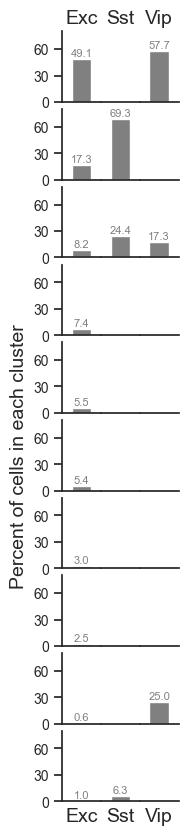

In [80]:

plotting.plot_percent_cells_per_cluster_per_cre_dominant_feature_xaxis(cluster_meta_familiar, col_to_group='cre_line', match_height=True,
                                                            cluster_order=None, save_dir=save_dir, folder='familiar_only_clustering')

In [81]:
# fam_label = cells_table_familiar[['ophys_experiment_id', 'experience_level']].copy()
# cluster_order_fam = np.sort(cluster_meta_familiar.cluster_id.unique())

# def _build_familiar_mdf(conditions, keep_col, keep_val):
#     df = loading.load_multi_session_df(
#         data_type=data_type, event_type='all', conditions=conditions,
#         inclusion_criteria=inclusion_criteria, interpolate=interpolate,
#         output_sampling_rate=output_sampling_rate, epoch_duration_mins=None)
#     df = df[df[keep_col] == keep_val].copy()
#     df['identifier'] = df.ophys_experiment_id.astype(str) + '_' + df.cell_specimen_id.astype(str)
#     df = df.set_index('identifier')
#     if 'experience_level' in df.columns:
#         df = df.drop(columns=['experience_level'])
#     # inner-join keeps only matched familiar (experiment, cell) pairs + the Familiar 1/2/3 label
#     df = df.join(fam_label[['experience_level']], how='inner').reset_index()
#     df = df.merge(cluster_meta_familiar.reset_index()[['cell_specimen_id', 'cluster_id', 'cre_line']],
#                   on='cell_specimen_id')
#     df = df.drop_duplicates(subset=['cell_specimen_id', 'ophys_experiment_id'])
#     return df

# change_mdf_familiar   = _build_familiar_mdf(['cell_specimen_id', 'is_change'], 'is_change', True)
# image_mdf_familiar    = _build_familiar_mdf(['cell_specimen_id', 'is_change'], 'is_change', False)
# omission_mdf_familiar = _build_familiar_mdf(['cell_specimen_id', 'omitted'],   'omitted',   True)


In [82]:
# plotting.plot_population_average_response_for_clusters_as_rows_all_response_types(image_mdf_familiar,
#                                                                            change_mdf_familiar,
#                                                                            omission_mdf_familiar,
#                                                                            suptitle=None,
#                                                                            cluster_order=cluster_order_fam,
#                                                                            familiar_only=True,
#                                                                            scalebar_y_shift=0,
#                                                                            show_response_labels=True,
#                                                                            response_panel_title=None,
#                                                                            ax=None);

In [83]:
# plotting.plot_cluster_properties_combined(
#     cluster_meta_familiar, feature_matrix_familiar, 'all',
#     image_mdf_familiar, change_mdf_familiar, omission_mdf_familiar,
#     familiar_only=True, add_depth=True, percent_cells_by_feature=True,
#     cluster_order=cluster_order_fam, sort_by=None, show_suptitle=False, save_dir=save_dir,
#     heatmap_xspan=(0.0, 0.26), means_xspan=(0.33, 0.39),
#     percent_cells_xspan=(0.46, 0.53),
#     response_xspan=(0.585, 0.88), response_wspace=0.6,
#     heatmap_ylabel_x=-1.3, apply_peak_threshold=True)

## Composite figures

### Figure S15 composite

Clustering methods (main 12-cluster, all cell types). Layout authority: VBO figures - revised v6.pptx, slide 20. A = 5-step pipeline (all-cells coding heatmap, inertia+gap-statistic stacked, UMAP, co-clustering matrix, cluster-mean heatmap). B = cluster means + cluster sizes. C = cluster average kernel weights grid. Requires the main-clustering cells run first (feature_matrix, cluster_meta, n_clusters, umap_df, coclustering_df, weights_df, run_params, gap_dict).

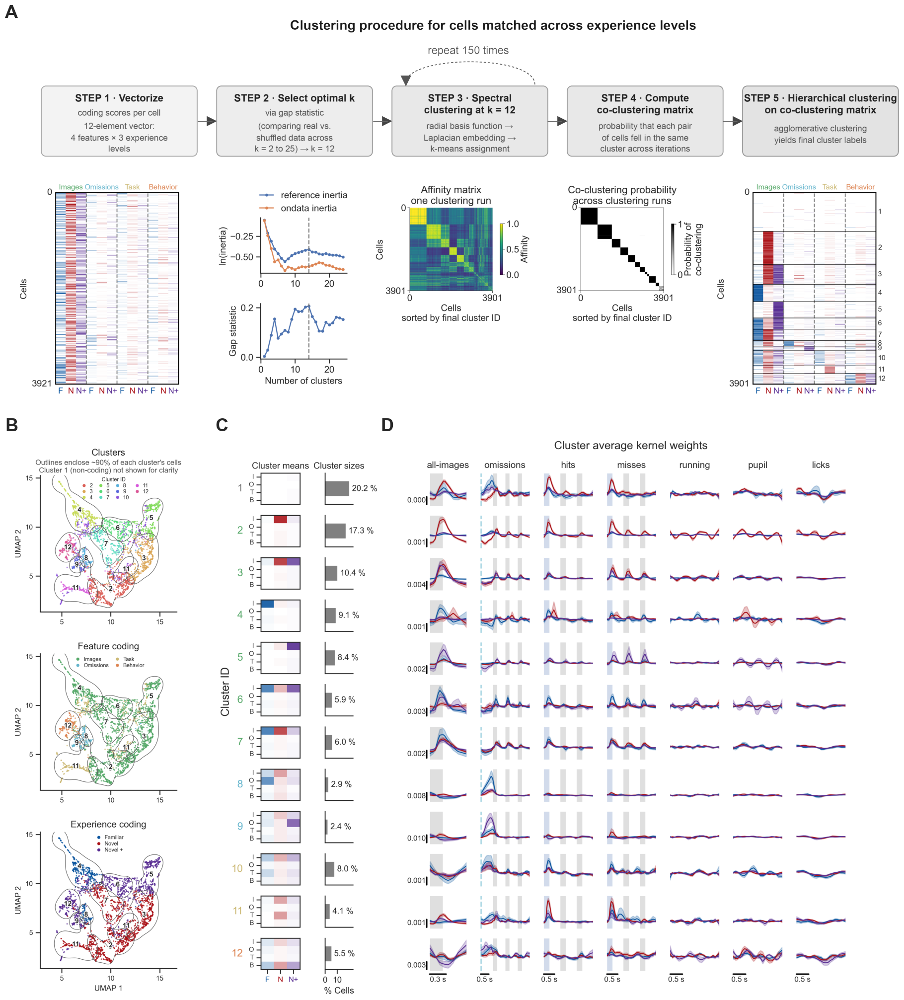

In [109]:
# ==========================================================================
# Figure S15 composite (Clustering methods). Originally slide 20; widened, with a new UMAP column (B).
# Each source figure is rendered then tiled into its measured slide box (S18 approach).
# Deps (run the main-clustering cells first): feature_matrix, cluster_meta, n_clusters,
# umap_df (cell 25), coclustering_df (cell 29), weights_df & run_params (cell 7),
# gap_dict (cell 17), image/change/omission mdfs (cell 9).
# ==========================================================================
import os
import numpy as np
import matplotlib.pyplot as plt

# ---- geometry (figure fractions, y top-down) ----
# Wider figure than slide 20: row 1 = panel A (schematic + A1-A5) across the full width;
# row 2 = B (UMAPs: clusters / feature / experience) | C (cluster means + sizes) | D (kernels).
# The row-2 top is computed at assembly time from the actual A-row image heights.
CROP = dict(x0=0.0, x1=1.0, y0=0.0, y1=1.0)
SLIDE_W_IN, SLIDE_H_IN = 9.0, 10.0      # virtual page; only its aspect matters
FIG_W = 18.0
cw = CROP['x1'] - CROP['x0']; ch = CROP['y1'] - CROP['y0']
aspect = (cw * SLIDE_W_IN) / (ch * SLIDE_H_IN)
FIG_H = FIG_W / aspect                   # = 20 in

# content boxes (x0, y0, x1, y1). A row as before (x only matters; heights are native aspect).
# B/C y-extents below are nominal (used to size the C render); final row-2 placement is dynamic.
CONTENT = {
    'Asch': (0.040, 0.020, 1.000, None),
    'A1':   (0.005, None, 0.220, None),
    'A2':   (0.228, None, 0.398, None),
    'A3':   (0.406, None, 0.591, None),   # same width as A4 -> same heatmap size
    'A4':   (0.597, None, 0.782, None),
    'A5':   (0.785, None, 1.000, None),
    'U':    (0.010, None, 0.225, None),   # new panel B column (UMAPs)
    'B':    (0.240, 0.44, 0.390, 0.99),   # cluster means + sizes (labelled C)
    'C':    (0.400, None, 1.000, 0.99),   # kernel grid (labelled D)
}
A_ROW_GAP = 0.035      # schematic bottom -> A1-A5 top spines (room for column titles)
A_DROP = {'A2': 0.025, 'A3': 0.015, 'A4': 0.015}   # extra downward shift (fig frac)
ROW2_GAP = 0.035       # A-row bottom -> row-2 top
LETTER_FS = 26

# ---- panel-A font sizes, specified at FINAL printed size ----
# The composite is FIG_W wide but will be printed at FINAL_WIDTH_IN (Cell Press double column = 178 mm).
# Each A sub-panel is rendered at its own source size and then scaled into its slot, so to get the same
# printed size everywhere the source font size is  final_pt * (src_width / slot_width) * (FIG_W / FINAL_WIDTH_IN).
FINAL_WIDTH_IN = 7.0          # 178 mm
A_FONT_FINAL_PT = 5.2         # ticks + axis labels in every A sub-panel (was 6.0 = Cell Press minimum; reduced ~2 pt as rendered)
A_TITLE_FINAL_PT = 5.7        # sub-panel titles (affinity / co-clustering)
A_SRC_W = {'A1': 2.8, 'A2': 2.9, 'A3': 6.0, 'A4': 6.0, 'A5': 2.8}   # source figure widths (in)
def _afs(key, final_pt=None):
    final_pt = A_FONT_FINAL_PT if final_pt is None else final_pt
    slot_w = (CONTENT[key][2] - CONTENT[key][0]) * FIG_W
    return final_pt * (A_SRC_W[key] / slot_w) * (FIG_W / FINAL_WIDTH_IN)

def _box(sx0, sy0, sx1, sy1, img):   # native-aspect box: anchor top-left + width
    w_frac = (sx1 - sx0) / cw
    h_px, w_px = img.shape[0], img.shape[1]
    h_frac = w_frac * (h_px / w_px) * (FIG_W / FIG_H)
    fx0 = (sx0 - CROP['x0']) / cw
    fy0 = (sy0 - CROP['y0']) / ch
    return [fx0, 1 - (fy0 + h_frac), w_frac, h_frac]

def _letter_xy(sx, sy):
    return (sx - CROP['x0']) / cw, 1 - (sy - CROP['y0']) / ch

def _crop(img, pad=6, axes='v'):
    arr = np.asarray(img); thr = 0.98 if arr.dtype.kind == 'f' else 250
    mask = ~(arr[..., :3] >= thr).all(axis=2)
    rows = np.where(mask.any(axis=1))[0]
    if len(rows) == 0: return arr
    r0, r1 = max(rows[0]-pad, 0), min(rows[-1]+pad+1, arr.shape[0])
    if axes == 'both':
        cols = np.where(mask.any(axis=0))[0]
        c0, c1 = max(cols[0]-pad, 0), min(cols[-1]+pad+1, arr.shape[1])
        return arr[r0:r1, c0:c1]
    return arr[r0:r1]

def _grab(axes='v'):
    fig = plt.gcf(); fig.set_dpi(300); fig.canvas.draw()
    img = _crop(np.asarray(fig.canvas.buffer_rgba()), axes=axes)
    plt.close(fig); return img

def _grab_ts(fig, ax_top, axes='v'):
    # like _grab, but also return the top-spine position as a fraction of the CROPPED image
    fig.set_dpi(300); fig.canvas.draw()
    _arr = np.asarray(fig.canvas.buffer_rgba()); _H = _arr.shape[0]
    _rows = np.where((~(_arr[..., :3] >= 250).all(axis=2)).any(axis=1))[0]
    _r0, _r1 = max(_rows[0]-6, 0)/_H, min(_rows[-1]+7, _H)/_H
    _ts = ((1 - ax_top.get_position().y1) - _r0) / (_r1 - _r0)
    _img = _crop(_arr, axes=axes)
    plt.close(fig)
    return _img, _ts

_cm_all = cluster_meta.copy(); _cm_all['cre_line'] = 'all'

# ---- A1 & A5: coding-score heatmaps rendered by ONE helper -> guaranteed same size ----
# A1 = cells sorted by cell_specimen_id (unclustered). A5 = cells sorted by cluster
# (adds cluster boundary lines + Cluster ID labels). Same figsize + fixed margins +
# vertical-only crop => identical width, so they place at identical size.
plt.close('all')
_fm_r, _cmapH, _vmaxH = plotting.remap_coding_scores_to_session_colors(feature_matrix)
_expc = list(utils.get_experience_level_colors())
_featc, _ = plotting.get_feature_colors_and_labels()

def _coding_heatmap(order, cluster_lines=False, key='A1'):
    _N = len(order)
    _fs = _afs(key)
    figH, axH = plt.subplots(figsize=(2.8, 3.4))
    figH.subplots_adjust(left=0.24, right=0.88, top=0.90, bottom=0.08)   # fixed margins -> same width
    sns.heatmap(_fm_r.loc[order].values, cmap=_cmapH, vmin=0, vmax=_vmaxH, cbar=False, ax=axH)
    for _x in [3, 6, 9]:
        axH.axvline(_x, color='gray', linestyle='--', linewidth=1)
    for _sp in axH.spines.values():
        _sp.set_visible(True); _sp.set_edgecolor('black'); _sp.set_linewidth(1)
    axH.set_ylabel('Cells', fontsize=_fs); axH.set_yticks([0, _N]); axH.set_yticklabels((0, _N), fontsize=_fs)
    axH.set_xticks(np.arange(12) + 0.5)
    _col_in = 2.8 * (0.88 - 0.24) / 12                       # width of one column (in)
    _fs_x = min(_fs, _col_in * 72 / (2 * 0.62))              # 'N+' must fit within a column
    axH.set_xticklabels(['F', 'N', 'N+'] * 4, rotation=0, fontsize=_fs_x)
    for _t, _cc in zip(axH.get_xticklabels(), _expc * 4):
        _t.set_color(_cc)
    axH.tick_params(length=0)
    # full feature names on one line; font shrunk so the longest ('Omissions') fits over its 3 columns
    HEADER_BOOST_PT = 1.5   # extra source points on top of the fitted size (there's still room)
    _fs_h = min(_fs, 3 * _col_in * 72 / (len('Omissions') * 0.58)) + HEADER_BOOST_PT
    for _fi, (_fn, _fx) in enumerate(zip(['Images', 'Omissions', 'Task', 'Behavior'], [1.5, 4.5, 7.5, 10.5])):
        axH.text(_fx, 1.01, _fn, transform=axH.get_xaxis_transform(), ha='center',
                 va='bottom', color=_featc[_fi], fontsize=_fs_h)
    if cluster_lines:
        _cids = cluster_meta.loc[order].cluster_id.values
        for _bb in np.where(np.diff(_cids) != 0)[0] + 1:
            axH.axhline(_bb, color='k', linewidth=0.5)
        for _cid in np.unique(_cids):
            _ix = np.where(_cids == _cid)[0]
            axH.text(12.2, (_ix[0] + _ix[-1]) / 2, str(int(_cid)), ha='left', va='center', fontsize=_fs * 0.75)
    else:
        pass   # cell-sorted: keep default orientation (flipped vs. before)
    return _grab_ts(figH, axH, 'v')   # (img, top-spine frac)

imgA1, _tsA1 = _coding_heatmap(np.sort(feature_matrix.index.values), cluster_lines=False, key='A1')
imgA5, _tsA5 = _coding_heatmap(cluster_meta.sort_values('cluster_id').index.values, cluster_lines=True, key='A5')

# ---- A2: inertia (top) + gap statistic (bottom), stacked ----
plt.close('all')
figA2, _ax = plt.subplots(2, 1, figsize=(2.9, 4.4))   # taller (was 3.4)
_x = len(gap_dict['gap'])
_ax[0].plot(np.arange(1, _x+1), gap_dict['reference_inertia'], 'o-', markersize=3)
_ax[0].plot(np.arange(1, _x+1), gap_dict['ondata_inertia'], 'o-', markersize=3)
_fs2 = _afs('A2')
_ax[0].legend(['reference inertia', 'ondata inertia'], fontsize=_fs2, frameon=False, loc='lower center',
              bbox_to_anchor=(0.5, 1.02), ncol=1, borderaxespad=0, handlelength=1.5)
_ax[0].set_ylabel('ln(inertia)', fontsize=_fs2)   # was 'Natural log of euclidean distance values' (too long at >= 6 pt)
_ax[0].axvline(n_clusters, linestyle='--', color='gray')
_ax[1].plot(np.arange(1, _x+1), gap_dict['gap'], 'o-', markersize=3)
_ax[1].set_ylabel('Gap statistic', fontsize=_fs2); _ax[1].set_xlabel('Number of clusters', fontsize=_fs2)
_ax[1].axvline(n_clusters, linestyle='--', color='gray')
for _a in _ax:
    _a.tick_params(labelsize=_fs2)
sns.despine(fig=figA2); figA2.tight_layout()
imgA2, _tsA2 = _grab_ts(figA2, _ax[0], 'v')

# ---- UMAP data for panel B (all cells minus outlier cluster 1 and far-out points) ----
_umap_df = pd.read_hdf(os.path.join(data_dir, 'umap_results_df.h5'), key='df')
_umap_df['cell_specimen_id'] = cluster_meta.index.values
_umap_df = _umap_df.set_index('cell_specimen_id')
_cm_no1 = cluster_meta[cluster_meta.cluster_id != 1]
_umap_no1 = _umap_df.loc[_cm_no1.index.values]
_keepA3 = _umap_no1[_umap_no1.x < 16].index.values   # drop far-out UMAP outliers too
_cm_no1 = _cm_no1.loc[_keepA3]
_umap_no1 = _umap_no1.loc[_keepA3]

# ---- A4: co-clustering matrix (styled like S18 panel B) ----
plt.close('all')
figA4, axA4 = plt.subplots(figsize=(6, 6))
plotting.plot_coclustering_matrix_sorted_by_cluster_size({'all': coclustering_df}, _cm_all,
                                                         cre_line='all', ax=axA4)
MAT_LABEL = 'Cells\nsorted by final cluster ID'
MAT_LABEL_FS, MAT_TITLE_FS = _afs('A4'), _afs('A4', A_TITLE_FINAL_PT)
axA4.set_xlabel(MAT_LABEL, fontsize=MAT_LABEL_FS); axA4.set_ylabel('Cells', fontsize=MAT_LABEL_FS, color='none')   # hidden ('Cells' is on the affinity matrix beside it); kept invisible so A3/A4 layouts stay identical
axA4.tick_params(labelsize=MAT_LABEL_FS)
axA4.set_title('Co-clustering probability\nacross clustering runs', fontsize=MAT_TITLE_FS, pad=10)
figA4.tight_layout()
_caxA4 = [a for a in figA4.axes if a is not axA4]
if _caxA4:
    _cbA4 = _caxA4[0]; _pA4 = _cbA4.get_position()
    _cbA4.set_position([_pA4.x0 + 0.015, _pA4.y0 + 0.20 * _pA4.height,
                        _pA4.width * 0.55, _pA4.height * 0.60])
    _cbA4.set_ylabel('Probability of\nco-clustering')
    _cbA4.yaxis.label.set_fontsize(MAT_LABEL_FS); _cbA4.tick_params(labelsize=MAT_LABEL_FS)
    for _sp in _cbA4.spines.values():
        _sp.set_visible(True); _sp.set_edgecolor('black'); _sp.set_linewidth(0.8)
imgA4, _tsA4 = _grab_ts(figA4, axA4, 'v')


# ---- A3: Step 3 visual -- RBF affinity matrix for one clustering run ----
# affinity = exp(-gamma * ||x_i - x_j||^2) on the 12-element coding-score vectors, gamma = 1
# (sklearn SpectralClustering default, as used for the clustering). Cells sorted by final cluster ID
# (same order as A5). Drawn with the SAME axes / colorbar geometry and fonts as the co-clustering
# matrix (A4), with extra room on top for a title, so the two heatmaps render at the same size.
from sklearn.metrics.pairwise import rbf_kernel
_ordA3 = cluster_meta.sort_values('cluster_id').index.values
_aff = rbf_kernel(feature_matrix.loc[_ordA3].values, gamma=1.0)
_NA3 = len(_ordA3)
_W4, _H4 = 6.0, 6.0                 # A4 figure size (in)
_TITLE_IN = 0.0                     # A4 now has a title too, so the geometry is identical
_H3 = _H4 + _TITLE_IN
def _pos_in_A3(pos):                # A4 fig-fraction box -> same inches in the taller A3 figure
    return [pos.x0, pos.y0 * _H4 / _H3, pos.width, pos.height * _H4 / _H3]
figA3 = plt.figure(figsize=(_W4, _H3))
axA3 = figA3.add_axes(_pos_in_A3(axA4.get_position()))
_imA3 = axA3.imshow(_aff, cmap='viridis', vmin=0, vmax=1, interpolation='nearest', aspect='equal',
                    extent=(0, _NA3, _NA3, 0))
_fsT = MAT_LABEL_FS
axA3.set_xticks([0, _NA3]); axA3.set_yticks([0, _NA3])
axA3.set_xticklabels([0, _NA3], fontsize=_fsT, rotation=0); axA3.set_yticklabels([0, _NA3], fontsize=_fsT)
axA3.set_xlabel(MAT_LABEL, fontsize=MAT_LABEL_FS); axA3.set_ylabel('Cells', fontsize=MAT_LABEL_FS)
axA3.set_title('Affinity matrix\none clustering run', fontsize=MAT_TITLE_FS, pad=10)
if _caxA4:
    _caxA3 = figA3.add_axes(_pos_in_A3(_cbA4.get_position()))
    _cb3 = figA3.colorbar(_imA3, cax=_caxA3, ticks=[0, 0.5, 1])
    _cb3.set_label('Affinity', fontsize=MAT_LABEL_FS)
    _cb3.ax.tick_params(labelsize=MAT_LABEL_FS)
    for _sp in _cb3.ax.spines.values():
        _sp.set_visible(True); _sp.set_edgecolor('black'); _sp.set_linewidth(0.8)
imgA3, _tsA3 = _grab_ts(figA3, axA3, 'v')
del _aff

# ---- B: cluster means (left) + cluster sizes (right), rows aligned via a shared grid ----
# cluster-ID label colours = each cluster's dominant feature (as in the Feature-coding UMAP); cluster 1 gray
if 'results_pivoted' not in globals():   # freed after cell 72
    results_pivoted = pd.read_hdf(os.path.join(loading.get_glm_results_dir(),
                                  'across_session_normalized_platform_results_pivoted.h5'), key='df')
_cmC = processing.get_coding_score_metrics_for_clusters(cluster_meta, results_pivoted)
_featcC = plotting.get_feature_colors_with_gray()
_featC_of = {c: _featcC[1 + processing.get_features_for_clustering().index(_cmC.loc[c, 'dominant_feature'])]
             for c in _cmC.index}
_featC_of[1] = (0.5, 0.5, 0.5)
plt.close('all')
_orderB = np.sort(cluster_meta.cluster_id.unique())
_nB = len(_orderB)
_cmB = cluster_meta.copy(); _cmB['cre_line'] = 'all'   # match plot_cluster_properties_combined (fractions across ALL cells)
# figsize matches the B box aspect (tall + narrow) so filling the box does NOT stretch it;
# larger overall so the small labels render cleanly.
_bw_in = (CONTENT['B'][2] - CONTENT['B'][0]) / cw * FIG_W
_bh_in = (CONTENT['B'][3] - CONTENT['B'][1]) / ch * FIG_H
figB = plt.figure(figsize=(_bw_in * 1.25, _bh_in * 1.25))
_axM = utils.placeAxesOnGrid(figB, dim=(_nB, 1), xspan=(0.16, 0.44), yspan=(0.08, 0.96),
                             sharex=True, sharey=True, hspace=0.35)
plotting.plot_mean_cluster_heatmaps_remapped(feature_matrix, _cmB, fontsize=9,
    cluster_order=_orderB, sort_by=None, session_colors=True, annotate=False,
    abbreviate_features=True, plot_as_rows=True, ax=_axM)
_axS = utils.placeAxesOnGrid(figB, dim=(_nB, 1), xspan=(0.62, 0.82), yspan=(0.08, 0.96),
                             sharex=False, hspace=0.35)
_axS = list(np.atleast_1d(_axS))
plotting.plot_percent_cells_per_cluster_per_cre_as_rows(_cmB, cre_line='all',
    familiar_only=False, cluster_order=_orderB, sort_by=None, ax=_axS,
    size_label_offset=2, size_label_fontsize=11)
for _a in list(_axM)[:-1]:          # share x: F/N/N+ only on the bottom means row
    _a.set_xticklabels([]); _a.tick_params(bottom=False, labelbottom=False)
_axM[-1].set_xticks(np.arange(3) + 0.5)
_axM[-1].set_xticklabels(['F', 'N', 'N+'], fontsize=10)
for _t, _cc in zip(_axM[-1].get_xticklabels(), list(utils.get_experience_level_colors())):
    _t.set_color(_cc)
for _a in _axS:                     # remove gray dashed reference lines in the sizes column
    for _l in list(_a.lines):
        _l.remove()
_axS[-1].tick_params(labelsize=11)  # bigger xtick font in sizes column
figB.canvas.draw()   # add cluster-id labels to the left of each means row
for _i, _cid in enumerate(_orderB):
    _pp = _axM[_i].get_position()
    figB.text(_pp.x0 - 0.10, (_pp.y0 + _pp.y1) / 2, str(int(_cid)),
              ha='right', va='center', fontsize=14, color=_featC_of.get(_cid, 'k'))
figB.text(0.055, 0.52, 'Cluster ID', rotation=90, va='center', ha='center', fontsize=15)
figB.canvas.draw()
_arrB = np.asarray(figB.canvas.buffer_rgba()); _Hb = _arrB.shape[0]
_rowsB = np.where((~(_arrB[..., :3] >= 250).all(axis=2)).any(axis=1))[0]
_r0b, _r1b = max(_rowsB[0]-6, 0)/_Hb, min(_rowsB[-1]+7, _Hb)/_Hb      # 'both'-crop row bounds
_B_bt = (1 - max(a.get_position().y1 for a in _axM) - _r0b) / (_r1b - _r0b)   # in CROPPED image
_B_bb = (1 - min(a.get_position().y0 for a in _axM) - _r0b) / (_r1b - _r0b)
imgB = _grab('both')

# ---- C: cluster average kernel weights grid ----
plt.close('all')
plotting.plot_cluster_kernel_overlays_by_experience(
    weights_df, run_params, kernels_to_plot=None, linewidth=1, share_y_across='row',
    cell_type=None, show_all_clusters=False, min_cluster_fraction=0)
_Cfig = plt.gcf()
for _i in range(0, len(_Cfig.axes), 7):
    _Cfig.axes[_i].set_ylabel('')
for _txt in list(_Cfig.texts):
    if _txt.get_text() == 'Cluster ID':
        _txt.remove()
_Cfig.set_size_inches(8.0, 9.8); _Cfig.canvas.draw()
_arrC = np.asarray(_Cfig.canvas.buffer_rgba()); _Hc = _arrC.shape[0]
_rowsC = np.where((~(_arrC[..., :3] >= 250).all(axis=2)).any(axis=1))[0]
_r0c, _r1c = max(_rowsC[0]-6, 0)/_Hc, min(_rowsC[-1]+7, _Hc)/_Hc      # 'v'-crop bounds (top-down frac)
_C_bt = (1 - max(a.get_position().y1 for a in _Cfig.axes) - _r0c) / (_r1c - _r0c)  # in CROPPED image
_C_bb = (1 - min(a.get_position().y0 for a in _Cfig.axes) - _r0c) / (_r1c - _r0c)
imgC = _grab('v')

# ---- B (new panel): UMAPs colored by cluster, dominant feature, dominant experience level ----
# Same cells, outlines and labels as A3 / Figure 5B. Feature / experience colors are each cluster's
# dominant feature / experience level (processing.get_coding_score_metrics_for_clusters, as Fig 5B/5F).
import contourpy
import matplotlib.patheffects as _pe
from matplotlib.path import Path as _Path
from matplotlib.lines import Line2D as _L2D
from scipy.ndimage import gaussian_filter as _gf
plt.close('all')
if 'results_pivoted' not in globals():   # freed after cell 72
    results_pivoted = pd.read_hdf(os.path.join(loading.get_glm_results_dir(),
                                  'across_session_normalized_platform_results_pivoted.h5'), key='df')
_cmU = processing.get_coding_score_metrics_for_clusters(cluster_meta, results_pivoted)
_expcU = list(utils.get_experience_level_colors())
_featcU = plotting.get_feature_colors_with_gray()
_exp_of = {c: _expcU[utils.get_experience_levels().index(_cmU.loc[c, 'dominant_experience_level'])] for c in _cmU.index}
_feat_of = {c: _featcU[1 + processing.get_features_for_clustering().index(_cmU.loc[c, 'dominant_feature'])]
            for c in _cmU.index}
_idsU = np.sort(_cm_no1.cluster_id.unique())
_clu_of = dict(zip(_idsU, sns.color_palette('hls', len(_idsU))))      # same palette as A3
_cidU = _cm_no1.loc[_umap_no1.index, 'cluster_id'].values

def _outlines_and_labels(a, bw=0.5, frac=0.9, min_island=0.05, overrides={4: {'frac': 0.99}}, fs=9):
    xe = np.linspace(_umap_no1.x.min() - 1, _umap_no1.x.max() + 1, 301)
    ye = np.linspace(_umap_no1.y.min() - 1, _umap_no1.y.max() + 1, 301)
    xc, yc = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
    for c in _idsU:
        if c == 10:
            continue
        o = {'bw': bw, 'frac': frac, **overrides.get(c, {})}
        xy = _umap_no1.loc[_cm_no1.index[_cm_no1.cluster_id == c], ['x', 'y']].values
        h, _, _ = np.histogram2d(xy[:, 0], xy[:, 1], bins=[xe, ye])
        z = _gf(h, sigma=o['bw'] / (xe[1] - xe[0])).T
        ix = np.clip(np.searchsorted(xe, xy[:, 0]) - 1, 0, len(xc) - 1)
        iy = np.clip(np.searchsorted(ye, xy[:, 1]) - 1, 0, len(yc) - 1)
        lines = contourpy.contour_generator(xc, yc, z).lines(np.quantile(z[iy, ix], 1 - o['frac']))
        paths = [_Path(l) for l in lines]
        for k, (l, pth) in enumerate(zip(lines, paths)):
            if any(q.contains_point(l[0]) for j, q in enumerate(paths) if j != k):
                continue
            inside = pth.contains_points(xy)
            if inside.mean() < min_island:
                continue
            a.plot(l[:, 0], l[:, 1], color='0.3', lw=0.6, zorder=5)
            cen = xy[inside].mean(axis=0)
            a.text(cen[0], cen[1], str(int(c)), fontsize=fs, fontweight='bold', ha='center', va='center',
                   path_effects=[_pe.withStroke(linewidth=2, foreground='w')], zorder=10)

figU, axU = plt.subplots(3, 1, figsize=(3.8, 10.4))
_legU = [None,
         (['Images', 'Omissions', 'Task', 'Behavior'], list(_featcU[1:5])),
         (utils.get_experience_levels(), _expcU[:3])]
for a, col_of, title, leg in zip(axU, [_clu_of, _feat_of, _exp_of],
                                 ['Clusters', 'Feature coding', 'Experience coding'], _legU):
    a.scatter(_umap_no1.x, _umap_no1.y, s=3, c=[col_of[c] for c in _cidU], linewidths=0, alpha=0.8)
    _outlines_and_labels(a)
    # equal scaling on x and y AND a square box: give both axes the same data range (the larger one)
    _xr, _yr = (_umap_no1.x.min(), _umap_no1.x.max()), (_umap_no1.y.min(), _umap_no1.y.max())
    _half = max(_xr[1] - _xr[0], _yr[1] - _yr[0]) / 2 + 0.6
    _cx, _cy = sum(_xr) / 2, sum(_yr) / 2
    a.set_xlim(_cx - _half, _cx + _half); a.set_ylim(_cy - _half, _cy + _half)
    a.set_aspect('equal', adjustable='box')
    a.set_title(title, fontsize=12, pad=26 if title == 'Clusters' else 6)
    if title == 'Clusters':
        a.text(0.5, 1.01, "Outlines enclose ~90% of each cluster's cells\nCluster 1 (non-coding) not shown for clarity", transform=a.transAxes,
               ha='center', va='bottom', fontsize=9.5, color='0.3')
        # cluster colour key in the empty area above the centre of the embedding (data coords;
        # nudge CLU_LEG_XY if it touches points)
        CLU_LEG_XY = (10.3, 15.4)   # inside the axes, in the empty area above the embedding
        a.legend([_L2D([], [], marker='o', ls='', ms=4, mfc=_clu_of[c], mec='none') for c in _idsU],
                 [str(int(c)) for c in _idsU], title='Cluster ID', title_fontsize=7, loc='upper center', bbox_to_anchor=CLU_LEG_XY,
                 bbox_transform=a.transData, ncol=4, fontsize=7, frameon=False, handletextpad=0.05,
                 columnspacing=0.5, labelspacing=0.15, borderpad=0.1)
    a.set_ylabel('UMAP 2', fontsize=10); a.set_xlabel('')
    a.set_xticks([5, 10, 15]); a.set_yticks([5, 10, 15]); a.tick_params(labelsize=9)   # same ticks on x and y
    if leg is not None:
        a.legend([_L2D([], [], marker='o', ls='', ms=4, mfc=c, mec='none') for c in leg[1]], leg[0],
                 loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=1 if title == 'Experience coding' else 2, fontsize=7, frameon=False,
                 handletextpad=0.1, columnspacing=0.6, labelspacing=0.2, borderpad=0.1)
    sns.despine(ax=a)
axU[-1].set_xlabel('UMAP 1', fontsize=10)
figU.tight_layout(h_pad=1.2)
# measure first-axis top spine and last-axis bottom spine as fractions of the cropped image,
# so B can be aligned to C's first/last rows at assembly
figU.set_dpi(300); figU.canvas.draw()
_arrU = np.asarray(figU.canvas.buffer_rgba()); _HU = _arrU.shape[0]
_rowsU = np.where((~(_arrU[..., :3] >= 250).all(axis=2)).any(axis=1))[0]
_r0u, _r1u = max(_rowsU[0] - 6, 0) / _HU, min(_rowsU[-1] + 7, _HU) / _HU
_U_bt = ((1 - axU[0].get_position().y1) - _r0u) / (_r1u - _r0u)
_U_bb = ((1 - axU[-1].get_position().y0) - _r0u) / (_r1u - _r0u)
imgU = _crop(_arrU, axes='both'); plt.close(figU)

# ---- A schematic banner (STEP 1-5), tight-cropped ----
_schem = plt.imread('/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/'
                    'FinalDataAssetsforCodeOcean/schematics/Figure 5/'
                    'clustering_procedure_schematic_grayscale.png')
_schem = _schem[int(0.11 * _schem.shape[0]):]   # drop stray top mark + whitespace above title
imgAsch = _crop(_schem, axes='both')

# ---- assemble ----
def _disp_h(sx0, sx1, img):
    return (sx1 - sx0) / cw * (img.shape[0] / img.shape[1]) * (FIG_W / FIG_H)
fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor='white')
_sx0, _sy0, _sx1, _ = CONTENT['Asch']
_h_sch = _disp_h(_sx0, _sx1, imgAsch)
a = fig.add_axes([_sx0, 1 - (_sy0 + _h_sch), _sx1 - _sx0, _h_sch]); a.imshow(imgAsch, aspect='auto'); a.axis('off')
# A1-A5: align their TOP SPINES at a common y just below the schematic (each keeps native aspect)
_imgs_A = {'A1': imgA1, 'A2': imgA2, 'A3': imgA3, 'A4': imgA4, 'A5': imgA5}
_TS = {'A1': _tsA1, 'A2': _tsA2, 'A3': _tsA3, 'A4': _tsA4, 'A5': _tsA5}
_COMMON = _sy0 + _h_sch + A_ROW_GAP
_a_bottom = 0
for key, img in _imgs_A.items():
    b = CONTENT[key]; _w = b[2] - b[0]; _h = _disp_h(b[0], b[2], img)
    _itop = _COMMON + A_DROP.get(key, 0) - _TS[key] * _h
    a = fig.add_axes([b[0], 1 - (_itop + _h), _w, _h])
    a.imshow(img, aspect='auto'); a.axis('off')
    _a_bottom = max(_a_bottom, _itop + _h)
ROW2 = _a_bottom + ROW2_GAP           # top of row 2 (figure fraction from top)

# D (kernel grid) fills its box; its cluster rows span _C_bt.._C_bb of the image
_cb = CONTENT['C']; _c_top = ROW2 + 0.01; _c_h = _cb[3] - _c_top
a = fig.add_axes([_cb[0], 1 - (_c_top + _c_h), _cb[2] - _cb[0], _c_h])
a.imshow(imgC, aspect='auto'); a.axis('off')

# C (cluster means + sizes): scaled + positioned so its rows match D's rows exactly
_c_band_t, _c_band_b = _c_top + _C_bt * _c_h, _c_top + _C_bb * _c_h
_H_b = (_c_band_b - _c_band_t) / (_B_bb - _B_bt)
_b_w = _H_b * (imgB.shape[1] / imgB.shape[0]) / (FIG_W / FIG_H)
_b_top = _c_band_t - _B_bt * _H_b
a = fig.add_axes([CONTENT['B'][0], 1 - (_b_top + _H_b), _b_w, _H_b])
a.imshow(imgB, aspect='auto'); a.axis('off')

# B (UMAPs): native aspect, fit inside its column from the row-2 top to the figure bottom
# B (UMAPs): native aspect, scaled so the top spine of the first UMAP aligns with C's first row and
# the bottom spine of the last UMAP aligns with C's last row
_ux0 = CONTENT['U'][0]
_mb_t, _mb_b = _b_top + _B_bt * _H_b, _b_top + _B_bb * _H_b        # C's row band (fig frac from top)
_u_h = (_mb_b - _mb_t) / (_U_bb - _U_bt)
_u_w = _u_h * (imgU.shape[1] / imgU.shape[0]) / (FIG_W / FIG_H)
_u_top = _mb_t - _U_bt * _u_h
if _ux0 + _u_w > CONTENT['B'][0] - 0.005:
    print(f'note: panel B is {_ux0 + _u_w - CONTENT["B"][0] + 0.005:.3f} (fig frac) wider than its column; '
          'narrow figU figsize or move C right')
a = fig.add_axes([_ux0, 1 - (_u_top + _u_h), _u_w, _u_h]); a.imshow(imgU, aspect='auto'); a.axis('off')

LETTERS = {'A': (0.000, 0.005), 'B': (0.000, ROW2 - 0.012),
           'C': (CONTENT['B'][0] - 0.005, ROW2 - 0.012), 'D': (CONTENT['C'][0] + 0.02, ROW2 - 0.012)}
for lbl, (lx, ly) in LETTERS.items():
    fig.text(lx, 1 - ly, lbl, ha='left', va='top', fontsize=LETTER_FS, fontweight='bold')
utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_S15_composite', formats=['.png', '.pdf'])
plt.show()


### Figure S16 composite
Validation of cluster assignments. Layout authority: VBO figures - revised v6.pptx, slide 21 (S16). A-J tiled into measured regions; E is the prediction-strength schematic. Run the notebook through the 'Validate selection of k' section first (needs cluster_meta, prediction_scores_for_clusters, df, mean_ct_ps_df, umap_df, ps_scores_df, mean_scores_df).

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:788: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.arange(1, n_clusters+1))
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:788: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.arange(1, n_clusters+1))
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_22840/2922939517.py:193: UserWarning: 

The `join` parameter is deprecated and will be re

gutter audit: clean.


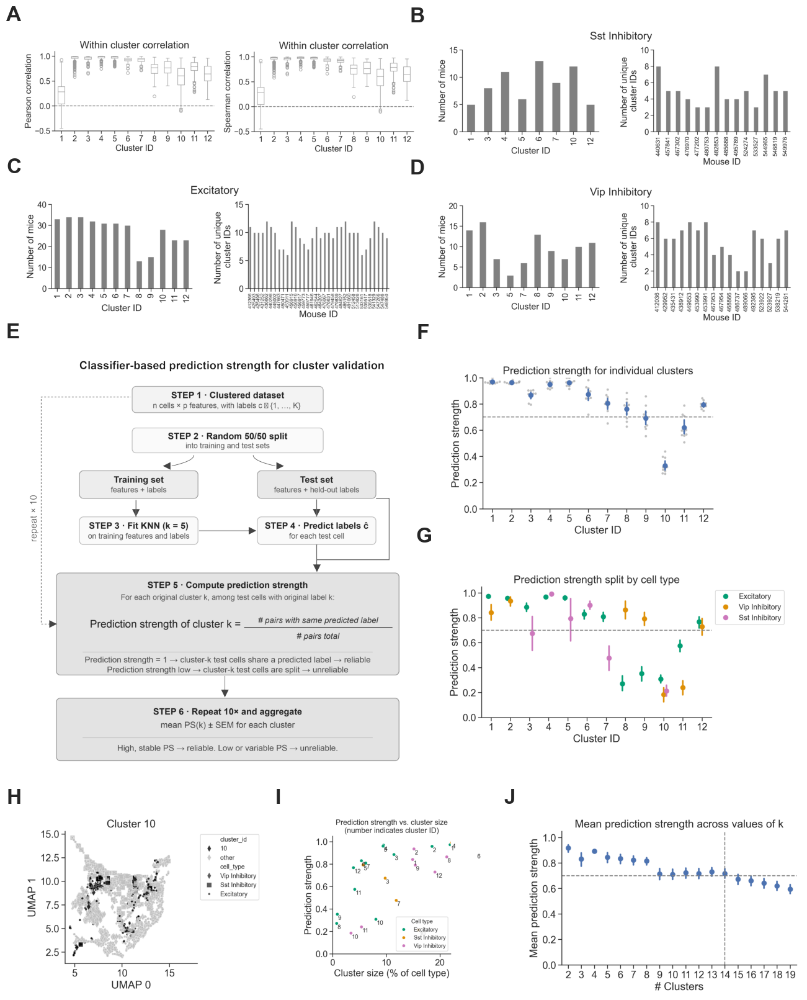

In [85]:
# ============================================================================
# Figure S16 composite -- Validation of cluster assignments.
# Layout authority: VBO figures - revised v6.pptx, slide 21 (S16).
# Panels:
#   A  within-cluster correlation: Pearson (left) + Spearman (right)
#        -> plotting.plot_within_cluster_correlations(spearman=False / True), captured & hconcat'd
#   B  Excitatory | C  SST inhibitory | D  VIP inhibitory  (Number of mice per cluster +
#        Number of unique cluster IDs per mouse) -> plotting.plot_cluster_breakdown_by_mouse
#        (one fig per cre line; captured together and mapped by suptitle)
#   E  schematic image (prediction_strength_schematic_grayscale)
#   F  prediction strength for individual clusters        (replicates notebook cell 101)
#   G  prediction strength split by cell type             (replicates notebook cell 109 plot)
#   H  example UMAP, cluster 10 highlighted               (replicates notebook cell 116 plot)
#   I  prediction strength vs cluster size (per cell type) (replicates notebook cell 112)
#   J  mean prediction strength across values of k        (replicates notebook cell 121)
# Build method = image-tiling (each panel rendered to its own figure, autocropped, tiled into
# a measured region via panel(), which enforces the skill's letter-gutter rule).
# PREREQ: run the notebook through the "Validate selection of k" section so these exist:
#   cluster_meta (with within_cluster_correlation_p / _s columns), feature_matrix, cre_lines,
#   prediction_scores_for_clusters (cell 100), df (cell 109), mean_ct_ps_df (cell 111),
#   umap_df (post cells 114-116; cluster_id already remapped to 10/'other'),
#   ps_scores_df + mean_scores_df (cell 119)
# ============================================================================
import io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
sns.set_context('notebook', font_scale=1.5)

# ---- configurable constants ----
E_PATH = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 5/prediction_strength_schematic_grayscale.png'
CAPTURE_DPI = 200
FIG_W, FIG_H = 13.0, 16.33         # derived from the slide crop aspect (0.796, portrait)

# measured slide geometry (slide 21; slide fraction, y top-down).
# LETTER = panel-letter anchor (top-left); CONTENT = the plot's content box (where the plot sits).
# Letters live in the left/top margin (the skill's gutter); plots go in CONTENT, clamped so they
# never enter the letter gutter (GX/GY below). This reproduces the slide's panel positions/sizes.
LETTER = {
    'A': (0.010, 0.018), 'B': (0.498, 0.019), 'C': (0.010, 0.156), 'D': (0.498, 0.157),
    'E': (0.010, 0.305), 'F': (0.506, 0.306), 'G': (0.505, 0.490), 'H': (0.010, 0.727),
    'I': (0.335, 0.727), 'J': (0.612, 0.727),
}
CONTENT = {
    'A': (0.031, 0.042, 0.506, 0.141), 'B': (0.531, 0.025, 0.959, 0.165),
    'C': (0.033, 0.180, 0.474, 0.322), 'D': (0.531, 0.185, 0.959, 0.325),
    'E': (0.037, 0.338, 0.485, 0.730), 'F': (0.543, 0.342, 0.869, 0.502),
    'G': (0.542, 0.531, 0.956, 0.691), 'H': (0.031, 0.752, 0.360, 0.911),
    'I': (0.366, 0.752, 0.589, 0.901), 'J': (0.638, 0.752, 0.971, 0.916),
}
_cx0, _cx1, _cy0, _cy1 = 0.0, 0.975, 0.0, 0.918
def _m(x, y):                    # slide fraction -> figure fraction (top-down)
    return ((x - _cx0) / (_cx1 - _cx0), (y - _cy0) / (_cy1 - _cy0))
GX, GY = 20 / 72 / FIG_W, 28 / 72 / FIG_H   # skill label-gutter (letter only), figure fraction

# ---- capture helpers ----
def _save_fig_to_img(fig):
    buf = io.BytesIO()
    fig.savefig(buf, dpi=CAPTURE_DPI, bbox_inches='tight', facecolor='white', format='png')
    plt.close(fig); buf.seek(0)
    return mpimg.imread(buf)

def _capture(plot_call, post=None):
    """Run a plotting fn/closure that creates ONE new figure; return it as an image."""
    pre = set(plt.get_fignums())
    plot_call()
    new = [n for n in plt.get_fignums() if n not in pre]
    fig = plt.figure(new[-1] if new else plt.get_fignums()[-1])
    if post is not None:
        post(fig)
    return _save_fig_to_img(fig)

def _capture_all(plot_call):
    """Run a fn that creates SEVERAL new figures; return {suptitle: image}."""
    pre = set(plt.get_fignums())
    plot_call()
    new = [n for n in plt.get_fignums() if n not in pre]
    out = {}
    for n in new:
        fig = plt.figure(n)
        title = fig._suptitle.get_text() if getattr(fig, '_suptitle', None) is not None else str(n)
        out[title] = _save_fig_to_img(fig)
    return out

def _autocrop(im, thresh=0.985, margin_frac=0.02):
    rgb = im[..., :3] if (im.ndim == 3 and im.shape[2] >= 3) else im
    mask = (rgb < thresh).any(axis=2) if rgb.ndim == 3 else (rgb < thresh)
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return im
    my = int((ys.max() - ys.min() + 1) * margin_frac); mx = int((xs.max() - xs.min() + 1) * margin_frac)
    r0 = max(0, ys.min() - my); r1 = min(im.shape[0] - 1, ys.max() + my)
    c0 = max(0, xs.min() - mx); c1 = min(im.shape[1] - 1, xs.max() + mx)
    return im[r0:r1+1, c0:c1+1]

def _cap_spine(plot_call, post=None, spine_ax=0):
    """Capture ONE new figure; return (autocropped_image, spine_top_frac, spine_bot_frac),
    where the fracs locate the y-axis spine (axes[spine_ax]) top/bottom as TOP-DOWN fractions
    of the cropped image. Lets the composite align spine endpoints across panels at run time."""
    pre = set(plt.get_fignums()); plot_call()
    new = [n for n in plt.get_fignums() if n not in pre]
    fig = plt.figure(new[-1] if new else plt.get_fignums()[-1])
    if post is not None: post(fig)
    return _spine_save(fig, spine_ax)

def _capture_all_spine(plot_call, spine_ax=0, post=None):
    """Like _capture_all but returns {suptitle: (image, spine_top_frac, spine_bot_frac)}.
    `post(fig)` is applied to each figure before measuring/saving."""
    pre = set(plt.get_fignums()); plot_call()
    new = [n for n in plt.get_fignums() if n not in pre]
    out = {}
    for n in new:
        fig = plt.figure(n)
        if post is not None: post(fig)
        title = fig._suptitle.get_text() if getattr(fig, '_suptitle', None) is not None else str(n)
        out[title] = _spine_save(fig, spine_ax)
    return out

def _spine_save(fig, spine_ax, pad=0.04):
    """Save TIGHT with a small white margin (pad inches) so overflowing suptitles / rotated
    x-tick labels are neither clipped nor flush to the edge. Return (image, spine_top_frac,
    spine_bot_frac) as top-down fractions of the padded image (fractions account for pad)."""
    fig.canvas.draw(); r = fig.canvas.get_renderer()
    tb = fig.get_tightbbox(r)                       # inches, includes overflow
    ab = fig.axes[spine_ax].get_window_extent(r)    # display px
    ay0_in, ay1_in = ab.y0 / fig.dpi, ab.y1 / fig.dpi
    H = tb.height + 2 * pad
    st = ((tb.y1 + pad) - ay1_in) / H               # top-down frac of spine top (padded image)
    sb = ((tb.y1 + pad) - ay0_in) / H               # top-down frac of spine bottom
    buf = io.BytesIO()
    fig.savefig(buf, dpi=CAPTURE_DPI, bbox_inches='tight', pad_inches=pad, facecolor='white', format='png')
    plt.close(fig); buf.seek(0)
    return mpimg.imread(buf), st, sb

def _hconcat(imgs, gap_px=30):
    """Pad to common height and concatenate side by side with a white gap (for panel A)."""
    h = max(im.shape[0] for im in imgs); ch = imgs[0].shape[2]
    parts = []
    for k, im in enumerate(imgs):
        if im.shape[0] < h:
            im = np.concatenate([im, np.ones((h-im.shape[0], im.shape[1], ch), dtype=im.dtype)], axis=0)
        parts.append(im)
        if k < len(imgs) - 1:
            parts.append(np.ones((h, gap_px, ch), dtype=im.dtype))
    return np.concatenate(parts, axis=1)

# ---- per-panel capture tweaks (applied to the captured figure, not the standalone fn) ----
def _fix_A(fig, pts=3):
    for ax in fig.axes:
        if ax.title.get_text():
            ax.title.set_fontsize(ax.title.get_fontsize() + pts)   # +3 pt total
        if ax.get_ylabel():
            ax.set_ylabel(ax.get_ylabel().replace(chr(10), ' '))   # one-line y-label

_TITLE_FIX = {'SST inhibitory': 'Sst Inhibitory', 'VIP inhibitory': 'Vip Inhibitory', 'Excitatory': 'Excitatory'}
def _fix_bcd(fig):
    # B/C/D: rotate left-subplot (Cluster ID) x-tick labels 90 deg; proper-case the cell-type title
    if fig.axes:
        for t in fig.axes[0].get_xticklabels():
            t.set_rotation(90)
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_text(_TITLE_FIX.get(fig._suptitle.get_text(), fig._suptitle.get_text()))

# ---- render panels to images ----
img = {}

# A: Pearson (left) + Spearman (right)
img_P, _stP, _sbP = _cap_spine(lambda: plotting.plot_within_cluster_correlations(
    cluster_meta, sort_order=None, spearman=False, suffix=''), post=_fix_A)
img_S = _autocrop(_capture(lambda: plotting.plot_within_cluster_correlations(
    cluster_meta, sort_order=None, spearman=True, suffix=''), post=_fix_A))
img['A'] = _hconcat([img_P, img_S])
spine_A = (_stP, _sbP)   # Pearson & Spearman share figsize -> equal height -> fracs valid for hconcat

# B, C, D: one figure per cre line, mapped by suptitle; measure B(SST) left-subplot spine
_bcd = _capture_all_spine(lambda: plotting.plot_cluster_breakdown_by_mouse(cluster_meta), spine_ax=0, post=_fix_bcd)
_title_to_panel = {'Sst Inhibitory': 'B', 'Excitatory': 'C', 'Vip Inhibitory': 'D'}  # titles renamed in _fix_bcd
spine = {}
for _title, (_im, _st, _sb) in _bcd.items():
    if _title in _title_to_panel:
        _p = _title_to_panel[_title]; img[_p] = _im; spine[_p] = (_st, _sb)
spine_B, spine_C, spine_D = spine['B'], spine['C'], spine['D']

# E: schematic
img['E'] = mpimg.imread(E_PATH)

# F: prediction strength for individual clusters (cell 101)
def _F():
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.swarmplot(data=prediction_scores_for_clusters, x='cluster_id', y='cluster_strength',
                  color='gray', alpha=0.5, size=4, ax=ax)
    sns.pointplot(data=prediction_scores_for_clusters, x='cluster_id', y='cluster_strength',
                  join=False, zorder=1000, ax=ax)
    ax.set_title('Prediction strength for individual clusters'); ax.set_ylabel('Prediction strength')
    ax.set_xlabel('Cluster ID'); ax.set_ylim(0, 1); ax.axhline(0.7, linestyle='--', color='gray')
img['F'] = _autocrop(_capture(_F))

# G: prediction strength split by cell type (cell 109 plot; uses df from cell 109)
def _G():
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.pointplot(data=df, x='cluster_id', y='cluster_strength', hue='cell_type',
                  palette=utils.get_cell_type_colors(), join=False, dodge=0.3, ax=ax)
    ax.legend(bbox_to_anchor=(1, 1), fontsize='x-small', title='')
    ax.set_title('Prediction strength split by cell type'); ax.set_ylabel('Prediction strength')
    ax.set_xlabel('Cluster ID'); ax.set_ylim(0, 1.05); ax.axhline(0.7, linestyle='--', color='gray')
img['G'] = _autocrop(_capture(_G))

# H: example UMAP, cluster 10 (cell 116 plot; umap_df already remapped to 10/'other')
def _H():
    fig, ax = plt.subplots(figsize=(5, 4))
    markers_dict = {'Excitatory': '.', 'Sst Inhibitory': 's', 'Vip Inhibitory': 'd'}
    sns.scatterplot(data=umap_df, x='x', y='y', s=60, ax=ax, hue='cluster_id',
                    hue_order=[10, 'other'], style='cell_type', palette=['#000000', '#BFBFBF'],
                    markers=markers_dict, linewidth=0.3, alpha=0.8, edgecolor='w')
    ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2'); ax.axis('square')
    ax.legend(fontsize='xx-small', title_fontsize='xx-small', bbox_to_anchor=(1, 1)); ax.set_title('Cluster 10')
img['H'] = _autocrop(_capture(_H))

# I: prediction strength vs cluster size, per cell type (cell 112)
def _I():
    fig, ax = plt.subplots(figsize=(4, 4))
    sns.scatterplot(data=mean_ct_ps_df, x='percent_cells', y='cluster_strength',
                    hue='cell_type', palette=utils.get_cell_type_colors(), ax=ax)
    ax.set_xlim(0, 22); ax.set_ylim(0, 1.05); ax.set_ylabel('Prediction strength')
    ax.set_xlabel('Cluster size (% of cell type)')
    ax.set_title('Prediction strength vs. cluster size\n(number indicates cluster ID)', fontsize=14)
    for row in range(len(mean_ct_ps_df)):
        rd = mean_ct_ps_df.iloc[[row]]
        ax.text(s=str(rd.cluster_id.values[0]), fontsize=11, ha='left', va='top',
                x=rd.percent_cells.values[0]+0.15, y=rd.cluster_strength.values[0]-0.01)
    ax.legend(title='Cell type', fontsize='xx-small', title_fontsize='xx-small')
img['I'] = _autocrop(_capture(_I))

# J: mean prediction strength across k (cell 121)
def _J():
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.pointplot(data=ps_scores_df, y='prediction_strength', x='n_clusters', ax=ax, linestyle='none')
    ax.set_ylim(0, 1.05); ax.set_xlabel('# Clusters'); ax.set_ylabel('Mean prediction strength')
    ax.set_title('Mean prediction strength across values of k'); ax.axhline(0.7, linestyle='--', color='gray')
    selected_k = mean_scores_df[mean_scores_df['mean_ps'] >= 0.7].sort_values('n_clusters')['n_clusters'].values[-1]
    ax.axvline(x=selected_k - np.min(mean_scores_df['n_clusters']), linestyle='--', color='gray')
img['J'] = _autocrop(_capture(_J))

# ---- assemble: plots in content boxes; letters in the margin gutter ----
# A&B and C&D are spine-aligned pairs (the right panel of each pair is placed in its box and
# defines the spine band; the left panel is scaled so its y-spine top/bottom match). E-J fill
# their content box. Letters are drawn ON TOP (fig.text) -- nothing masks the gutters; plots are
# simply kept out of them by the content-box clamp.
fig = plt.figure(figsize=(FIG_W, FIG_H))
_violations = []

def _fit(cx0, cy0, cx1, cy1, im):
    bw, bh = cx1 - cx0, cy1 - cy0; ia = im.shape[1] / im.shape[0]; ba = (bw * FIG_W) / (bh * FIG_H)
    return (bw, (bw * FIG_W / ia) / FIG_H) if ia >= ba else ((bh * FIG_H * ia) / FIG_W, bh)

def _letter(lbl):
    lx, ly = _m(*LETTER[lbl]); fig.text(lx, 1 - ly, lbl, fontsize=24, fontweight='bold', va='top', ha='left')

def _place_box(lbl):
    lx, ly = _m(*LETTER[lbl]); cx0, cy0 = _m(*CONTENT[lbl][:2]); cx1, cy1 = _m(*CONTENT[lbl][2:])
    cx0 = max(cx0, lx + GX); cy0 = max(cy0, ly + GY)
    w, h = _fit(cx0, cy0, cx1, cy1, img[lbl])
    ax = fig.add_axes([cx0, 1 - (cy0 + h), w, h]); ax.imshow(img[lbl]); ax.axis('off'); _letter(lbl)
    if cx0 + 1e-6 < lx + GX or cy0 + 1e-6 < ly + GY: _violations.append(lbl)
    return cy0, h

def _align_to_band(lbl, bandTop, bandBot, spn):
    lx, ly = _m(*LETTER[lbl]); cx0, cy0 = _m(*CONTENT[lbl][:2]); cx1, cy1 = _m(*CONTENT[lbl][2:])
    cx0 = max(cx0, lx + GX); st, sb = spn; im = img[lbl]; asp = im.shape[1] / im.shape[0]
    h = (bandBot - bandTop) / (sb - st); yTop = bandTop - st * h; w = h * FIG_H * asp / FIG_W
    if w > (cx1 - cx0):                                  # fallback: cap width, align spine centers
        w = cx1 - cx0; h = w * FIG_W / asp / FIG_H
        c = (bandTop + bandBot) / 2; yTop = c - ((st + sb) / 2) * h
    ax = fig.add_axes([cx0, 1 - (yTop + h), w, h]); ax.imshow(im); ax.axis('off'); _letter(lbl)

# B defines band -> A aligned;  C defines band -> D aligned
_By0, _hB = _place_box('B'); _align_to_band('A', _By0 + spine_B[0] * _hB, _By0 + spine_B[1] * _hB, spine_A)
_Cy0, _hC = _place_box('C'); _align_to_band('D', _Cy0 + spine_C[0] * _hC, _Cy0 + spine_C[1] * _hC, spine_D)

# E-J in their content boxes
for lbl in 'EFGHIJ':
    lx, ly = _m(*LETTER[lbl]); cx0, cy0 = _m(*CONTENT[lbl][:2]); cx1, cy1 = _m(*CONTENT[lbl][2:])
    cx0 = max(cx0, lx + GX); cy0 = max(cy0, ly + GY)
    w, h = _fit(cx0, cy0, cx1, cy1, img[lbl])
    ax = fig.add_axes([cx0, 1 - (cy0 + h), w, h]); ax.imshow(img[lbl]); ax.axis('off'); _letter(lbl)
    if cx0 + 1e-6 < lx + GX or cy0 + 1e-6 < ly + GY: _violations.append(lbl)
print('gutter audit:', 'clean.' if not _violations else f'intrusions {_violations}')

utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_S16_composite', formats=['.png', '.pdf'])
plt.show()


### Figure S17 composite
Shuffle control for experience-dependent coding clusters. Layout authority: VBO figures - revised v6.pptx, slide 22 (S17). A,B schematics; C-G captured from the Shuffle Control Analysis cells above and tiled into measured regions. Run cells 126-127 first.

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1823: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  feature_matrix_cre.append(feature_matrix.loc[cids], ignore_index=True)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1823: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  feature_matrix_cre.append(feature_matrix.loc[cids], ignore_index=True)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:1823: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  feature_matrix_cre.append(feature_matrix.loc[cids], ignore_index=True)
/Users/

check_label_overlap: clean.


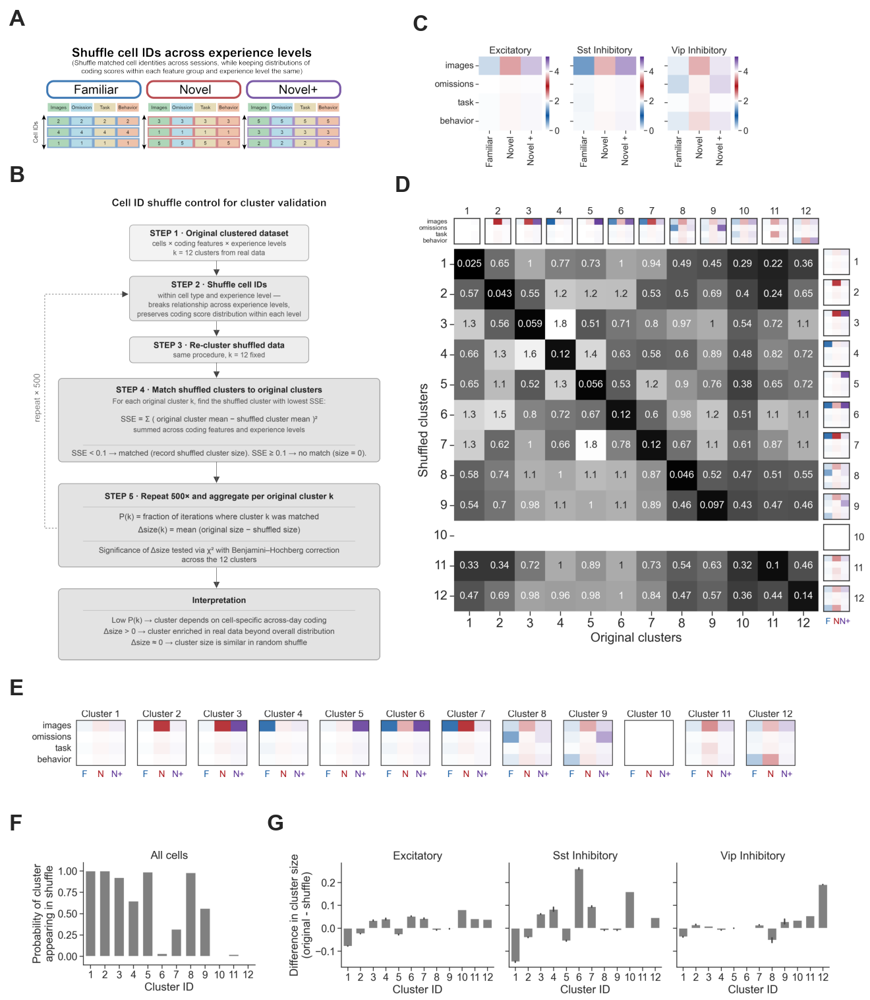

In [86]:
# ============================================================================
# Figure S17 composite -- Shuffle control for experience-dependent coding clusters.
# Layout authority: VBO figures - revised v6.pptx, slide 22 (S17).
# Panels:
#   A,B  schematics (image files; A=cell_id_shuffle_diagram, B=shuffle_control_schematic_grayscale)
#   C    plotting.plot_mean_shuffled_feature_matrix       (3 cell-type coding-score heatmaps)
#   D    plotting.plot_cluster_heatmaps_with_SSE_matrix   (12x12 SSE matrix + marginal means)
#   E    plotting.plot_matched_clusters_heatmap_remapped  (12 matched shuffled-cluster heatmaps)
#   F    plotting.plot_cluster_probability_for_shuffle    (probability_df; all cells)
#   G    plotting.plot_cluster_size_difference_for_shuffle(cluster_size_diff_cre; per cre line)
# Build method (image-tiling): each C-G function is run to produce its OWN standalone figure,
# which is captured to an image, autocropped, and tiled into a measured region. This avoids
# refactoring the 5 functions (each builds its own gridspec / colorbars / suptitle).
# PREREQ: run the "Shuffle Control Analysis" cells (126-127) above first, so these exist:
#   shuffled_feature_matrices, original_cluster_meta, original_cluster_means,
#   shuffled_cluster_means, SSE_matrix_sorted, shuffled_clusters_dict,
#   probability_df, cluster_size_diff_cre
# ============================================================================
import io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from visual_behavior.visualization.panel_grid import fig_setup, panel, check_label_overlap
sns.set_context('notebook', font_scale=1.5)

# ---- configurable constants ----
A_PATH = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 5/cell_id_shuffle_diagram.png'
B_PATH = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 5/shuffle_control_schematic_grayscale.png'
CAPTURE_DPI = 200          # render resolution for the captured C-G panels

FIG_W, FIG_H = 13.0, 15.25         # derived from the slide crop aspect (0.853, portrait)
# Placement: each panel image is dropped into a panel() axes, which reserves the skill's
# label gutter (letter only) at the top-left; the image (aspect preserved, NW-anchored)
# sits below/right of the gutter so the letter never overlaps content. check_label_overlap
# audits it. decoration_pt=(0,0) because each captured image already carries its own
# axis labels/ticks (no extra left setback needed).

# measured slide geometry (slide 22; slide fraction, y top-down): letter anchor -> content box
RAW = {
    'A': (0.001, 0.013, 0.439, 0.151),
    'B': (0.000, 0.148, 0.449, 0.583),
    'C': (0.472, 0.014, 0.915, 0.150),
    'D': (0.449, 0.155, 0.997, 0.594),
    'E': (0.001, 0.596, 0.922, 0.704),
    'F': (0.001, 0.713, 0.293, 0.874),   # right edge trimmed from .310 to clear G's letter
    'G': (0.300, 0.713, 0.966, 0.875),
}
_cx0, _cx1, _cy0, _cy1 = 0.0, 0.997, 0.005, 0.882
def _to_region(x0, y0, x1, y1):
    return [(x0-_cx0)/(_cx1-_cx0), (x1-_cx0)/(_cx1-_cx0),
            (y0-_cy0)/(_cy1-_cy0), (y1-_cy0)/(_cy1-_cy0)]
REGIONS = {k: _to_region(*v) for k, v in RAW.items()}

# ---- capture helpers ----
def _capture(plot_call, post=None):
    """Run a plotting fn that creates its own figure; return the rendered figure as an image.
    `post(fig)` is an optional hook to tweak the figure (e.g. strip a suptitle/xlabel) before capture."""
    pre = set(plt.get_fignums())
    plot_call()
    new = [n for n in plt.get_fignums() if n not in pre]
    fig = plt.figure(new[-1] if new else plt.get_fignums()[-1])
    if post is not None:
        post(fig)
    buf = io.BytesIO()
    fig.savefig(buf, dpi=CAPTURE_DPI, bbox_inches='tight', facecolor='white', format='png')
    plt.close(fig); buf.seek(0)
    return mpimg.imread(buf)

def _strip_C(fig):
    """Panel C: remove the 'Cell ID shuffle' suptitle and the 'experience_level' xlabels."""
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_visible(False)
    for ax in fig.axes:
        if ax.get_xlabel() == 'experience_level':
            ax.set_xlabel('')

def _autocrop(im, thresh=0.985):
    rgb = im[..., :3] if (im.ndim == 3 and im.shape[2] >= 3) else im
    mask = (rgb < thresh).any(axis=2) if rgb.ndim == 3 else (rgb < thresh)
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return im
    return im[ys.min():ys.max()+1, xs.min():xs.max()+1]

# ---- render C-G to images ----
img = {}
img['C'] = _autocrop(_capture(lambda: plotting.plot_mean_shuffled_feature_matrix(
    shuffled_feature_matrices, original_cluster_meta, session_colors=True, experience_index=None),
    post=_strip_C))
img['D'] = _autocrop(_capture(lambda: plotting.plot_cluster_heatmaps_with_SSE_matrix(
    original_cluster_means, shuffled_cluster_means, SSE_matrix_sorted,
    session_colors=True, experience_index=None)))
img['E'] = _autocrop(_capture(lambda: plotting.plot_matched_clusters_heatmap_remapped(
    shuffled_clusters_dict, abbreviate_features=False, abbreviate_experience=True,
    small_fontsize=False, session_colors=True)))
img['F'] = _autocrop(_capture(lambda: plotting.plot_cluster_probability_for_shuffle(probability_df)))
img['G'] = _autocrop(_capture(lambda: plotting.plot_cluster_size_difference_for_shuffle(
    cluster_size_diff_cre, y='abs_cluster_size_diff')))
img['A'] = mpimg.imread(A_PATH)
img['B'] = mpimg.imread(B_PATH)

# ---- assemble (gutter-aware: panel() reserves the letter gutter; image sits below/right) ----
fig = plt.figure(figsize=(FIG_W, FIG_H))
fig_setup(fig)
for lbl in 'ABCDEFG':
    R = REGIONS[lbl]
    ax = panel(fig, R[:2], R[2:], lbl, decoration_pt=(0, 0))
    ax.imshow(img[lbl])           # aspect preserved (imshow default 'equal')
    ax.set_anchor('NW')           # top-left within the gutter-inset box, next to the letter
    ax.axis('off')
check_label_overlap(fig, REGIONS)

utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_S17_composite', formats=['.png', '.pdf'])
plt.show()


### Figure S18 composite

Clustering results using three sequential familiar sessions. Layout authority: VBO figures - revised v6.pptx, slide 23. A experimental-design schematic, B familiar co-clustering matrix, C familiar gap statistic, D-I one `plot_cluster_properties_combined(familiar_only=True, add_depth=False, percent_cells_by_feature=True)` call (D heatmap, E cluster means, F % cells Exc/Sst/Vip, G/H/I image/change/omission population averages, Familiar 1/2/3 overlaid).

In [87]:
# ==========================================================================
# Familiar-session response mdfs for S18 panels G/H/I.
# plot_cluster_properties_combined(familiar_only=True) colors 3 hue levels from
# 'experience_level'. cells_table_familiar already relabels these to
# 'Familiar 1/2/3' (one per matched familiar ACTIVE session). The standard platform
# table keeps only the closest active familiar session, so we load the raw saved
# multi_session_df and limit to the familiar-matched (experiment, cell) pairs
# ourselves, then overwrite experience_level with the Familiar 1/2/3 label.
# >>> VERIFY the diagnostics below: ~3 rows/cell and hue levels Familiar 1/2/3. <<<
# (If your familiar mdfs are built elsewhere, point the block cell at those instead.)
# ==========================================================================
# identifier ('{oeid}_{csid}') -> Familiar 1/2/3 label, from the matched-familiar table
fam_label = cells_table_familiar[['ophys_experiment_id', 'experience_level']].copy()

def _build_familiar_mdf(conditions, keep_col, keep_val):
    df = loading.load_multi_session_df(
        data_type=data_type, event_type='all', conditions=conditions,
        inclusion_criteria=inclusion_criteria, interpolate=interpolate,
        output_sampling_rate=output_sampling_rate, epoch_duration_mins=None)
    df = df[df[keep_col] == keep_val].copy()
    df['identifier'] = df.ophys_experiment_id.astype(str) + '_' + df.cell_specimen_id.astype(str)
    df = df.set_index('identifier')
    if 'experience_level' in df.columns:
        df = df.drop(columns=['experience_level'])
    # inner-join keeps only matched familiar (experiment, cell) pairs + the Familiar 1/2/3 label
    df = df.join(fam_label[['experience_level']], how='inner').reset_index()
    df = df.merge(cluster_meta_familiar.reset_index()[['cell_specimen_id', 'cluster_id', 'cre_line']],
                  on='cell_specimen_id')
    return df

change_mdf_familiar   = _build_familiar_mdf(['cell_specimen_id', 'is_change'], 'is_change', True)
image_mdf_familiar    = _build_familiar_mdf(['cell_specimen_id', 'is_change'], 'is_change', False)
omission_mdf_familiar = _build_familiar_mdf(['cell_specimen_id', 'omitted'],   'omitted',   True)

for nm, d in [('image', image_mdf_familiar), ('change', change_mdf_familiar),
              ('omission', omission_mdf_familiar)]:
    n_cells = max(d.cell_specimen_id.nunique(), 1)
    print(f"{nm:9s} rows={len(d):6d} | hue={sorted(d.experience_level.unique())} "
          f"| rows/cell={len(d)/n_cells:.2f}")


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
image     rows=  4182 | hue=['Familiar 1', 'Familiar 2', 'Familiar 3'] | rows/cell=3.00
change    rows=  4182 | hue=['Familiar 1', 'Familiar 2', 'Familiar 3'] | rows/cell=3.00
omission  rows=  4182 | hue=['Familiar 1', 'Familiar 2', 'Familiar 3'] | rows/cell=3.00


10


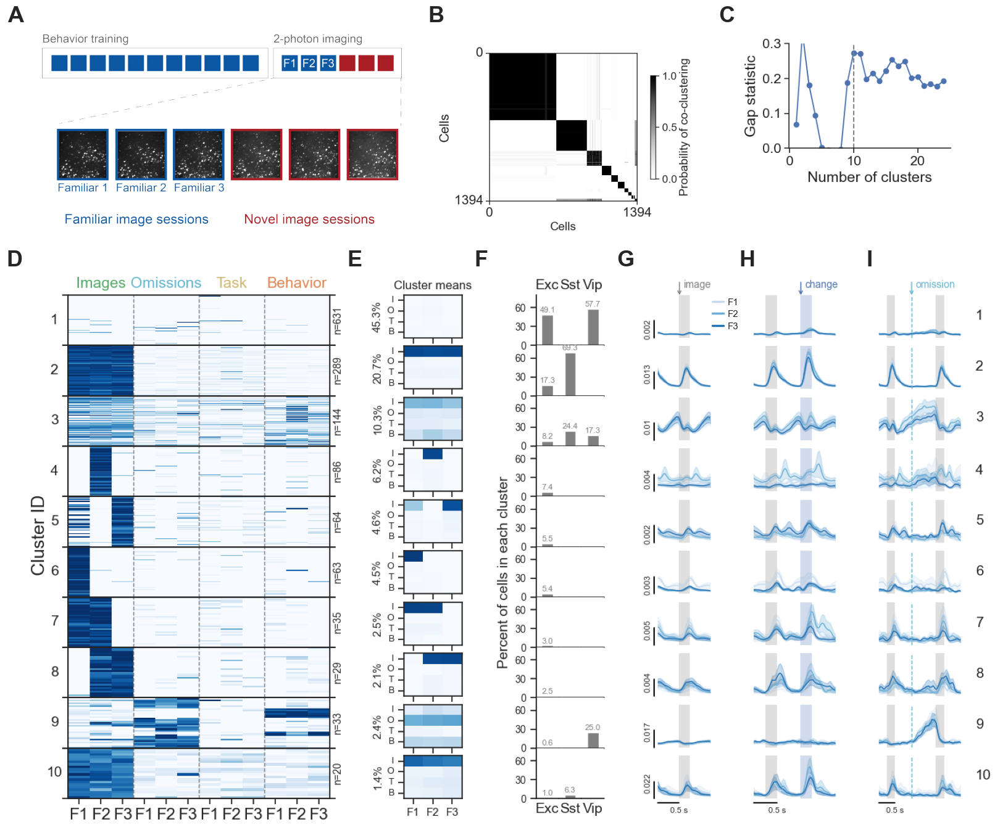

In [88]:
# ==========================================================================
# Figure S18 composite. Layout authority: VBO figures - revised v6.pptx, slide 23.
# Each source (A schematic, B coclustering, C gap, D-I block) is rendered to an
# image and placed in its measured slide box; panel letters drawn at the slide's
# letter anchors. Mirrors the S19 image-tiling approach (the D-I block builds its
# own grid, so we tile rather than embed live).
# NOTE: restart kernel / re-run imports so the updated plotting fn
# (percent_cells_by_feature) is loaded. Requires the familiar mdf prep cell above.
# ==========================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

SCHEMATIC_PATH = ('/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/'
                  'FinalDataAssetsforCodeOcean/schematics/Figure 5/'
                  'experimental_design_familiar_only_2.png')

# ---- slide-23 geometry (fractions of the 7.5 x 10 in portrait slide) ----
CROP = dict(x0=0.0, x1=0.97, y0=0.008, y1=0.652)
SLIDE_W_IN, SLIDE_H_IN = 7.5, 10.0
CONTENT = {  # (sx0, sy0, sx1, sy1) slide fraction
    'A':     (0.035, 0.028, 0.388, 0.162),
    'B':     (0.413, 0.037, 0.690, 0.180),
    'C':     (0.710, 0.030, 0.943, 0.150),
    'block': (0.020, 0.205, 0.970, 0.652),
}
LETTERS = {  # (sx, sy) slide fraction (top-left of the letter)
    'A': (0.002, 0.008), 'B': (0.414, 0.008), 'C': (0.700, 0.008),
    # D-I estimated for the new column widths; nudge these to align over the block columns
    'D': (0.000, 0.188), 'E': (0.335, 0.188), 'F': (0.460, 0.188),
    'G': (0.600, 0.188), 'H': (0.720, 0.188), 'I': (0.845, 0.188),
}
LETTER_FS = 26
FIG_W = 16.0

cw = CROP['x1'] - CROP['x0']; ch = CROP['y1'] - CROP['y0']
aspect = (cw * SLIDE_W_IN) / (ch * SLIDE_H_IN)
FIG_H = FIG_W / aspect

def _box(sx0, sy0, sx1, sy1):
    fx0 = (sx0 - CROP['x0']) / cw; fx1 = (sx1 - CROP['x0']) / cw
    fy0 = (sy0 - CROP['y0']) / ch; fy1 = (sy1 - CROP['y0']) / ch
    return [fx0, 1 - fy1, fx1 - fx0, fy1 - fy0]

def _letter_xy(sx, sy):
    return (sx - CROP['x0']) / cw, 1 - (sy - CROP['y0']) / ch

def _crop(img, pad=6, axes='both'):
    """Remove surrounding white margin. axes='v' crops top/bottom only;
    'both' also crops left/right (used for the D-I block so its content fills
    the full width instead of leaving the dropped depth column's whitespace)."""
    arr = np.asarray(img)
    thresh = 0.98 if arr.dtype.kind == 'f' else 250
    mask = ~(arr[..., :3] >= thresh).all(axis=2)
    rows = np.where(mask.any(axis=1))[0]
    if len(rows) == 0:
        return arr
    r0, r1 = max(rows[0]-pad, 0), min(rows[-1]+pad+1, arr.shape[0])
    if axes == 'both':
        cols = np.where(mask.any(axis=0))[0]
        c0, c1 = max(cols[0]-pad, 0), min(cols[-1]+pad+1, arr.shape[1])
        return arr[r0:r1, c0:c1]
    return arr[r0:r1]

def _fig_to_img(fig, axes='v'):
    fig.canvas.draw()
    return _crop(np.asarray(fig.canvas.buffer_rgba()), axes=axes)

cluster_order_fam = np.sort(cluster_meta_familiar.cluster_id.unique())

# ---- B: familiar co-clustering matrix ----
coclust_path = os.path.join(save_dir_familiar,
                            f'coclustering_matrix_n_{n_clusters_familiar}_clusters.h5')
coclust_df = pd.read_hdf(coclust_path, key='df')
_cm_all = cluster_meta_familiar.copy(); _cm_all['cre_line'] = 'all'
figB, axB = plt.subplots(figsize=(6, 6))
plotting.plot_coclustering_matrix_sorted_by_cluster_size(
    {'all': coclust_df}, _cm_all, cre_line='all', ax=axB)
axB.set_xlabel('Cells'); axB.set_ylabel('Cells'); axB.set_title('')
figB.tight_layout()
# colorbar: smaller, nudged right (gap from heatmap so it stops clipping the
# matrix tick labels), with visible spines
_cax = [a for a in figB.axes if a is not axB]
if _cax:
    _cb = _cax[0]; _p = _cb.get_position()
    _cb.set_position([_p.x0 + 0.015, _p.y0 + 0.20 * _p.height,
                      _p.width * 0.55, _p.height * 0.60])
    _cb.set_ylabel('Probability of co-clustering')
    for _sp in _cb.spines.values():
        _sp.set_visible(True); _sp.set_edgecolor('black'); _sp.set_linewidth(0.8)
imgB = _fig_to_img(figB); plt.close(figB)

# ---- C: familiar gap statistic (gap curve only, to match slide) ----
figC, axC = plt.subplots(figsize=(4, 3))
_gap = gap_statistic_familiar['gap']
axC.plot(np.arange(1, len(_gap) + 1), _gap, 'o-')
axC.axvline(n_clusters_familiar, linestyle='--', color='gray')
axC.set_xlabel('Number of clusters'); axC.set_ylabel('Gap statistic'); axC.set_ylim(0, 0.3)
sns.despine(ax=axC)
figC.tight_layout()
imgC = _fig_to_img(figC); plt.close(figC)

# ---- D-I block: single combined figure (heatmap, means, %cells, pop avgs) ----
figBlk = plotting.plot_cluster_properties_combined(
    cluster_meta_familiar, feature_matrix_familiar, 'all',
    image_mdf_familiar, change_mdf_familiar, omission_mdf_familiar,
    familiar_only=True, add_depth=False, percent_cells_by_feature=True,
    cluster_order=cluster_order_fam, sort_by=None, show_suptitle=False, save_dir=None,
    heatmap_xspan=(0.0, 0.26), means_xspan=(0.33, 0.39),
    percent_cells_xspan=(0.46, 0.53),
    response_xspan=(0.585, 0.88), response_wspace=0.6,
    heatmap_ylabel_x=-1.3, apply_peak_threshold=True)
imgBlk = _fig_to_img(figBlk, axes='both'); plt.close(figBlk)

# ---- A: schematic ----
imgA = mpimg.imread(SCHEMATIC_PATH)

# ---- assemble ----
# Preserve each image's NATIVE aspect ratio: anchor at the slide box top-left, use
# the slide box width, derive height from the image's pixel aspect (so nothing is
# stretched). aspect='auto' then fills the box exactly without distortion.
def _box_native(sx0, sy0, sx1, sy1, img):
    w_frac = (sx1 - sx0) / cw
    h_px, w_px = img.shape[0], img.shape[1]
    h_frac = w_frac * (h_px / w_px) * (FIG_W / FIG_H)
    fx0 = (sx0 - CROP['x0']) / cw
    fy0_top = (sy0 - CROP['y0']) / ch
    return [fx0, 1 - (fy0_top + h_frac), w_frac, h_frac]

fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor='white')
for key, img in [('A', imgA), ('B', imgB), ('C', imgC), ('block', imgBlk)]:
    a = fig.add_axes(_box_native(*CONTENT[key], img))
    a.imshow(img, aspect='auto')
    a.axis('off')
for lbl, (sx, sy) in LETTERS.items():
    lx, ly = _letter_xy(sx, sy)
    fig.text(lx, ly, lbl, ha='left', va='top', fontsize=LETTER_FS, fontweight='bold')

# F1/F2/F3 session legend, stacked vertically, in the top-right corner of panel G's
# top (cluster 1) axis. Colors match the Blues(3) palette used for the G-I traces
# (F1 lightest -> F3 darkest).
from matplotlib.lines import Line2D
_blues = sns.color_palette('Blues', 3)
_handles = [Line2D([0], [0], color=_blues[i], lw=2.5) for i in range(3)]
# host axes' top-right corner sits at panel G's upper-right (right of the traces,
# below the 'image' label); bbox_to_anchor=(1,1) pins the legend into that corner
_leg_ax = fig.add_axes([0.690, 0.620, 0.060, 0.055]); _leg_ax.axis('off')
_leg_ax.legend(_handles, ['F1', 'F2', 'F3'], loc='upper right', bbox_to_anchor=(1, 1),
               ncol=1, frameon=False, handlelength=1.2, labelspacing=0.35,
               handletextpad=0.4, fontsize=11)

utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_S18_composite', formats=['.png', '.pdf'])
plt.show()


### Figure S19 composite

Clusters split by cell type and sorted by cluster size. Three cell-type blocks (Excitatory/Sst/Vip), each = `plot_cluster_properties_combined` (panels A coding heatmap, B cluster means, C cluster sizes, D population averages, E depth distribution), tiled vertically. The depth column shares the cluster-row grid so each cluster is the same row across A-E.

9
7
6


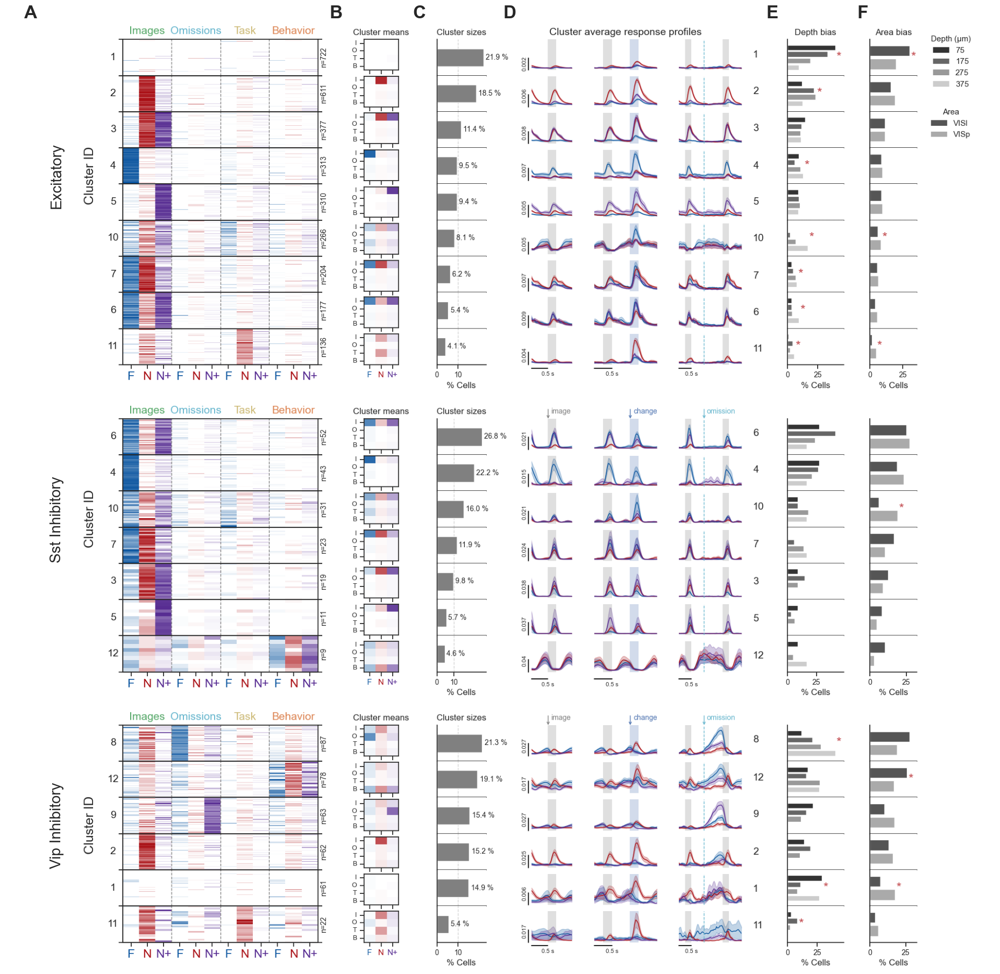

In [89]:
# ==========================================================================
# Figure S19 composite  (Clusters split by cell type and sorted by cluster size).
# Layout authority: VBO figures - revised v6.pptx, slide 24.
# Three cell-type blocks (Excitatory / Sst / Vip) stacked vertically. Each block is
# one plot_cluster_properties_combined() figure: panels A coding-score heatmap,
# B cluster means, C cluster sizes, D population averages, E depth distribution,
# F area distribution (VISp/VISl; same row grid as E).
# The depth column (E) shares the same dim=(n_clusters,1) grid as the heatmaps, so a
# given cluster is always the same row across A-E. Blocks are rendered to images,
# vertically auto-cropped (removes each figure's top/bottom whitespace so blocks sit
# close together), and tiled with heights proportional to each cre's n_clusters.
# NOTE: restart kernel / re-run the imports cell so the updated combined fn (depth
# column + show_suptitle) is loaded before rendering.
# ==========================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

CRE_LINES = utils.get_cre_lines()                    # [Excitatory, Sst, Vip], top -> bottom
# column-left x-fracs, in units of the original 18-in block width (rescaled below by SCALE)
PANEL_LETTER_X = {'A': 0.02, 'B': 0.345, 'C': 0.434, 'D': 0.53, 'E': 0.81, 'F': 0.907}
# per-cre downward shift of the "0.5 s" scale bar (line + label together); Sst sits high
SCALEBAR_SHIFT = {'Sst-IRES-Cre': 0.12}

LEFT = 0.03        # small left margin
TOP = 0.97         # room for panel letters
HSPACE = 0.02      # gap between blocks (most whitespace removed by crop below)
CROP_PAD = 6       # px padding kept around content when cropping
LETTER_FS = 24
PANEL_LETTER_Y = 0.985   # y (figure fraction) for the A-E panel letters
CT_FS = 20         # cell-type labels: bigger, not bold
CT_LABEL_X = 0.055  # axes-fraction x for the rotated label (just left of panel A's "Cluster ID" y-label)
# cell-type label y is measured per block from the rendered panel-A "Cluster ID" label (see below)


def _vcrop(img, pad=CROP_PAD):
    '''remove all-white rows from top/bottom of an RGBA image so blocks stack tightly; returns (img, y0)'''
    rgb = img[..., :3]
    nonwhite_rows = np.where(~(rgb >= 250).all(axis=(1, 2)))[0]
    if len(nonwhite_rows) == 0:
        return img, 0
    y0 = max(nonwhite_rows[0] - pad, 0)
    y1 = min(nonwhite_rows[-1] + pad + 1, img.shape[0])
    return img[y0:y1], y0


# clusters with >= 4% of the subclass's cells, largest first (same rule as S20 / S21)
def _s19_cluster_order(cre, min_fraction=0.04):
    counts = cluster_meta[cluster_meta.cre_line == cre].cluster_id.value_counts()
    frac = counts / counts.sum()
    return frac[frac >= min_fraction].sort_values(ascending=False).index.values


# ---- render each cell-type block (combined properties + aligned depth) to a cropped image ----
block_imgs = []
ct_label_y = []   # per block: axes-fraction y of the "Cluster ID" label center (cell-type label goes here)
for cre in CRE_LINES:
    is_exc = (cre == 'Slc17a7-IRES2-Cre')
    fb = plotting.plot_cluster_properties_combined(
        cluster_meta, feature_matrix, cre, image_mdf, change_mdf, omission_mdf,
        cluster_order=_s19_cluster_order(cre), save_dir=None, show_suptitle=False,
        scalebar_y_shift=SCALEBAR_SHIFT.get(cre, 0.0),
        show_response_labels=not is_exc,                          # Excitatory: drop image/change/omission labels
        response_panel_title='Cluster average response profiles' if is_exc else None,
        depth_top_title='Depth bias' if is_exc else None,
        add_area=True, area_top_title='Area bias' if is_exc else None,
        apply_peak_threshold=True)
    block_w_in = fb.get_figwidth()   # wider than 18 in when add_area=True
    fb.canvas.draw()
    img, y0 = _vcrop(np.asarray(fb.canvas.buffer_rgba()))
    # vertical center of panel A's "Cluster ID" text, in pixel rows from the top of the cropped image
    cid = [t for a in fb.axes for t in a.texts if t.get_text() == 'Cluster ID'][0]
    bb = cid.get_window_extent(fb.canvas.get_renderer())
    cid_row = fb.bbox.height - (bb.y0 + bb.y1) / 2 - y0
    ct_label_y.append(1 - cid_row / img.shape[0])
    block_imgs.append(img)
    plt.close(fb)

# ---- tile the blocks into one figure (height_ratios = cropped pixel heights -> no distortion) ----
heights_px = [im.shape[0] for im in block_imgs]
width_px = block_imgs[0].shape[1]
fig_w = block_w_in                 # keep the blocks at native scale
SCALE = 18.0 / block_w_in          # maps 18-in-referenced x-fracs onto the wider block
fig_h = fig_w * (sum(heights_px) / width_px) / TOP
fig = plt.figure(figsize=(fig_w, fig_h), facecolor='white')
gs = gridspec.GridSpec(len(block_imgs), 1, height_ratios=heights_px,
                       left=LEFT, right=1.0, top=TOP, bottom=0.0, hspace=HSPACE)

for i, (img, cre) in enumerate(zip(block_imgs, CRE_LINES)):
    a = fig.add_subplot(gs[i])
    a.imshow(img)
    a.axis('off')
    a.text(CT_LABEL_X * SCALE, ct_label_y[i], utils.convert_cre_line_to_cell_type(cre),
           transform=a.transAxes, rotation=90, ha='center', va='center',
           fontsize=CT_FS, fontweight='normal')

# panel letters across the top of the first block
for lbl, xf in PANEL_LETTER_X.items():
    fig.text(LEFT + xf * SCALE * (1.0 - LEFT), PANEL_LETTER_Y, lbl, ha='left', va='top',
             fontsize=LETTER_FS, fontweight='bold')

utils.save_figure(fig, (fig_w, fig_h), save_dir, 'composite', 'figure_S19_composite', formats=['.png', '.pdf'])
plt.show()


In [90]:
import numpy as np, pandas as pd
cre = 'Slc17a7-IRES2-Cre'
c5 = cluster_meta[(cluster_meta.cre_line == cre) & (cluster_meta.cluster_id == 5)].index
d = change_mdf[change_mdf.cell_specimen_id.isin(c5)].copy()
d['peak'] = d.mean_trace.apply(lambda t: np.nanmax(np.abs(np.asarray(t))))
d['base'] = d.mean_trace.apply(lambda t: np.asarray(t)[:15].mean())   # pre-change baseline proxy

hi = d.peak > 0.4
print(f'cluster 5 exc: {len(d)} traces, {int(hi.sum())} with peak > 0.4 (dropped by Method C)')
print(f'baseline of cells DROPPED (peak>0.4): {d.loc[hi,  "base"].mean():.4f}')
print(f'baseline of cells KEPT   (peak<=0.4): {d.loc[~hi, "base"].mean():.4f}')
print(f'mean baseline all cells: {d.base.mean():.4f}  |  kept only: {d.loc[~hi,"base"].mean():.4f}')

cluster 5 exc: 930 traces, 0 with peak > 0.4 (dropped by Method C)
baseline of cells DROPPED (peak>0.4): nan
baseline of cells KEPT   (peak<=0.4): 0.0016
mean baseline all cells: 0.0016  |  kept only: 0.0016


In [91]:
# --- free memory: drop the trace multi-session dataframes; the remaining composite
#     uses only the metrics tables ---
import gc
for _v in ['change_mdf', 'image_mdf', 'omission_mdf']:
    globals().pop(_v, None)
gc.collect()

229612

### Figure S20 composite

coding scores: 3553 cells, features = ['all-images', 'hits', 'image0', 'image1', 'image2', 'image3', 'image4', 'image5', 'image6', 'image7', 'licks', 'misses', 'omissions', 'pupil', 'running']


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/

panel A stats: 96 of 330 cluster x feature tests significant (BH FDR)


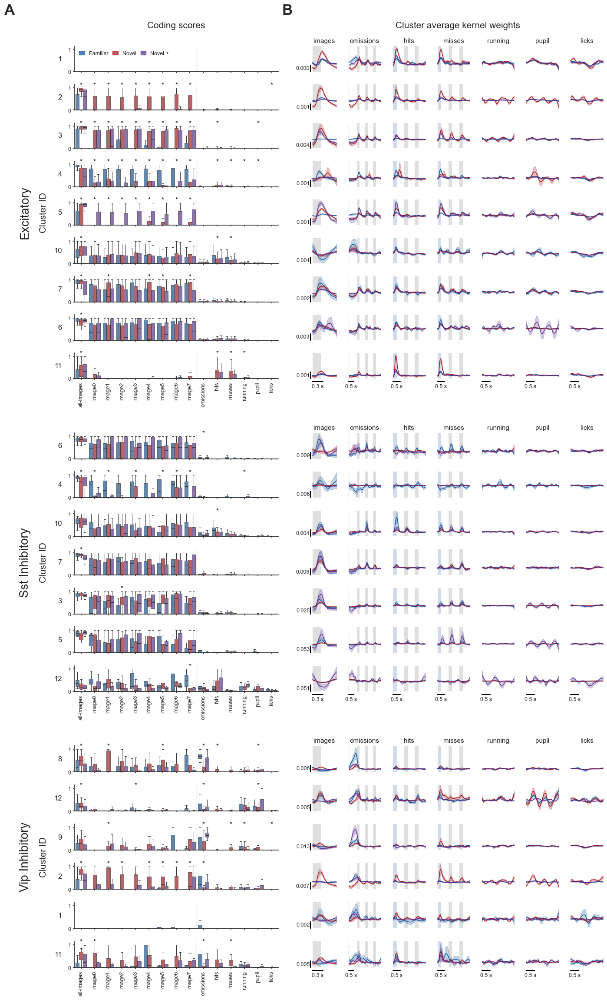

In [ ]:
# ==========================================================================
# Figure S20 composite  (Coding scores and kernels for individual features, per cluster
# within each subclass).
# Rows = clusters with >= 4% of the subclass's cells (same rule as S19/S21), largest first.
# Panel A includes coding scores for the individual images (image0-7).
# Each row:  A = coding-score distributions for individual features x F/N/N+ (S10D style;
#                within-session scores from all_results, see note below)
#            B = cluster-average kernel weights for the same 7 features (as in cell 54 / S15C)
# Blocks (Excitatory / Sst / Vip) are stacked top -> bottom, like S19.
# Deps: cluster_meta, weights_df, run_params (cell 7). results_pivoted is freed after
# cell 72, so it is reloaded here if needed; all_results is loaded here and freed after use.
# ==========================================================================
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns

FEATURES = ['all-images', 'omissions', 'hits', 'misses', 'running', 'pupil', 'licks']   # kernels (B)
ALL_IMAGE_FEATURES = [f'image{i}' for i in range(8)]   # individual-image coding scores
# saved figure name -> whether panel A includes image0-image7
VERSIONS = {'figure_S20_composite': True}
FEATURE_LABELS = {'all-images': 'images'}       # display names; others shown as-is
MIN_CLUSTER_FRACTION = 0.04

# ---- layout knobs ----
FIG_W = 14.0
ROW_H = 0.85        # inches per cluster row (was 0.75; extra room for stats stars)
HEADER_H = 0.45     # inches above each block (column titles)
TOP_EXTRA_H = 0.6   # extra inches above the first block for the panel letters + panel titles
FOOTER_H = 0.8      # inches below each block (feature tick labels / time scale bars)
LEFT, RIGHT = 0.12, 0.99
CS_W_PER_FEATURE = 0.42   # width ratio of panel A per feature (A widens when images are shown)
GAP_W = 0.3         # width ratio: gap between A and B (holds kernel y scale bars)
WSPACE, HSPACE = 0.25, 0.5   # HSPACE was 0.35; room for stars above boxes
TITLE_ABOVE_IN = 0.38      # inches from the top-row axis top to the bottom of the panel titles
LETTER_ABOVE_IN = 0.66     # inches from the top-row axis top to the bottom of the panel letters
LETTER_PAD_IN = 0.08       # gap between letter B and the kernel y scale-bar labels
BOX_ALPHA = 0.7    # boxplot transparency (matches Figure 4)
SHOW_STATS = True   # panel A: * above a feature's boxes if coding differs across F/N/N+
STAR_FS = 11
CS_YTOP = 1.15      # coding-score y-limit top (data max 1; stars sit just above 1)
TICK_FS, LABEL_FS, CLUSTER_FS = 9, 11, 12
CLUSTER_ID_LABEL_FS = 15   # 'Cluster ID' y-label
TITLE_FS = CLUSTER_ID_LABEL_FS   # panel titles ('Coding scores', 'Cluster average kernel weights')
CT_FS, LETTER_FS = 20, 24
CT_LABEL_X = 0.03           # figure-fraction x of the rotated cell-type label
CLUSTER_ID_X = -0.06        # axes-fraction x of the cluster number (left of coding panel)

exp_levels = utils.get_experience_levels()                 # ['Familiar', 'Novel', 'Novel +']
exp_colors = dict(zip(exp_levels, utils.get_experience_level_colors()))
cre_lines = utils.get_cre_lines()

# ---- clusters per subclass: >= MIN_CLUSTER_FRACTION of that subclass's cells, largest first ----
def _clusters_for_cre(cre):
    counts = cluster_meta[cluster_meta.cre_line == cre].cluster_id.value_counts()
    frac = counts / counts.sum()
    return frac[frac >= MIN_CLUSTER_FRACTION].sort_values(ascending=False).index.values

cluster_orders = {cre: _clusters_for_cre(cre) for cre in cre_lines}

# ---- per-cell coding scores for individual features ----
# Across-session normalized scores exist only for the grouped features, so individual
# features use the within-session scores in all_results (same as S10D):
# coding score = -adj_fraction_change_from_full, passive dropped, variance_explained_full > 0.
# Restricted to the (experiment, cell) pairs in the across-session results_pivoted, i.e. the
# matched sessions used for clustering, which also supplies experience_level.
if 'results_pivoted' not in globals():
    results_pivoted = pd.read_hdf(os.path.join(loading.get_glm_results_dir(),
                                  'across_session_normalized_platform_results_pivoted.h5'), key='df')
_pairs = results_pivoted[['ophys_experiment_id', 'cell_specimen_id', 'experience_level']].drop_duplicates()
_pairs['experience_level'] = _pairs.experience_level.map(utils.convert_experience_level)

_ar = pd.read_hdf(os.path.join(loading.get_glm_results_dir(), 'all_results.h5'), key='df')
_ar = _ar[_ar.dropout.isin(['all-images'] + ALL_IMAGE_FEATURES + FEATURES[1:])]
if 'passive' in _ar.columns:
    _ar = _ar[_ar.passive == False]  # noqa: E712
_ar = _ar[_ar.variance_explained_full > 0]
_ids = _ar.identifier.str.split('_', expand=True)
_ar = pd.DataFrame({'ophys_experiment_id': _ids[0].astype(int).values,
                    'cell_specimen_id': _ids[1].astype(int).values,
                    'feature': _ar.dropout.values,
                    'coding_score': -1 * _ar.adj_fraction_change_from_full.values})
coding_scores = _ar.merge(_pairs, on=['ophys_experiment_id', 'cell_specimen_id'])
_cm_cols = ['cell_specimen_id', 'cluster_id', 'cre_line'] + (['mouse_id'] if 'mouse_id' in cluster_meta.columns else [])
coding_scores = coding_scores.merge(cluster_meta.reset_index()[_cm_cols], on='cell_specimen_id')
if 'mouse_id' not in coding_scores.columns and 'mouse_id' in results_pivoted.columns:   # MLM grouping variable
    coding_scores = coding_scores.merge(results_pivoted[['cell_specimen_id', 'mouse_id']].drop_duplicates(),
                                        on='cell_specimen_id')
del _ar, _ids
gc.collect()
print(f"coding scores: {coding_scores.cell_specimen_id.nunique()} cells, features = {sorted(coding_scores.feature.unique())}")

# weights_df / run_params are freed by the memory cell after S21; reload them (as in cell 7) if this
# cell is re-run after that
if 'run_params' not in globals():
    run_params = pd.read_pickle(os.path.join(loading.get_glm_results_dir(), glm_version + '_run_params.pkl'))
if 'weights_df' not in globals():
    weights_df = pd.read_hdf(os.path.join(loading.get_glm_results_dir(), 'platform_results_weights_df.h5'), key='df')
    weights_df['experience_level'] = [utils.convert_experience_level(e) for e in weights_df.experience_level.values]
    weights_df = weights_df.merge(platform_experiments[['cell_type']], on='ophys_experiment_id', how='left')
    weights_df = weights_df.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']],
                                  on='cell_specimen_id', how='left')

# ---- kernel helpers (same conventions as plotting.plot_cluster_kernel_overlays_by_experience) ----
def _kernel_timestamps(name):
    key = 'image0' if name == 'all-images' else name
    kp = run_params['kernels'][key]
    ts = np.round(np.arange(kp['offset'], kp['offset'] + kp['length'], 1 / 31.0), 2)
    return ts[:-1] if 'image' in name else ts

def _pad_or_trim(arr, n):
    a = np.asarray(arr)
    return a[:n] if len(a) >= n else np.pad(a, (0, n - len(a)), constant_values=np.nan)

kernel_ts = {k: _kernel_timestamps(k) for k in FEATURES}
kernel_widths = [1 if (kernel_ts[k][-1] - kernel_ts[k][0]) > 1.5 else 0.75 for k in FEATURES]

# ---- figure (one per version) ----
for fig_name, show_images in VERSIONS.items():
    IMAGE_FEATURES = ALL_IMAGE_FEATURES if show_images else []
    CS_FEATURES = ['all-images'] + IMAGE_FEATURES + FEATURES[1:]          # panel A features
    CS_W = CS_W_PER_FEATURE * len(CS_FEATURES)
    # ---- panel A stats: per cell type x cluster x feature, F/N/N+ compared (MLM, mouse random
    # intercept; Holm pairwise). All tests in panel A = one family -> Benjamini-Hochberg FDR.
    cs_sig = {}
    if SHOW_STATS:
        _groups, _keys = [], []
        for cre in cre_lines:
            _ct = utils.convert_cre_line_to_cell_type(cre)
            _cs = coding_scores[coding_scores.cre_line == cre]
            for cid in cluster_orders[cre]:
                _cl = _cs[_cs.cluster_id == cid]
                for f in CS_FEATURES:
                    _groups.append((_cl[_cl.feature == f], _ct,
                                    dict(condition='cluster_id', data_subset=cid, feature=f)))
                    _keys.append((cre, cid, f))
        _sig, cs_stats = plotting.experience_stats_fdr(_groups, 'coding_score')
        cs_sig = dict(zip(_keys, _sig))
        if save_dir:
            from visual_behavior.visualization.ophys import platform_paper_figures as _ppf
            _sd = os.path.join(save_dir, 'composite', 'figure_S20_stats'); os.makedirs(_sd, exist_ok=True)
            cs_stats.to_csv(os.path.join(_sd, 'coding_score_by_cluster_feature' + _ppf._stats_suffix_for_table(cs_stats)),
                            index=False)
        print(f'panel A stats: {sum(_sig)} of {len(_sig)} cluster x feature tests significant (BH FDR)')

    plt.close('all')
    header_h = [HEADER_H + (TOP_EXTRA_H if b == 0 else 0) for b in range(len(cre_lines))]
    block_h = [header_h[b] + len(cluster_orders[c]) * ROW_H + FOOTER_H for b, c in enumerate(cre_lines)]
    FIG_H = sum(block_h)
    fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor='white')
    outer = gridspec.GridSpec(len(cre_lines), 1, height_ratios=block_h, hspace=0,
                              left=LEFT, right=RIGHT, top=1, bottom=0, figure=fig)

    first_axes = {}     # for panel letters
    sb_texts = []       # kernel y scale-bar labels (letter B goes left of these)
    for b, cre in enumerate(cre_lines):
        cell_type = utils.convert_cre_line_to_cell_type(cre)
        clusters = cluster_orders[cre]
        n = len(clusters)
        block = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=outer[b], hspace=0,
                                                 height_ratios=[header_h[b], n * ROW_H, FOOTER_H])
        rows = gridspec.GridSpecFromSubplotSpec(n, 2 + len(FEATURES), subplot_spec=block[1],
                                                width_ratios=[CS_W, GAP_W] + kernel_widths,
                                                wspace=WSPACE, hspace=HSPACE)
        cs_ct = coding_scores[coding_scores.cre_line == cre]
        w_ct = weights_df[(weights_df.cell_type == cell_type) & weights_df.experience_level.notna()]

        for r, cid in enumerate(clusters):
            top, bottom = (r == 0), (r == n - 1)

            # --- A: coding-score distributions ---
            ax = fig.add_subplot(rows[r, 0])
            sns.boxplot(data=cs_ct[cs_ct.cluster_id == cid], x='feature', y='coding_score',
                        hue='experience_level', order=CS_FEATURES, hue_order=exp_levels, palette=exp_colors,
                        showfliers=False, notch=True, width=0.8, linewidth=0.7, ax=ax)
            if ax.get_legend() is not None:
                ax.get_legend().remove()
            for _box in list(ax.patches) + list(ax.collections):   # Figure 4 style transparency
                _box.set_alpha(BOX_ALPHA)
            ax.set_ylim(0, CS_YTOP)
            for _j, f in enumerate(CS_FEATURES):
                if cs_sig.get((cre, cid, f), False):
                    ax.text(_j, 1.0, '*', fontsize=STAR_FS, ha='center', va='bottom', color='k')
            if IMAGE_FEATURES:   # separate image features from the rest
                ax.axvline(len(IMAGE_FEATURES) + 0.5, color='gray', linestyle='--', linewidth=0.8)
            ax.set_yticks([0, 1])
            ax.tick_params(axis='both', labelsize=TICK_FS, length=2)
            ax.set_xlabel('')
            ax.set_ylabel('')
            if bottom:
                ax.set_xticks(range(len(CS_FEATURES)))
                ax.set_xticklabels(CS_FEATURES, rotation=90)   # raw feature names ('all-images'); kernel titles in B keep FEATURE_LABELS
            else:
                ax.tick_params(labelbottom=False)
            ax.text(CLUSTER_ID_X, 0.5, str(int(cid)), transform=ax.transAxes, ha='right', va='center',
                    fontsize=CLUSTER_FS)
            sns.despine(ax=ax)
            if top:
                first_axes.setdefault('A', ax)

            # --- B: kernels (y shared across the row, one y scale bar on the first kernel) ---
            cl_w = w_ct[w_ct.cluster_id == cid]
            kaxes = []
            for c, k in enumerate(FEATURES):
                kax = fig.add_subplot(rows[r, 2 + c])
                kaxes.append(kax)
                ts = kernel_ts[k]
                col = f'{k}_weights'
                xlim = [min(float(ts[0]), -0.01), float(ts[-1])]
                for exp in exp_levels:
                    vals = [_pad_or_trim(v, len(ts)) for v in cl_w.loc[cl_w.experience_level == exp, col].values
                            if v is not None and not (isinstance(v, float) and np.isnan(v))]
                    if vals:
                        utils.plot_mean_trace(np.vstack(vals), ts, ylabel='', color=exp_colors[exp],
                                              xlim_seconds=xlim, linewidth=1, alpha=0.25, ax=kax)
                if k not in ['licks', 'running', 'pupil']:
                    utils.plot_flashes_on_trace(kax, ts, change=k in ['hits', 'misses'],
                                                omitted=k == 'omissions', linewidth=1.5)
                kax.set_xlim(*xlim)
                kax.set_xticks([]); kax.set_yticks([]); kax.set_xlabel(''); kax.set_ylabel('')
                for sp in kax.spines.values():
                    sp.set_visible(False)
                if top:
                    kax.set_title(FEATURE_LABELS.get(k, k), fontsize=LABEL_FS)
                    first_axes.setdefault('B', kax)
            # share y across the row
            lims = [a.get_ylim() for a in kaxes if a.lines]
            if lims:
                ylo, yhi = min(l[0] for l in lims), max(l[1] for l in lims)
                for a in kaxes:
                    a.set_ylim(ylo, yhi)
                a0 = kaxes[0]
                x0, x1 = a0.get_xlim(); xr = x1 - x0
                sb = (yhi - ylo) / 4
                a0.plot([x0 - xr * 0.08] * 2, [ylo, ylo + sb], color='k', linewidth=1.5, clip_on=False)
                sb_texts.append(a0.text(x0 - xr * 0.10, ylo + sb / 2, f'{sb:.3f}', ha='right', va='center',
                                        fontsize=9, clip_on=False))
            if bottom:   # time scale bars below the last row
                for a in kaxes:
                    x0, x1 = a.get_xlim(); L = min(0.5, (x1 - x0) * 0.45)
                    tr = a.get_xaxis_transform()
                    a.plot([x0, x0 + L], [-0.12, -0.12], color='k', linewidth=1.5, transform=tr, clip_on=False)
                    a.text(x0 + L / 2, -0.2, f'{L:.1f} s', ha='center', va='top', fontsize=9,
                           transform=tr, clip_on=False)
            if top and b == 0:
                kaxes_top = kaxes   # for the panel B title

        # cell-type label + 'Cluster ID', centered on this block's rows
        _bb = rows[0, 0].get_position(fig), rows[n - 1, 0].get_position(fig)
        _yc = (_bb[0].y1 + _bb[1].y0) / 2
        fig.text(CT_LABEL_X, _yc, cell_type, rotation=90, ha='left', va='center', fontsize=CT_FS)
        fig.text(CT_LABEL_X + 0.033, _yc, 'Cluster ID', rotation=90, ha='left', va='center', fontsize=CLUSTER_ID_LABEL_FS)

    # experience-level legend: upper left, inside the first coding-score axis
    first_axes['A'].legend(handles=[mpatches.Patch(color=exp_colors[e], alpha=BOX_ALPHA, label=e) for e in exp_levels],
                           loc='upper left', ncol=3, fontsize=TICK_FS,
                           frameon=False, handlelength=1, columnspacing=0.8)

    # panel titles (same height for A and B), with the panel letters above them
    _top = first_axes['A'].get_position().y1                  # top of the first row (figure fraction)
    _title_y = _top + TITLE_ABOVE_IN / FIG_H
    _letter_y = _top + LETTER_ABOVE_IN / FIG_H
    _pa = first_axes['A'].get_position()
    fig.text((_pa.x0 + _pa.x1) / 2, _title_y, 'Coding scores', ha='center', va='bottom', fontsize=TITLE_FS)
    fig.text((kaxes_top[0].get_position().x0 + kaxes_top[-1].get_position().x1) / 2, _title_y,
             'Cluster average kernel weights', ha='center', va='bottom', fontsize=TITLE_FS)
    fig.text(0.005, _letter_y, 'A', fontsize=LETTER_FS, fontweight='bold', ha='left', va='bottom')
    fig.canvas.draw()   # measure the scale-bar labels so B sits to their left
    _inv = fig.transFigure.inverted()
    _sb_left = min(_inv.transform(t.get_window_extent().get_points())[0, 0] for t in sb_texts)
    fig.text(_sb_left - LETTER_PAD_IN / FIG_W, _letter_y, 'B', fontsize=LETTER_FS, fontweight='bold',
             ha='right', va='bottom')

    utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', fig_name, formats=['.png', '.pdf'])
    plt.show()


### Figure S21 composite

Activity metrics for clusters across experience levels and cell types (left: distributions; right: mean +/- 95% CI across clusters for the preferred experience level). Built from the per-metric cells above.

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(order)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/dimensionality_reduction/clustering/plotting.py:9495: UserWarning: set_tickla

OVERLAP: axes of panel "Cr" intrudes into panel "Cr" (top gutter)
OVERLAP: axes of panel "Fr" intrudes into panel "Fr" (top gutter)


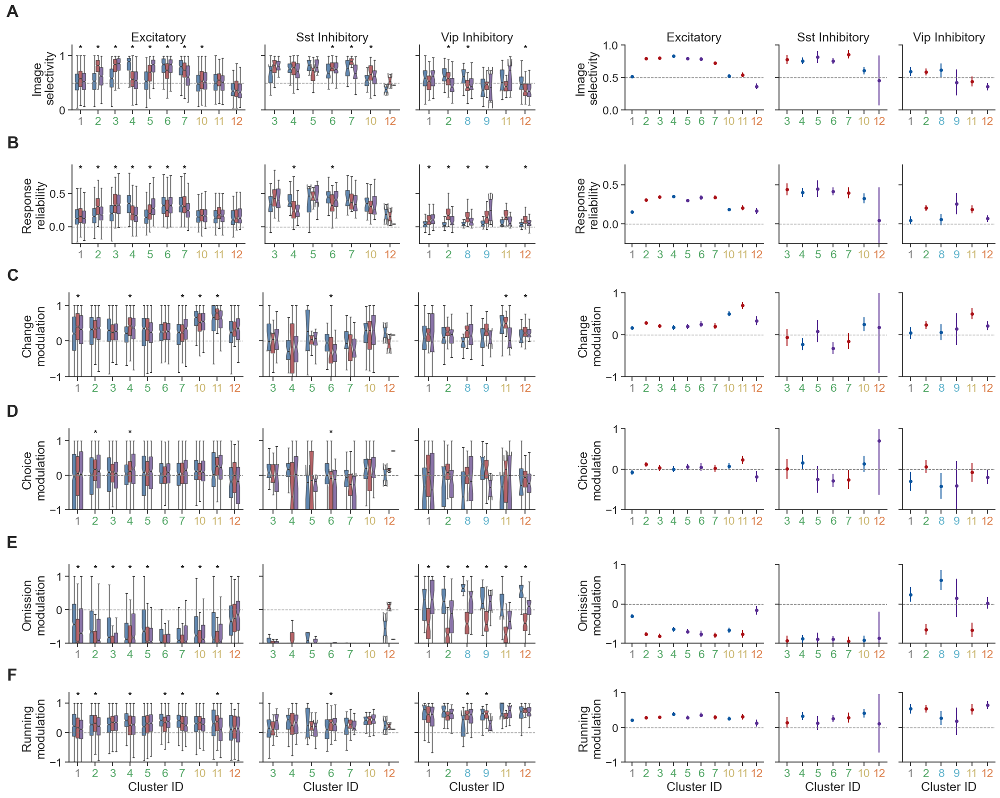

In [93]:
# ==========================================================================
# Figure S21 composite  (Activity metrics for clusters across experience levels
# and cell types).  Layout authority: VBO figures - revised v6.pptx, slide 25.
# 6 metric rows A-F. Each row = LEFT distribution boxplots (plot_response_metrics_
# boxplot_by_cre) + RIGHT mean +/- 95% CI across clusters (plot_tukey_diff_in_
# means_for_metric), each a 1x3 cre-line grid (sharey) sharing width_ratios.
# Only row A shows cell-type titles (rows B-F were covered with white boxes in pptx).
# group_to_compare is None here (no reference-cluster overlay in the composite);
# the standalone cells above keep their group comparisons.
# NOTE: restart kernel / re-run the imports cell so the embeddability guards
# (own_fig) in platform plotting fns load before rendering.
# ==========================================================================
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, check_label_overlap, auto_fit_bottom, snug_left_to_gutter)

sns.set_context('notebook', font_scale=1.5)

FIGSIZE = (20, 16)
N_ROWS = 6
ROW_H = 1.0 / N_ROWS
ROW_GAP = 0.012
LETTERS = list('ABCDEF')
WSPACE = 0.14            # whitespace within each 1x3 set
LEFT_X = (0.0, 0.535)
RIGHT_X = (0.557, 0.99)  # gap between the two sets
LEFT_DEC = 88           # left panels at fig edge: room for 2-line rotated label + ticks
RIGHT_GUT = (0, 28)     # right panels carry no letter
RIGHT_DEC = 80

# per-row metric config (order + params from the standalone cells above; ylabels 2-line)
ROWS = [
    dict(metric='lifetime_sparseness_images',   ylabel='Image\nselectivity',    line_val=0.5, lims=(0, 1)),
    dict(metric='reliability_pref_image',        ylabel='Response\nreliability', line_val=0,   lims=(-0.25, 0.75)),
    dict(metric='change_modulation_index',       ylabel='Change\nmodulation',    line_val=0,   lims=(-1, 1)),
    dict(metric='hit_miss_index',                ylabel='Choice\nmodulation',    line_val=0,   lims=(-1, 1)),
    dict(metric='omission_modulation_index',     ylabel='Omission\nmodulation',  line_val=0,   lims=(-1, 1)),
    dict(metric='running_modulation_all_images', ylabel='Running\nmodulation',   line_val=0,   lims=(-1, 1)),
]

# replicate the functions' per-cre width logic so left/right columns line up (min_cluster_fraction=0.04)
_cre_lines = utils.get_cre_lines()
cre_widths = []
for _cre in _cre_lines:
    _sub = cluster_meta[cluster_meta.cre_line == _cre]
    _ct = _sub.cluster_id.value_counts()
    _keep = _ct[_ct / _ct.sum() >= 0.04].index
    cre_widths.append(len(_keep) * 0.5)

# map measured slide-25 plot x-extents into the crop (left/right plot content extents)
_CX0, _CX1 = 0.0, 0.985

REGIONS = {}
for r in range(N_ROWS):
    top, bot = r * ROW_H, r * ROW_H + ROW_H - ROW_GAP
    REGIONS[LETTERS[r]] = [LEFT_X[0], LEFT_X[1], top, bot]
    REGIONS[LETTERS[r] + 'r'] = [RIGHT_X[0], RIGHT_X[1], top, bot]

fig = plt.figure(figsize=FIGSIZE)
fig_setup(fig)
# per-panel stats/values from the embedded component plots are written to a
# dedicated stats folder inside the composite dir, mirroring figures 2-4
stats_dir = os.path.join(save_dir, 'composite', 'figure_S21_stats') if save_dir else None
for r, cfg in enumerate(ROWS):
    L = LETTERS[r]
    is_title = (r == 0)
    is_bottom = (r == N_ROWS - 1)

    axL = panel(fig, REGIONS[L][:2], REGIONS[L][2:], L, has_title=is_title,
                dim=(1, 3), width_ratios=cre_widths, wspace=WSPACE, sharey=True,
                decoration_pt=(LEFT_DEC, 0))
    plotting.plot_response_metrics_boxplot_by_cre(
        response_metrics, cfg['metric'], cluster_meta, ylabel=cfg['ylabel'],
        horiz=True, match_clusters=False, line_val=cfg['line_val'], ylims=cfg['lims'],
        stats_dir=stats_dir, ax=axL,
        show_stats=True,   # * above a cluster if metric differs across F/N/N+ (MLM, Holm, BH)
        notch=True, box_alpha=0.7)   # match S20A box style

    axR = panel(fig, REGIONS[L + 'r'][:2], REGIONS[L + 'r'][2:], None, has_title=is_title,
                dim=(1, 3), width_ratios=cre_widths, wspace=WSPACE, sharey=True,
                gutter_pt=RIGHT_GUT, decoration_pt=(RIGHT_DEC, 0))
    for _a in axR:                      # tag the no-letter panel so fit/audit see it
        _a._panel_grid_owner = L + 'r'
    plotting.plot_tukey_diff_in_means_for_metric(
        response_metrics, cfg['metric'], cluster_meta=cluster_meta,
        match_clusters=False, min_cluster_fraction=0.04, horiz=True, lims=cfg['lims'],
        title=cfg['ylabel'], xlabel=cfg['ylabel'], group_to_compare=None, line_val=cfg['line_val'],
        pref_exp_level=True, split_by_cre=True, stats_dir=stats_dir, ax=axR)

    # sharey: hide redundant inner y-tick labels (placeAxesOnGrid sharey doesn't auto-hide)
    for _a in list(axL)[1:] + list(axR)[1:]:
        _a.tick_params(labelleft=False)
    # rows B-F: drop the redundant cell-type titles (covered in the pptx)
    if not is_title:
        for _a in list(axL) + list(axR):
            _a.set_title('')
    # keep "Cluster ID" x-labels only on the bottom row
    if not is_bottom:
        for _a in list(axL) + list(axR):
            _a.set_xlabel('')

# snug the left boxplot panels in toward the panel letters (measured -> robust to tick widths)
snug_left_to_gutter(fig, REGIONS, only=list('ABCDEF'), gutter_pt=(20, 28), pad_pt=4)
auto_fit_bottom(fig, REGIONS, pad_pt=3)
check_label_overlap(fig, REGIONS)   # right panels flag their own (letterless) gutter -- benign
utils.save_figure(fig, FIGSIZE, save_dir, 'composite', 'figure_S21_composite', formats=['.png', '.pdf'])
plt.show()


In [94]:
# --- free memory: GLM kernel weights / run_params are done being plotted ---
import gc
for _v in ['weights_df', 'run_params']:
    globals().pop(_v, None)
gc.collect()

9214

## Reviewer response figures

### Running modulation averaged across experience levels, compared across clusters
Variant of Figure S21F (left column): each cell's running modulation is averaged over F/N/N+, then clusters are compared within each cell type (MLM with mouse random intercept, Holm-corrected pairwise).

/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_22840/3603011140.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='cluster_id', y=METRIC, order=orders[cre], showfliers=False, width=0.6,
/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_22840/3603011140.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='cluster_id', y=METRIC, order=orders[cre], showfliers=False, width=0.6,
/var/folders/1t/06qd1ncj5q90vctbvq586lmh0000gp/T/ipykernel_22840/3603011140.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxp

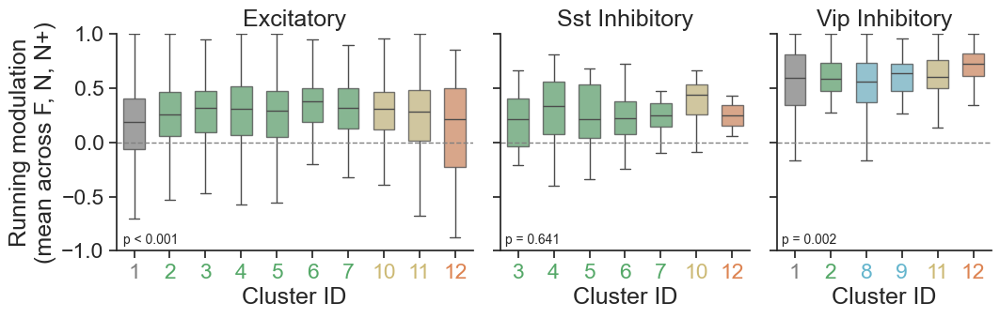

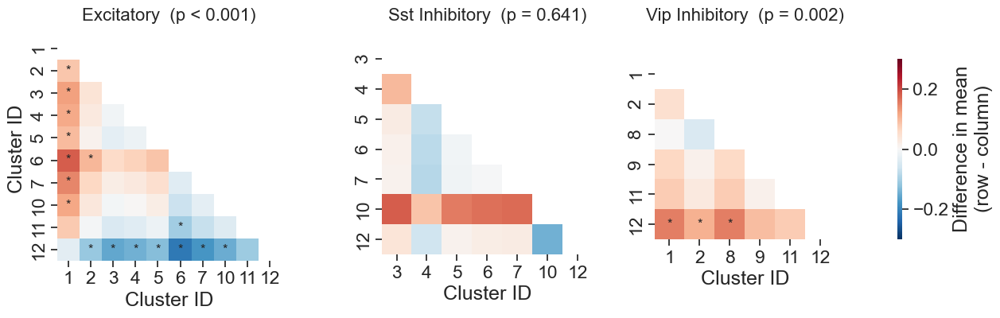

{'Excitatory': 'p < 0.001', 'Sst Inhibitory': 'p = 0.641', 'Vip Inhibitory': 'p = 0.002'}


In [95]:
# ==========================================================================
# Running modulation averaged across experience levels, compared ACROSS CLUSTERS
# (variant of Figure S21F, left column).
# Each cell's running_modulation_all_images is averaged over F/N/N+ (levels with a value),
# then per cell type: boxplots per cluster + mixed linear model (mouse random intercept)
# testing for differences across clusters, with Holm-corrected pairwise comparisons.
# Same clusters as S21 (>= 4% of the subclass, plus Exc cluster 12).
# Fig 1: boxplots with the overall (omnibus) p per cell type.
# Fig 2: pairwise matrix per cell type: color = difference in mean (row - column),
#        * = significant pairwise difference (Holm, gated on the omnibus test).
# Deps: response_metrics, cluster_meta (cells 7/11).
# ==========================================================================
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from visual_behavior.visualization.ophys import platform_paper_figures as ppf
from visual_behavior.visualization.ophys.platform_paper_stats import compute_stats

METRIC = 'running_modulation_all_images'
YLABEL = 'Running modulation\n(mean across F, N, N+)'
MIN_CLUSTER_FRACTION = 0.04
BOX_ALPHA = 0.75
cre_lines = utils.get_cre_lines()
cluster_colors = plotting.get_cluster_colors_dict()

# per-cell average across experience levels
_rm = response_metrics.copy()
if 'mouse_id' not in _rm.columns:
    _rm['mouse_id'] = _rm['cell_specimen_id'].map(cluster_meta['mouse_id'])
cell_avg = (_rm.groupby(['cell_specimen_id', 'cluster_id', 'cre_line', 'mouse_id'])[METRIC]
            .mean().dropna().reset_index())

def _keep_clusters(cre):   # same rule as plot_response_metrics_boxplot_by_cre
    counts = cluster_meta[cluster_meta.cre_line == cre].cluster_id.value_counts()
    keep = list(counts[counts / counts.sum() >= MIN_CLUSTER_FRACTION].index)
    if cre == 'Slc17a7-IRES2-Cre' and 12 not in keep:
        keep.append(12)
    return np.sort(keep)

orders = {cre: _keep_clusters(cre) for cre in cre_lines}
widths = [len(orders[cre]) for cre in cre_lines]

# ---- stats: across clusters, per cell type ----
stats_table, omnibus = pd.DataFrame(), {}
for cre in cre_lines:
    cell_type = utils.convert_cre_line_to_cell_type(cre)
    d = cell_avg[(cell_avg.cre_line == cre) & cell_avg.cluster_id.isin(orders[cre])]
    st = compute_stats(d, METRIC, column_to_compare='cluster_id', use_mlm=ppf.USE_MLM,
                       group_column='mouse_id', cell_type=cell_type)
    omnibus[cre] = ppf._heatmap_omnibus_p(st)
    stats_table = pd.concat([stats_table, st], ignore_index=True)

def _fmt_p(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'

# ---- Fig 1: boxplots per cluster ----
figsize = (12, 3)
fig, ax = plt.subplots(1, 3, figsize=figsize, sharey=True, gridspec_kw={'width_ratios': widths})
for i, cre in enumerate(cre_lines):
    d = cell_avg[(cell_avg.cre_line == cre) & cell_avg.cluster_id.isin(orders[cre])]
    sns.boxplot(data=d, x='cluster_id', y=METRIC, order=orders[cre], showfliers=False, width=0.6,
                palette=[cluster_colors[c] for c in orders[cre]], boxprops=dict(alpha=BOX_ALPHA), ax=ax[i])
    ax[i].axhline(0, color='gray', linestyle='--', linewidth=1)
    ax[i].set_ylim(-1, 1)
    for t, c in zip(ax[i].get_xticklabels(), orders[cre]):
        t.set_color(cluster_colors[c])
    ax[i].set_title(utils.convert_cre_line_to_cell_type(cre))
    ax[i].text(0.02, 0.02, _fmt_p(omnibus[cre]), transform=ax[i].transAxes, ha='left', va='bottom', fontsize=10)
    ax[i].set_xlabel('Cluster ID'); ax[i].set_ylabel('')
    sns.despine(ax=ax[i])
ax[0].set_ylabel(YLABEL)
plt.subplots_adjust(wspace=0.1)
utils.save_figure(fig, figsize, save_dir, 'running_modulation_across_clusters', METRIC + '_avg_exp_by_cluster')
plt.show()

# ---- Fig 2: pairwise comparisons across clusters ----
figsize = (13, 4.2)
fig, ax = plt.subplots(1, 4, figsize=figsize, gridspec_kw={'width_ratios': widths + [0.35]})
cax = ax[3]                                                  # dedicated colorbar axis (keeps Vip panel full size)
fig.subplots_adjust(left=0.07, right=0.93, top=0.84, bottom=0.17, wspace=0.35)
for i, cre in enumerate(cre_lines):
    cell_type = utils.convert_cre_line_to_cell_type(cre)
    order = orders[cre]
    d = cell_avg[(cell_avg.cre_line == cre) & cell_avg.cluster_id.isin(order)]
    means = d.groupby('cluster_id')[METRIC].mean()
    diff = pd.DataFrame(means.loc[order].values[:, None] - means.loc[order].values[None, :], index=order, columns=order)
    mask = np.triu(np.ones_like(diff, dtype=bool))            # lower triangle only
    sns.heatmap(diff, mask=mask, cmap='RdBu_r', vmin=-0.3, vmax=0.3, square=True, cbar=(i == 2),
                cbar_ax=cax if i == 2 else None,
                cbar_kws={'label': 'Difference in mean\n(row - column)'}, ax=ax[i])
    st = stats_table[stats_table.cell_type == cell_type]
    if omnibus[cre] < 0.05:
        pos = {c: k for k, c in enumerate(order)}
        for _, row in st[st.reject.astype(bool)].iterrows():
            r, c = sorted([pos[row.group1], pos[row.group2]], reverse=True)
            ax[i].text(c + 0.5, r + 0.5, '*', ha='center', va='center', fontsize=12)
    ax[i].set_xlabel('Cluster ID'); ax[i].set_ylabel('Cluster ID' if i == 0 else '')
# titles at one common height above the tallest heatmap (square heatmaps differ in size)
fig.canvas.draw()
_pos = [a.get_position() for a in ax[:3]]
_ytitle = max(pp.y1 for pp in _pos) + 0.04
for pp, cre in zip(_pos, cre_lines):
    fig.text((pp.x0 + pp.x1) / 2, _ytitle, f'{utils.convert_cre_line_to_cell_type(cre)}  ({_fmt_p(omnibus[cre])})',
             ha='center', va='bottom', fontsize=16)
_cp = cax.get_position()                                      # shorten colorbar to the Vip heatmap height
cax.set_position([_cp.x0, _pos[2].y0, _cp.width * 0.5, _pos[2].height])
utils.save_figure(fig, figsize, save_dir, 'running_modulation_across_clusters', METRIC + '_avg_exp_pairwise')
plt.show()

if save_dir:
    _out = os.path.join(save_dir, 'running_modulation_across_clusters'); os.makedirs(_out, exist_ok=True)
    stats_table.to_csv(os.path.join(_out, METRIC + '_avg_exp_by_cluster' + ppf._stats_suffix_for_table(stats_table)),
                       index=False)
print({utils.convert_cre_line_to_cell_type(c): _fmt_p(p) for c, p in omnibus.items()})


### Vip running modulation summary (clusters 2, 8, 9, 12)
A: running modulation index; B: running coding; C: omission coding — all by session type.

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain credentials
'LIMS_DBNAME'

         internal AIBS users should set up environment variables         appropriately
functions requiring database access will fail
  warnings.warn(warn_string)


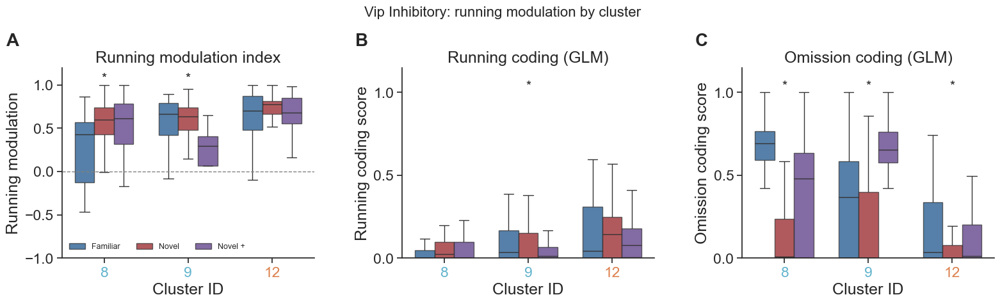

In [96]:
# ==========================================================================
# Vip running modulation summary (exploratory), selected clusters
#   A  running modulation index per cluster split by experience level
#   B  running coding scores (within-session GLM, as in S20A) split by experience level
#   C  omission coding scores split by experience level
#   * = differs across F/N/N+ (MLM + Holm, BH across the clusters shown)
# (Running vs stationary image responses are in the next section's figure.)
# Notched boxes, alpha 0.75 (as S20/S21).
# Deps: response_metrics, cluster_meta (cells 7/11). Coding scores reuse `coding_scores` from the S20
# composite cell if it exists, otherwise the running/omission scores are loaded here.
# ==========================================================================
import os
import gc
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from visual_behavior.visualization.ophys import platform_paper_figures as ppf

CRE = 'Vip-IRES-Cre'
RUN_METRIC = 'running_modulation_all_images'
CLUSTERS = [ 8, 9, 12]   # clusters to show; None = all Vip clusters with >= 4% of cells (as S21)
MIN_CLUSTER_FRACTION = 0.04
BOX_ALPHA = 0.75
LETTER_FS = 20
cell_type = utils.convert_cre_line_to_cell_type(CRE)
cluster_colors = plotting.get_cluster_colors_dict()
exp_levels = utils.get_experience_levels()
exp_colors = utils.get_experience_level_colors()

_counts = cluster_meta[cluster_meta.cre_line == CRE].cluster_id.value_counts()
order = (np.sort(_counts[_counts / _counts.sum() >= MIN_CLUSTER_FRACTION].index.values)
         if CLUSTERS is None else np.array(CLUSTERS))

def _add_mouse_id(df):
    if 'mouse_id' not in df.columns:
        df = df.copy()
        df['mouse_id'] = df['cell_specimen_id'].map(cluster_meta['mouse_id'])
    return df

# ---- data ----
rm = _add_mouse_id(response_metrics[(response_metrics.cre_line == CRE) & response_metrics.cluster_id.isin(order)])

if 'coding_scores' in globals() and {'running', 'omissions'} <= set(coding_scores.feature.unique()):
    cs = coding_scores[coding_scores.feature.isin(['running', 'omissions']) & (coding_scores.cre_line == CRE)].copy()
else:   # same definition as the S20 cell: within-session scores from all_results, matched sessions only
    if 'results_pivoted' not in globals():
        results_pivoted = pd.read_hdf(os.path.join(loading.get_glm_results_dir(),
                                      'across_session_normalized_platform_results_pivoted.h5'), key='df')
    _pairs = results_pivoted[['ophys_experiment_id', 'cell_specimen_id', 'experience_level']].drop_duplicates()
    _pairs['experience_level'] = _pairs.experience_level.map(utils.convert_experience_level)
    _ar = pd.read_hdf(os.path.join(loading.get_glm_results_dir(), 'all_results.h5'), key='df')
    _ar = _ar[_ar.dropout.isin(['running', 'omissions']) & (_ar.variance_explained_full > 0)]
    if 'passive' in _ar.columns:
        _ar = _ar[_ar.passive == False]  # noqa: E712
    _ids = _ar.identifier.str.split('_', expand=True)
    cs = pd.DataFrame({'ophys_experiment_id': _ids[0].astype(int).values,
                       'cell_specimen_id': _ids[1].astype(int).values,
                       'feature': _ar.dropout.values,
                       'coding_score': -1 * _ar.adj_fraction_change_from_full.values})
    cs = cs.merge(_pairs, on=['ophys_experiment_id', 'cell_specimen_id'])
    cs = cs.merge(cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id', 'cre_line']], on='cell_specimen_id')
    cs = cs[cs.cre_line == CRE]
    del _ar, _ids; gc.collect()
cs = _add_mouse_id(cs[cs.cluster_id.isin(order)])
run_cs, omi_cs = cs[cs.feature == 'running'], cs[cs.feature == 'omissions']

# ---- stats (experience level within each cluster) ----
def _exp_stats(df, metric):
    return plotting.experience_stats_fdr(
        [(df[df.cluster_id == c], cell_type, dict(condition='cluster_id', data_subset=c)) for c in order], metric)

sig_run, st_run = _exp_stats(rm, RUN_METRIC)
sig_runcs, st_runcs = _exp_stats(run_cs, 'coding_score')
sig_omics, st_omics = _exp_stats(omi_cs, 'coding_score')

def _color_ticks(a):
    a.set_xticks(range(len(order)))
    a.set_xticklabels(order)
    for t, c in zip(a.get_xticklabels(), order):
        t.set_color(cluster_colors[c])

def _exp_panel(a, data, y, sig, ylabel, title, coding=False, legend=False):
    sns.boxplot(data=data, x='cluster_id', y=y, order=order, hue='experience_level', hue_order=exp_levels,
                palette=exp_colors, showfliers=False, notch=False, width=0.7,
                boxprops=dict(alpha=BOX_ALPHA), ax=a)
    if coding:
        a.set_ylim(0, 1.15); a.set_yticks([0, 0.5, 1])
    else:
        a.axhline(0, color='gray', linestyle='--', linewidth=1)
        a.set_ylim(-1, 1.2); a.set_yticks([-1, -0.5, 0, 0.5, 1])
    for k, s in enumerate(sig):
        if s:
            a.text(k, 1.0, '*', ha='center', va='bottom', fontsize=15)
    a.set_ylabel(ylabel); a.set_xlabel('Cluster ID'); a.set_title(title)
    if legend:
        a.legend(loc='lower left', fontsize=9, frameon=False, ncol=3)
    elif a.get_legend() is not None:
        a.get_legend().remove()
    _color_ticks(a)
    sns.despine(ax=a)

# ---- figure ----
figsize = (16, 4.8)
fig, axes = plt.subplots(1, 3, figsize=figsize)
fig.subplots_adjust(left=0.07, right=0.98, top=0.78, bottom=0.16, wspace=0.35)
axA, axB, axC = axes

_exp_panel(axA, rm, RUN_METRIC, sig_run, 'Running modulation', 'Running modulation index', legend=True)
_exp_panel(axB, run_cs, 'coding_score', sig_runcs, 'Running coding score', 'Running coding (GLM)', coding=True)
_exp_panel(axC, omi_cs, 'coding_score', sig_omics, 'Omission coding score', 'Omission coding (GLM)', coding=True)

fig.suptitle(f'{cell_type}: running modulation by cluster', fontsize=16)

# panel letters just above each panel's full extent (title + y-label), so they never touch the axes
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_inv = fig.transFigure.inverted()
for a, L in zip((axA, axB, axC), 'ABC'):
    bb = a.get_tightbbox(_r).transformed(_inv)
    fig.text(bb.x0, bb.y1 + 0.004, L, fontsize=LETTER_FS, fontweight='bold', ha='left', va='bottom')

_sfx = '' if CLUSTERS is None else '_clusters_' + '_'.join(str(c) for c in order)
utils.save_figure(fig, figsize, save_dir, 'running_modulation_across_clusters', 'vip_running_modulation_summary' + _sfx)
plt.show()

if save_dir:
    _out = os.path.join(save_dir, 'running_modulation_across_clusters'); os.makedirs(_out, exist_ok=True)
    for _name, _t in [('vip_running_by_cluster_exp', st_run), ('vip_running_coding_by_cluster_exp', st_runcs),
                      ('vip_omission_coding_by_cluster_exp', st_omics)]:
        _t.to_csv(os.path.join(_out, _name + _sfx + ppf._stats_suffix_for_table(_t)), index=False)


### Running vs omission coding per cell (Vip, clusters 2, 8, 9, 12)
One panel per cluster (colored by experience level), then one panel per experience level (colored by cluster). Run the Vip summary cell first.

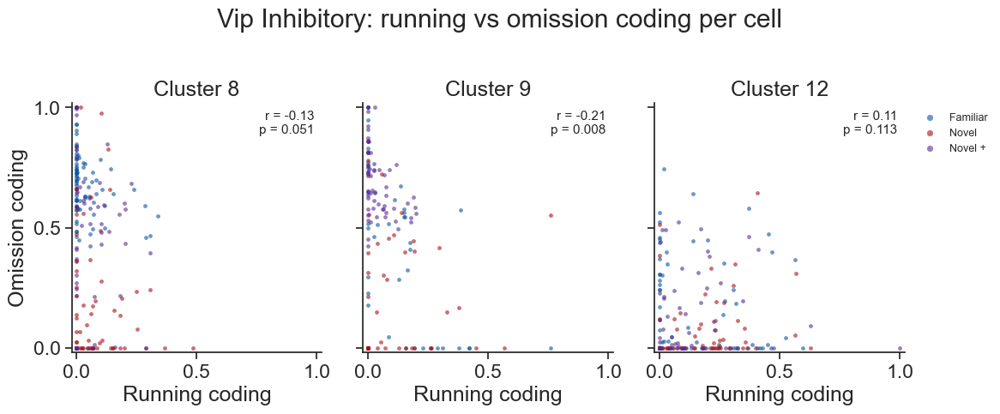

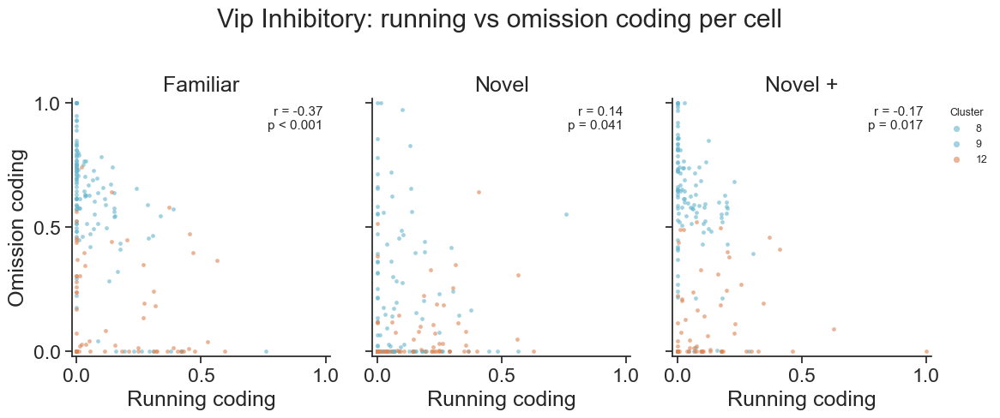

In [98]:
# ==========================================================================
# Running vs omission coding, per cell (Vip, clusters 2, 8, 9, 12)
# One point = one cell in one session (within-session GLM coding scores, as in S20A).
#   Figure 1: one panel per cluster, points colored by experience level
#   Figure 2: one panel per experience level, points colored by cluster
# Spearman r and its p-value across the points in each panel are shown in the corner
# (points are cell x session, so a cell can contribute up to 3 points).
# Deps: run the "Vip running modulation summary" cell first (uses its `cs` coding-score table).
# ==========================================================================
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

SCATTER_CLUSTERS = [8, 9, 12]
assert 'cs' in globals() and {'running', 'omissions'} <= set(cs.feature.unique()), \
    'run the Vip running modulation summary cell first'
cluster_colors = plotting.get_cluster_colors_dict()
exp_levels = utils.get_experience_levels()
exp_color_dict = dict(zip(exp_levels, utils.get_experience_level_colors()))

pts = (cs[cs.cluster_id.isin(SCATTER_CLUSTERS)]
       .pivot_table(index=['cell_specimen_id', 'cluster_id', 'experience_level'], columns='feature',
                    values='coding_score')
       .dropna(subset=['running', 'omissions']).reset_index())

def _scatter_panel(a, d, hue_col, colors, title):
    for key, col in colors.items():
        dd = d[d[hue_col] == key]
        a.scatter(dd.running, dd.omissions, s=12, color=col, alpha=0.6, linewidths=0, label=str(key))
    if len(d) > 2:
        r, p = spearmanr(d.running, d.omissions)
        _p = 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
        a.text(0.97, 0.97, f'r = {r:.2f}\n{_p}', transform=a.transAxes, ha='right', va='top', fontsize=11)
    a.set_xlim(-0.02, 1.02); a.set_ylim(-0.02, 1.02); a.set_aspect('equal')
    a.set_xticks([0, 0.5, 1]); a.set_yticks([0, 0.5, 1])
    a.set_title(title); a.set_xlabel('Running coding')
    sns.despine(ax=a)

for fig_name, panels, panel_col, hue_col, colors, title_fn in [
        ('by_cluster', SCATTER_CLUSTERS, 'cluster_id', 'experience_level', exp_color_dict, lambda v: f'Cluster {v}'),
        ('by_experience_level', exp_levels, 'experience_level', 'cluster_id',
         {c: cluster_colors[c] for c in SCATTER_CLUSTERS}, lambda v: v)]:
    figsize = (4 * len(panels), 4.6)
    fig, ax = plt.subplots(1, len(panels), figsize=figsize, sharex=True, sharey=True)
    for a, v in zip(ax, panels):
        _scatter_panel(a, pts[pts[panel_col] == v], hue_col, colors, title_fn(v))
    ax[0].set_ylabel('Omission coding')
    ax[-1].legend(title='Cluster' if hue_col == 'cluster_id' else None, fontsize=9, title_fontsize=9,
                  frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1), markerscale=1.5)
    fig.suptitle('Vip Inhibitory: running vs omission coding per cell', y=1.02)
    plt.tight_layout()
    utils.save_figure(fig, figsize, save_dir, 'running_modulation_across_clusters',
                      f'vip_running_vs_omission_coding_{fig_name}')
    plt.show()
